# 3. Análisis exploratorio de datos

Todo el análisis de esta sección usa **solo el conjunto de entrenamiento** reservado en la sección 2. Cuando se hacen muchas pruebas de hipótesis, los valores *p* se ajustan por Holm (control del error de familia) y por Benjamini-Hochberg (FDR), y siempre se reportan **tamaños de efecto**, porque con más de 30 000 registros casi cualquier diferencia resulta significativa.

**Esquema de validación temporal.** La validación cruzada interna es coherente con la partición: `TimeSeriesSplit` de cinco pliegues sobre el entrenamiento en orden cronológico (ventana creciente: siempre se ajusta con el pasado y se valida con el bloque siguiente). Entre el último registro de ajuste y el primero de validación se deja una separación (*gap*) igual al percentil 95 de los registros por día de contacto en entrenamiento, para que el bloque de validación no empiece en el mismo día en que termina el ajuste: los contactos de un mismo día comparten condiciones y sus resultados no son independientes. La validación estratificada aleatoria (`SEED`) solo aparece como contraste explícito en las secciones 3.6 y 4.10.

In [12]:
registros_dia_tr = dia_tr.value_counts()
GAP = int(np.ceil(registros_dia_tr.quantile(0.95)))
tss = TimeSeriesSplit(n_splits=5, gap=GAP)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # solo como contraste (secciones 3.6 y 4.10)

filas_pl = []
for k_, (i_ent, i_val) in enumerate(tss.split(X_tr), start=1):
    filas_pl.append({"Pliegue": k_, "Registros de ajuste": len(i_ent), "Ajusta hasta": periodo_tr.iloc[i_ent[-1]],
                     "Registros de validación": len(i_val), "Valida desde": periodo_tr.iloc[i_val[0]],
                     "Valida hasta": periodo_tr.iloc[i_val[-1]],
                     "% positivos (ajuste)": 100 * y_tr.iloc[i_ent].mean(),
                     "% positivos (validación)": 100 * y_tr.iloc[i_val].mean()})
esquema_tss = pd.DataFrame(filas_pl).set_index("Pliegue")
print(f"Separación (gap) = {GAP} registros: percentil 95 de los registros por día de contacto en entrenamiento "
      f"(mediana {num(registros_dia_tr.median())} registros por día).")
tabla(esquema_tss, dec=2)

val_2008 = esquema_tss["Valida hasta"].str.startswith("2008")
interpretar(
    f"Cada pliegue valida en un bloque de {num(esquema_tss['Registros de validación'].iloc[0])} registros; el ajuste "
    f"crece de {num(esquema_tss['Registros de ajuste'].iloc[0])} a {num(esquema_tss['Registros de ajuste'].iloc[-1])} "
    f"registros. {int(val_2008.sum())} de los cinco bloques de validación terminan en 2008 y el último va de "
    f"{esquema_tss['Valida desde'].iloc[-1]} a {esquema_tss['Valida hasta'].iloc[-1]}. La prevalencia de validación va "
    f"del {num(esquema_tss['% positivos (validación)'].min(), 1)} % al {num(esquema_tss['% positivos (validación)'].max(), 1)} %.",
    "En ese sentido, la validación temporal reproduce la situación real (predecir con el pasado), pero hereda la "
    "deriva: los bloques de 2008 tienen pocas suscripciones y condiciones económicas parecidas entre sí, mientras que "
    "el último ya incluye meses de 2009. Las métricas de validación serán más bajas y más variables que las de una "
    "validación aleatoria, y eso es parte del resultado, no un defecto del esquema.",
    "Por lo anterior, conviene usar este esquema para elegir variables, hiperparámetros y umbral (secciones 3.5, 3.7 y "
    "4) y reportar el resultado por pliegue, no solo el promedio.")

Separación (gap) = 507 registros: percentil 95 de los registros por día de contacto en entrenamiento (mediana 192 registros por día).


,Registros de ajuste,Ajusta hasta,Registros de validación,Valida desde,Valida hasta,% positivos (ajuste),% positivos (validación)
Pliegue,,,,,,,
1,4 983,2008-05,5 490,2008-05,2008-06,"2,91","3,88"
2,10 473,2008-06,5 490,2008-06,2008-07,"3,41","6,05"
3,15 963,2008-07,5 490,2008-07,2008-08,"4,27","5,92"
4,21 453,2008-08,5 490,2008-08,2008-11,"4,73","5,45"
5,26 943,2008-11,5 490,2008-11,2009-05,"4,82","14,03"


**Interpretación.** Cada pliegue valida en un bloque de 5 490 registros; el ajuste crece de 4 983 a 26 943 registros. 4 de los cinco bloques de validación terminan en 2008 y el último va de 2008-11 a 2009-05. La prevalencia de validación va del 3,9 % al 14,0 %.

En ese sentido, la validación temporal reproduce la situación real (predecir con el pasado), pero hereda la deriva: los bloques de 2008 tienen pocas suscripciones y condiciones económicas parecidas entre sí, mientras que el último ya incluye meses de 2009. Las métricas de validación serán más bajas y más variables que las de una validación aleatoria, y eso es parte del resultado, no un defecto del esquema.

Por lo anterior, conviene usar este esquema para elegir variables, hiperparámetros y umbral (secciones 3.5, 3.7 y 4) y reportar el resultado por pliegue, no solo el promedio.

## 3.1 Análisis de la variable objetivo (enunciado, sección 2.1)

,Registros,%
no suscribe (0),30 840,"93,62"
suscribe (1),2 100,"6,38"


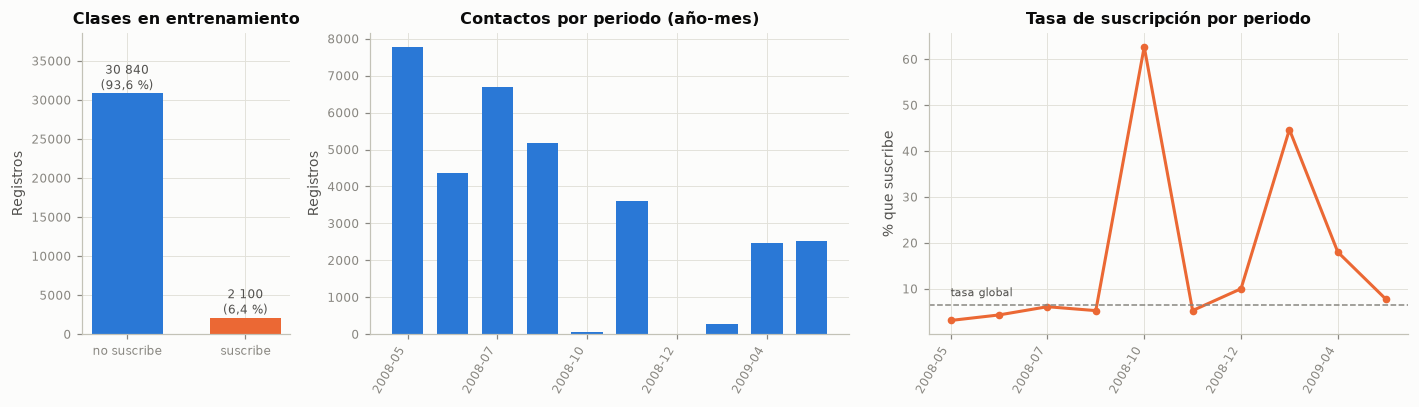

,Registros,% que suscribe
Año reconstruido,,
2008,27 682,"4,8"
2009,5 258,"14,5"


**Interpretación.** En entrenamiento suscribe el 6,38 % (2 100 casos de la clase minoritaria): hay 14,7 registros negativos por cada positivo. Un clasificador que siempre diga "no suscribe" acierta el 93,6 % de las veces. La tasa cambia mucho en el tiempo: va del 3,1 % en 2008-05 al 62,7 % en 2008-10 (un mes con solo 67 contactos en entrenamiento), y por año pasa del 4,8 % en 2008 al 14,5 % en el tramo de 2009 incluido en entrenamiento (hasta 2009-05). Los meses con más contactos son los de menor tasa (Spearman entre volumen y tasa por periodo = -0,84).

Entonces, el accuracy no sirve como métrica principal: un 93,6 % se logra sin aprender nada. Además, la prevalencia de la clase positiva depende del periodo, de modo que cualquier variable que identifique el periodo tendrá poder predictivo aparente y el desempeño en campañas futuras dependerá de la tasa base de ese futuro.

Por tal motivo, se opta por evaluar con AUC, AUC-PR (precisión promedio), recall, F1 y calibración; validar con el esquema temporal, que respeta la deriva de la prevalencia, y cuantificar en la sección 3.6 cuánto inflaría el resultado una validación aleatoria.

In [13]:
conteo = y_tr.value_counts().sort_index()
razon = conteo[0] / conteo[1]
acc_trivial = conteo[0] / len(y_tr)
dist_obj = pd.DataFrame({"Registros": conteo.values, "%": 100 * conteo.values / len(y_tr)},
                        index=["no suscribe (0)", "suscribe (1)"])
tabla(dist_obj, dec=2)

por_periodo = tr.groupby(periodo_tr)["y"].agg(contactos="size", tasa="mean")
por_anio_tr = tr.groupby(anio_tr)["y"].agg(contactos="size", tasa="mean")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2.3, 2.3]})
ax[0].bar(["no suscribe", "suscribe"], conteo.values, color=[AZUL, NARANJA], width=0.6)
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{num(v)}\n({pct(v / len(y_tr))})", ha="center", va="bottom", fontsize=8, color=TINTA_2)
ax[0].set_ylim(0, conteo.max() * 1.25)
ax[0].set_ylabel("Registros")
ax[0].set_title("Clases en entrenamiento")
x = np.arange(len(por_periodo))
ax[1].bar(x, por_periodo["contactos"], color=AZUL, width=0.7)
ax[1].set_ylabel("Registros")
ax[1].set_title("Contactos por periodo (año-mes)")
ax[2].plot(x, 100 * por_periodo["tasa"], color=NARANJA, marker="o", ms=4)
ax[2].axhline(100 * y_tr.mean(), color=GRIS, ls="--", lw=1)
ax[2].text(0, 100 * y_tr.mean() + 2, "tasa global", fontsize=7.5, color=TINTA_2)
ax[2].set_ylabel("% que suscribe")
ax[2].set_title("Tasa de suscripción por periodo")
for a in ax[1:]:
    a.set_xticks(x[::2], por_periodo.index[::2], rotation=60, ha="right")
plt.tight_layout()
plt.show()

tabla(por_anio_tr.assign(tasa=100 * por_anio_tr["tasa"]).rename(columns={"contactos": "Registros",
      "tasa": "% que suscribe"}).rename_axis("Año reconstruido"), dec=1)

p_min, p_max = por_periodo["tasa"].idxmin(), por_periodo["tasa"].idxmax()
rho_vol = stats.spearmanr(por_periodo["contactos"], por_periodo["tasa"]).statistic
interpretar(
    f"En entrenamiento suscribe el {pct(y_tr.mean(), 2)} ({num(conteo[1])} casos de la clase minoritaria): hay "
    f"{num(razon, 1)} registros negativos por cada positivo. Un clasificador que siempre diga \"no suscribe\" "
    f"acierta el {pct(acc_trivial)} de las veces. La tasa cambia mucho en el tiempo: va del "
    f"{pct(por_periodo.loc[p_min, 'tasa'])} en {p_min} al {pct(por_periodo.loc[p_max, 'tasa'])} en {p_max} (un mes con "
    f"solo {num(por_periodo.loc[p_max, 'contactos'])} contactos en entrenamiento), y por "
    f"año pasa del {pct(por_anio_tr.loc[por_anio_tr.index[0], 'tasa'])} en {por_anio_tr.index[0]} al "
    f"{pct(por_anio_tr.loc[por_anio_tr.index[-1], 'tasa'])} en el tramo de {por_anio_tr.index[-1]} incluido en "
    f"entrenamiento (hasta {periodo_corte}). "
    f"Los meses con más contactos son los de menor tasa (Spearman entre volumen y tasa por periodo = {num(rho_vol, 2)}).",
    f"Entonces, el accuracy no sirve como métrica principal: un {pct(acc_trivial)} se logra sin aprender nada. Además, "
    "la prevalencia de la clase positiva depende del periodo, de modo que cualquier variable que identifique el "
    "periodo tendrá poder predictivo aparente y el desempeño en campañas futuras dependerá de la tasa base de ese "
    "futuro.",
    "Por tal motivo, se opta por evaluar con AUC, AUC-PR (precisión promedio), recall, F1 y calibración; validar con "
    "el esquema temporal, que respeta la deriva de la prevalencia, y cuantificar en la sección 3.6 cuánto inflaría el "
    "resultado una validación aleatoria.")

## 3.2 Análisis unidimensional (enunciado, sección 2.2)

### 3.2.1 Variables numéricas

Para cada variable se reportan el número de valores distintos, los estadísticos de posición y dispersión, la asimetría, la curtosis (exceso sobre la normal), la prueba de normalidad de D'Agostino-Pearson y la proporción de atípicos según el IQR. `pdays` se resume con todos sus valores, incluido el código 999, y en el histograma se muestra sin el código.

,Valores distintos,Media,Mediana,Desv. est.,Mín.,P5,P25,P75,P95,Máx.,Asimetría,Curtosis,p normalidad,Atípicos IQR (%)
Variable,,,,,,,,,,,,,,
age,68,"40,03","39,00","9,35","18,00","27,00","33,00","47,00","57,00","95,00","0,48","-0,21","0,00","0,23"
duration,1 482,"255,99","175,00","261,26","0,00","38,00","100,00","314,00","757,00","4 918,00","3,32","20,86","0,00","7,48"
campaign,42,"2,67","2,00","2,97","1,00","1,00","1,00","3,00","7,00","56,00","4,65","33,91","0,00","6,51"
pdays,14,"993,75","999,00","72,03","0,00","999,00","999,00","999,00","999,00","999,00","-13,65","184,35","0,00","0,53"
previous,4,"0,07","0,00","0,27","0,00","0,00","0,00","0,00","1,00","3,00","3,87","15,51","0,00","6,91"
emp.var.rate,5,"0,65","1,10","1,16","-1,80","-1,80","-0,10","1,40","1,40","1,40","-1,39","0,29","0,00","0,00"
cons.price.idx,10,"93,70","93,92","0,48","92,76","92,89","93,20","93,99","94,47","94,47","-0,14","-1,05","0,00","0,00"
cons.conf.idx,10,"-40,64","-41,80","3,87","-50,00","-47,10","-42,70","-36,40","-36,10","-36,10","-0,17","-1,14","0,00","0,00"
euribor3m,106,"4,27","4,86","1,28","1,30","1,33","4,19","4,96","4,97","5,04","-1,72","1,15","0,00","15,96"


pdays sin el código 999: 174 registros (0,5 %), mediana 5 días, máximo 12 días.


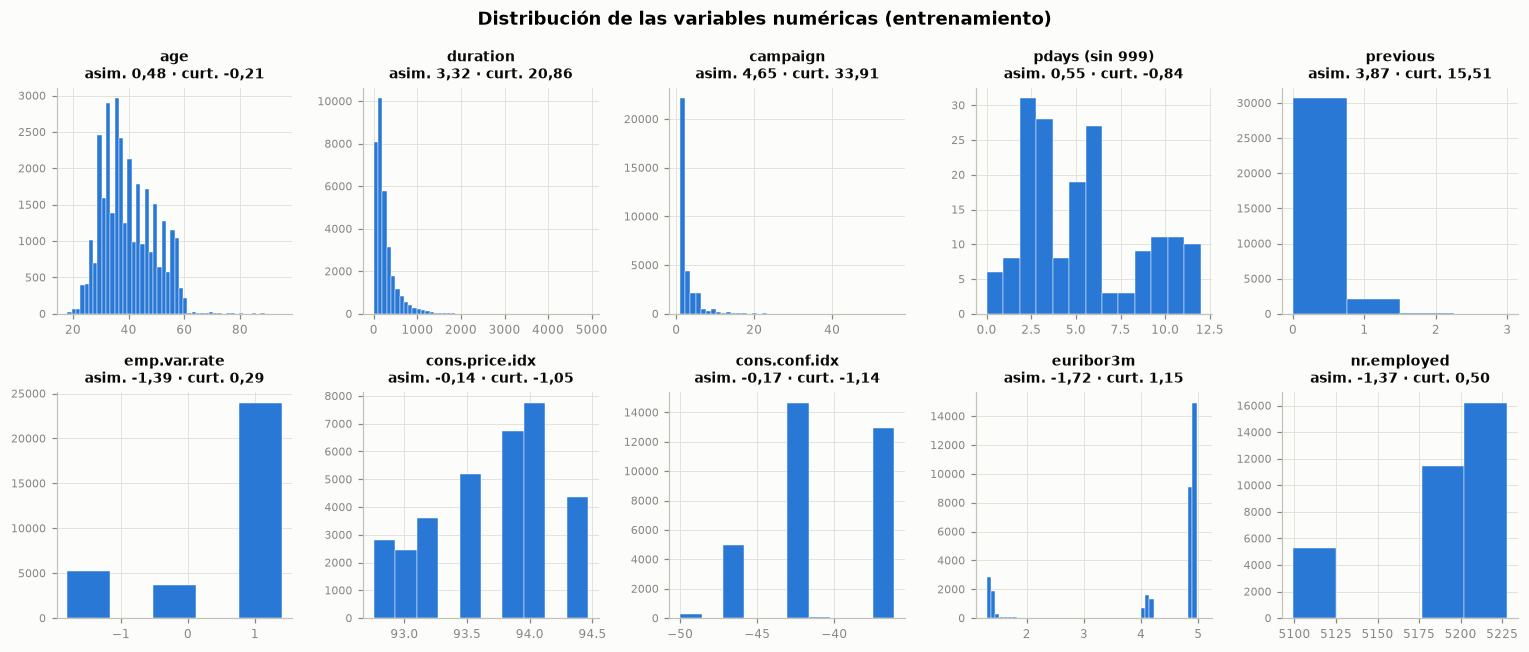

**Interpretación.** Las variables con asimetría marcada (|asimetría| > 1) son `duration`, `campaign`, `pdays`, `previous`, `emp.var.rate`, `euribor3m` y `nr.employed`; `campaign` tiene asimetría 4,65 y curtosis 33,9, con mediana 2 y máximo 56. La edad es moderadamente asimétrica a la derecha (mediana 39 años). Los indicadores macroeconómicos no son continuos en la práctica: `emp.var.rate` toma 5 valores, `cons.price.idx` toma 10 valores, `cons.conf.idx` toma 10 valores y `nr.employed` toma 5 valores, con distribuciones multimodales que corresponden a periodos distintos. La prueba de normalidad rechaza en las 10 variables (p < 0,05), algo esperable con n = 32 940.

Lo anterior indica que las colas largas de los conteos (`campaign`, `previous`) dan palanca excesiva a pocos registros en un modelo lineal. El rechazo de la normalidad no es un problema para la regresión logística, que no la supone en las predictoras, pero confirma que conviene usar pruebas no paramétricas en el análisis bidimensional. Que las macro tengan tan pocos valores indica que funcionan como etiquetas del periodo más que como medidas continuas.

En consecuencia, se decide aplicar `log1p` a `campaign` y `previous` antes del escalado (sección 3.7) y usar Spearman, Mann-Whitney y Kruskal-Wallis en la sección 3.3.

In [14]:
filas_uni = []
for c in NUMERICAS:
    s = tr[c].astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    _, p_norm = stats.normaltest(s)
    filas_uni.append({
        "Variable": c, "Valores distintos": s.nunique(), "Media": s.mean(), "Mediana": s.median(),
        "Desv. est.": s.std(), "Mín.": s.min(), "P5": s.quantile(0.05), "P25": q1, "P75": q3,
        "P95": s.quantile(0.95), "Máx.": s.max(), "Asimetría": s.skew(), "Curtosis": s.kurt(),
        "p normalidad": p_norm, "Atípicos IQR (%)": 100 * ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()})
uni_num = pd.DataFrame(filas_uni).set_index("Variable")
tabla(uni_num, dec=2)
pd_real = tr.loc[tr["pdays"] != 999, "pdays"]
print(f"pdays sin el código 999: {num(len(pd_real))} registros ({pct(len(pd_real) / len(tr))}), "
      f"mediana {num(pd_real.median())} días, máximo {num(pd_real.max())} días.")

fig, axs = plt.subplots(2, 5, figsize=(14, 6))
for ax, c in zip(axs.ravel(), NUMERICAS):
    s = pd_real if c == "pdays" else tr[c]
    ax.hist(s, bins=min(50, s.nunique()), color=AZUL, edgecolor=FONDO, linewidth=0.3)
    ax.set_title(("pdays (sin 999)" if c == "pdays" else c) + f"\nasim. {num(s.skew(), 2)} · curt. {num(s.kurt(), 2)}",
                 fontsize=9)
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Distribución de las variables numéricas (entrenamiento)")
plt.tight_layout()
plt.show()

sesgadas = uni_num.index[uni_num["Asimetría"].abs() > 1].tolist()
pocos_valores = uni_num.index[uni_num["Valores distintos"] <= 30].tolist()
macro_pocos = [c for c in MACRO if c in pocos_valores]
interpretar(
    f"Las variables con asimetría marcada (|asimetría| > 1) son {enumerar(sesgadas)}; "
    f"`campaign` tiene asimetría {num(uni_num.loc['campaign', 'Asimetría'], 2)} y curtosis "
    f"{num(uni_num.loc['campaign', 'Curtosis'], 1)}, con mediana {num(uni_num.loc['campaign', 'Mediana'])} y máximo "
    f"{num(uni_num.loc['campaign', 'Máx.'])}. La edad es moderadamente asimétrica a la derecha (mediana "
    f"{num(uni_num.loc['age', 'Mediana'])} años). Los indicadores macroeconómicos no son continuos en la práctica: "
    + enumerar([f"`{c}` toma {uni_num.loc[c, 'Valores distintos']} valores" for c in macro_pocos], codigo=False)
    + ", con distribuciones multimodales que corresponden a periodos distintos. La prueba de normalidad rechaza en "
    f"las {int((uni_num['p normalidad'] < 0.05).sum())} variables (p < 0,05), algo esperable con n = {num(len(tr))}.",
    "Lo anterior indica que las colas largas de los conteos (`campaign`, `previous`) dan palanca excesiva a pocos "
    "registros en un modelo lineal. El rechazo de la normalidad no es un problema para la regresión logística, que no "
    "la supone en las predictoras, pero confirma que conviene usar pruebas no paramétricas en el análisis "
    "bidimensional. Que las macro tengan tan pocos valores indica que funcionan como etiquetas del periodo más que "
    "como medidas continuas.",
    "En consecuencia, se decide aplicar `log1p` a `campaign` y `previous` antes del escalado (sección 3.7) y usar "
    "Spearman, Mann-Whitney y Kruskal-Wallis en la sección 3.3.")

,Asimetría original,Asimetría con log1p,Curtosis original,Curtosis con log1p
campaign,"4,65","1,36","33,91","2,05"
previous,"3,87","3,54","15,51","11,18"
duration,"3,32","-0,30","20,86","0,66"


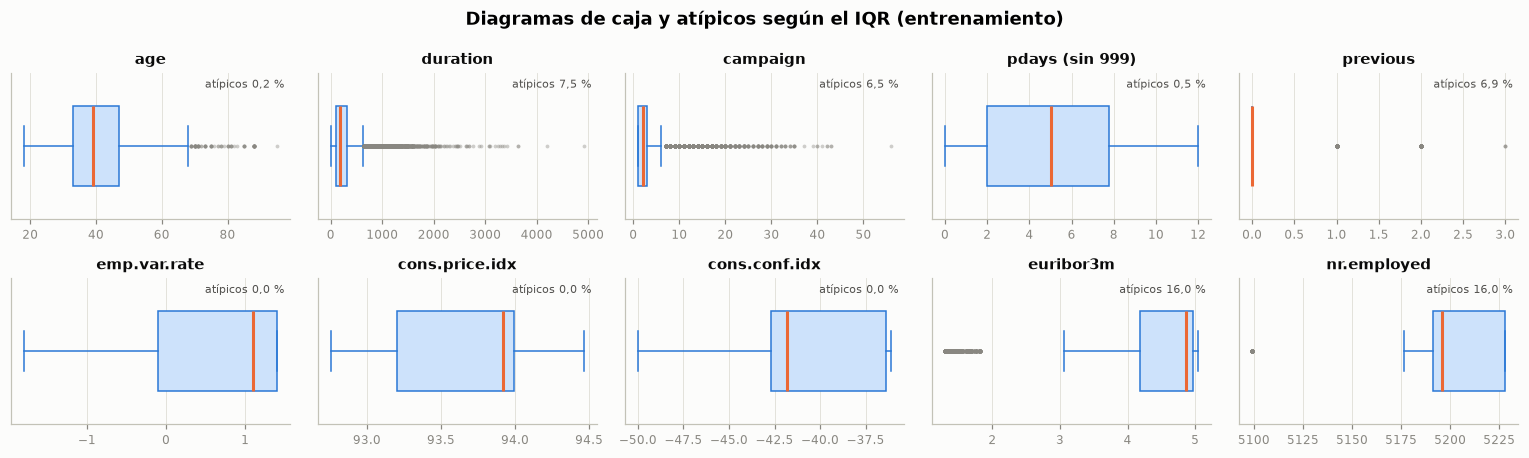

**Interpretación.** `log1p` reduce la asimetría de `campaign` de 4,65 a 1,36 y la de `previous` de 3,87 a 3,54. Los diagramas de caja muestran atípicos sobre todo en `previous` (6,9 %), `duration` (7,5 %) y `campaign` (6,5 %); en las macro solo `euribor3m` y `nr.employed` tiene atípicos univariados.

Así mismo, los atípicos son valores legítimos de la cola (clientes muy contactados o con historial), no errores de medición, así que su eliminación sesgaría la muestra. La transformación logarítmica reduce su palanca sin perder registros.

Por esta razón, lo indicado es conservar todos los registros y tratar los atípicos con `log1p` en `campaign` y `previous` dentro del `Pipeline`; `duration` no se transforma porque queda excluida por fuga (sección 3.5).

In [15]:
transformadas = pd.DataFrame({
    "Asimetría original": [tr[c].skew() for c in ["campaign", "previous", "duration"]],
    "Asimetría con log1p": [np.log1p(tr[c]).skew() for c in ["campaign", "previous", "duration"]],
    "Curtosis original": [tr[c].kurt() for c in ["campaign", "previous", "duration"]],
    "Curtosis con log1p": [np.log1p(tr[c]).kurt() for c in ["campaign", "previous", "duration"]]},
    index=["campaign", "previous", "duration"])
tabla(transformadas, dec=2)

fig, axs = plt.subplots(2, 5, figsize=(14, 4.2))
for ax, c in zip(axs.ravel(), NUMERICAS):
    s = pd_real if c == "pdays" else tr[c]
    ax.boxplot(s, orientation="horizontal", widths=0.55, patch_artist=True,
               boxprops={"facecolor": "#cde2fb", "edgecolor": AZUL}, medianprops={"color": NARANJA, "lw": 2},
               whiskerprops={"color": AZUL}, capprops={"color": AZUL},
               flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": GRIS, "markeredgecolor": "none",
                           "alpha": 0.4})
    ax.set_yticks([])
    ax.set_title("pdays (sin 999)" if c == "pdays" else c, fontsize=9.5)
    ax.text(0.98, 0.9, f"atípicos {num(uni_num.loc[c, 'Atípicos IQR (%)'], 1)} %", transform=ax.transAxes,
            ha="right", fontsize=7.5, color=TINTA_2)
fig.suptitle("Diagramas de caja y atípicos según el IQR (entrenamiento)")
plt.tight_layout()
plt.show()

interpretar(
    f"`log1p` reduce la asimetría de `campaign` de {num(transformadas.loc['campaign', 'Asimetría original'], 2)} a "
    f"{num(transformadas.loc['campaign', 'Asimetría con log1p'], 2)} y la de `previous` de "
    f"{num(transformadas.loc['previous', 'Asimetría original'], 2)} a "
    f"{num(transformadas.loc['previous', 'Asimetría con log1p'], 2)}. Los diagramas de caja muestran atípicos "
    f"sobre todo en `previous` ({num(uni_num.loc['previous', 'Atípicos IQR (%)'], 1)} %), `duration` "
    f"({num(uni_num.loc['duration', 'Atípicos IQR (%)'], 1)} %) y `campaign` "
    f"({num(uni_num.loc['campaign', 'Atípicos IQR (%)'], 1)} %); en las macro "
    + ("no hay atípicos univariados." if not [c for c in MACRO if uni_num.loc[c, "Atípicos IQR (%)"] > 0] else
       "solo " + enumerar([c for c in MACRO if uni_num.loc[c, "Atípicos IQR (%)"] > 0]) + " tiene atípicos univariados."),
    "Así mismo, los atípicos son valores legítimos de la cola (clientes muy contactados o con historial), no errores "
    "de medición, así que su eliminación sesgaría la muestra. La transformación logarítmica reduce su palanca sin "
    "perder registros.",
    "Por esta razón, lo indicado es conservar todos los registros y tratar los atípicos con `log1p` en `campaign` y "
    "`previous` dentro del `Pipeline`; `duration` no se transforma porque queda excluida por fuga (sección 3.5).")

### 3.2.2 Variables categóricas

Se reportan la cardinalidad, la moda, el porcentaje de `unknown` y las categorías raras (menos del 1 % de los registros), con la frecuencia de cada categoría y su gráfico de barras.

,Cardinalidad,Moda,% moda,% unknown,Categorías raras (menos del 1 %)
Variable,,,,,
job,12,admin.,"24,40","0,81",unknown (266)
marital,4,married,"62,92","0,19",unknown (62)
education,8,university.degree,"28,43","4,01",illiterate (14)
default,3,no,"75,66","24,34",yes (3)
housing,3,yes,"51,53","2,37",—
loan,3,no,"82,39","2,37",—
contact,2,cellular,"57,35","0,00",—
month,9,may,"31,21","0,00","mar (282), oct (67), dec (10)"
day_of_week,5,thu,"21,25","0,00",—


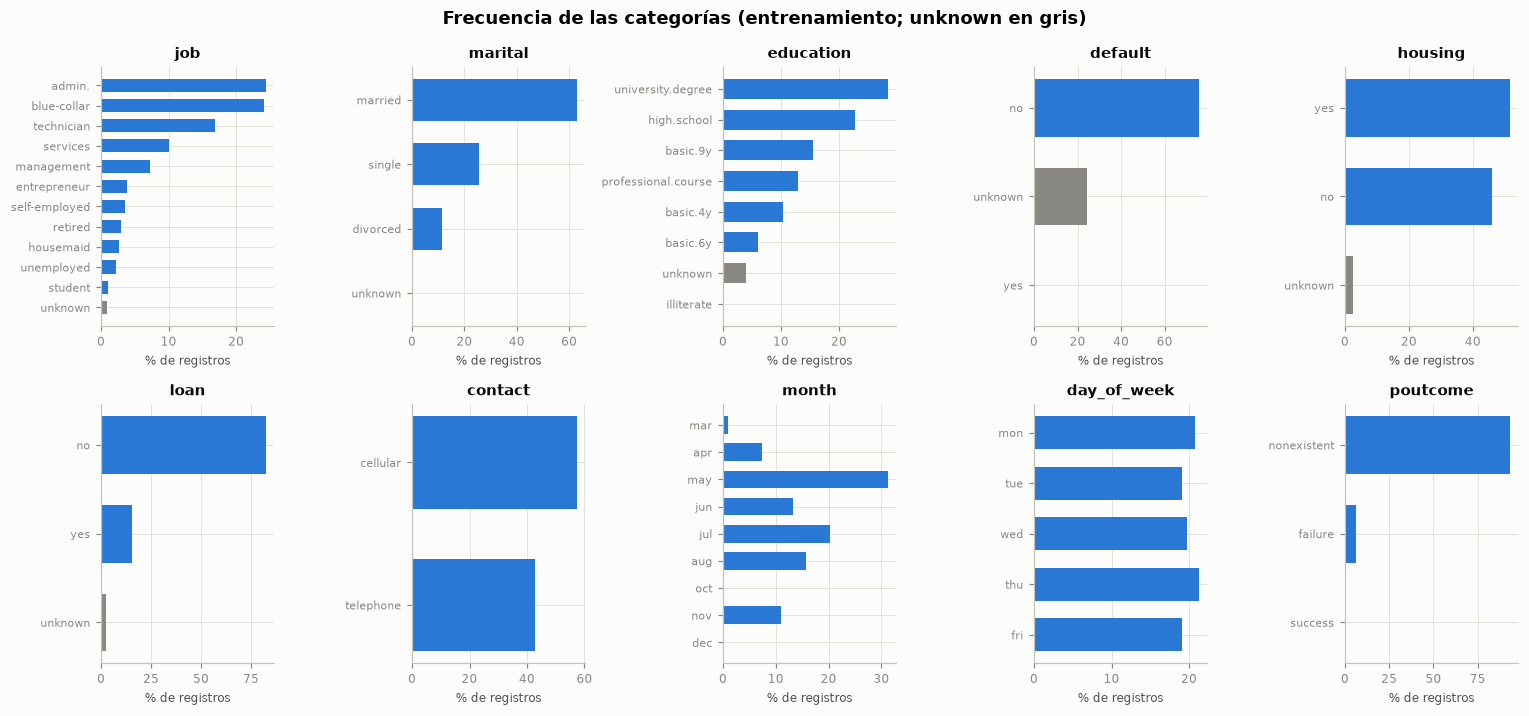

Variable,Categoría,Registros,%
job,admin.,8 038,"24,40"
job,blue-collar,7 958,"24,16"
job,technician,5 573,"16,92"
job,services,3 323,"10,09"
job,management,2 400,"7,29"
job,entrepreneur,1 261,"3,83"
job,self-employed,1 156,"3,51"
job,retired,989,"3,00"
job,housemaid,880,"2,67"
job,unemployed,749,"2,27"


**Interpretación.** Las cardinalidades van de 2 (`contact`) a 12 (`job`). Varias variables están dominadas por una categoría: `poutcome` = nonexistent (93,1 %), `loan` = no (82,4 %) y `default` = no (75,7 %). `month` concentra los contactos en may (31,2 %), mientras que `day_of_week` es casi uniforme. Hay 5 categorías con menos del 0,5 % de los registros: `marital = unknown` (62), `education = illiterate` (14), `default = yes` (3), `month = oct` (67), `month = dec` (10).

Hay que tener en cuenta que una categoría con muy pocos registros produce un coeficiente inestable y puede no aparecer en algún pliegue de validación. Las variables dominadas por una sola categoría aportan información solo a través de la minoría (por ejemplo, `poutcome = success`).

Por ello, se recomienda agrupar en el codificador las categorías con menos del 0,5 % de los registros de entrenamiento como categoría "infrecuente" de su variable, lo que además protege contra categorías no vistas, y conservar `unknown` como categoría propia (sección 1.6.2).

In [16]:
ORDEN_CAT = {"month": [m for m in ORDEN_MESES if m in tr["month"].unique()],
             "day_of_week": ["mon", "tue", "wed", "thu", "fri"]}
filas_cat, frecuencias = [], []
for c in CATEGORICAS:
    vc = tr[c].value_counts()
    raras = vc[vc / len(tr) < 0.01]
    filas_cat.append({"Variable": c, "Cardinalidad": tr[c].nunique(), "Moda": vc.index[0],
                      "% moda": 100 * vc.iloc[0] / len(tr), "% unknown": 100 * (tr[c] == "unknown").mean(),
                      "Categorías raras (menos del 1 %)": ", ".join(f"{k} ({v})" for k, v in raras.items()) or "—"})
    for k, v in vc.items():
        frecuencias.append({"Variable": c, "Categoría": k, "Registros": v, "%": 100 * v / len(tr)})
uni_cat = pd.DataFrame(filas_cat).set_index("Variable")
tabla(uni_cat, dec=2)

fig, axs = plt.subplots(2, 5, figsize=(14, 6.6))
for ax, c in zip(axs.ravel(), CATEGORICAS):
    vc = tr[c].value_counts(normalize=True)
    vc = vc.reindex(ORDEN_CAT[c]) if c in ORDEN_CAT else vc.sort_values()
    colores = [GRIS if k == "unknown" else AZUL for k in vc.index]
    ax.barh(vc.index.astype(str), 100 * vc.values, color=colores, height=0.65)
    ax.set_title(c, fontsize=9.5)
    ax.set_xlabel("% de registros", fontsize=8)
    ax.tick_params(axis="y", labelsize=7.5)
    if c in ORDEN_CAT:
        ax.invert_yaxis()
fig.suptitle("Frecuencia de las categorías (entrenamiento; unknown en gris)")
plt.tight_layout()
plt.show()

frec = pd.DataFrame(frecuencias)
tabla(frec, dec=2, indice=False)

MIN_FREQ = 0.005  # umbral de categoría rara para el codificador (sección 3.7)
muy_raras = frec[frec["%"] < 100 * MIN_FREQ]
interpretar(
    f"Las cardinalidades van de {uni_cat['Cardinalidad'].min()} (`contact`) a {uni_cat['Cardinalidad'].max()} "
    f"(`job`). Varias variables están dominadas por una categoría: `poutcome` = "
    f"{uni_cat.loc['poutcome', 'Moda']} ({num(uni_cat.loc['poutcome', '% moda'], 1)} %), `loan` = "
    f"{uni_cat.loc['loan', 'Moda']} ({num(uni_cat.loc['loan', '% moda'], 1)} %) y `default` = "
    f"{uni_cat.loc['default', 'Moda']} ({num(uni_cat.loc['default', '% moda'], 1)} %). `month` concentra los contactos en "
    f"{uni_cat.loc['month', 'Moda']} ({num(uni_cat.loc['month', '% moda'], 1)} %), mientras que `day_of_week` es "
    f"casi uniforme. Hay {len(muy_raras)} categorías con menos del {pct(MIN_FREQ)} de los registros: "
    + ", ".join(f"`{r.Variable} = {r.Categoría}` ({r.Registros})" for r in muy_raras.itertuples()) + ".",
    "Hay que tener en cuenta que una categoría con muy pocos registros produce un coeficiente inestable y puede no "
    "aparecer en algún pliegue de validación. Las variables dominadas por una sola categoría aportan información solo "
    "a través de la minoría (por ejemplo, `poutcome = success`).",
    f"Por ello, se recomienda agrupar en el codificador las categorías con menos del {pct(MIN_FREQ)} de los registros "
    "de entrenamiento como categoría \"infrecuente\" de su variable, lo que además protege contra categorías no "
    "vistas, y conservar `unknown` como categoría propia (sección 1.6.2).")

## 3.3 Análisis bidimensional (enunciado, sección 2.3)

### 3.3.1 Numéricas frente a numéricas

Se calculan las correlaciones de Pearson (lineal) y Spearman (monótona) para los 45 pares de variables numéricas, con valores *p* de Spearman ajustados por Holm. Los diagramas *hexbin* reemplazan al diagrama de dispersión porque, con más de 30 000 puntos, la superposición ocultaría la densidad.

Variable 1,Variable 2,Pearson,Spearman,p Spearman (Holm)
emp.var.rate,nr.employed,"0,946","0,936","0,000"
emp.var.rate,euribor3m,"0,978","0,925","0,000"
euribor3m,nr.employed,"0,952","0,869","0,000"
emp.var.rate,cons.price.idx,"0,780","0,535","0,000"
cons.conf.idx,euribor3m,"0,716","0,487","0,000"
cons.price.idx,cons.conf.idx,"0,372","0,428","0,000"
emp.var.rate,cons.conf.idx,"0,688","0,403","0,000"
previous,emp.var.rate,"-0,441","-0,383","0,000"
cons.price.idx,euribor3m,"0,735","0,372","0,000"
previous,cons.price.idx,"-0,366","-0,361","0,000"


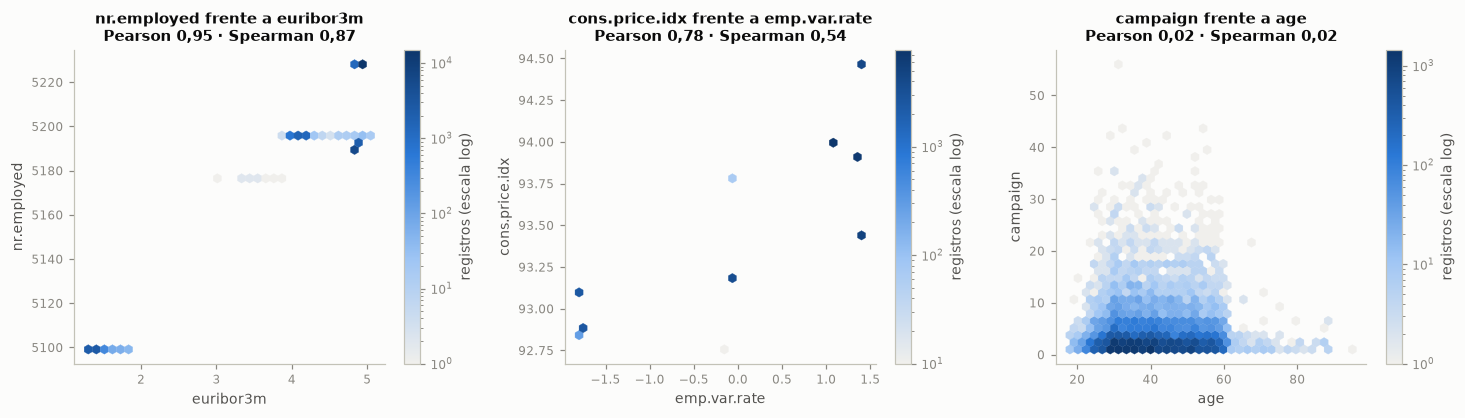

**Interpretación.** 3 pares tienen |Spearman| ≥ 0,7, todos entre indicadores macroeconómicos: `emp.var.rate`–`nr.employed` (0,94); `emp.var.rate`–`euribor3m` (0,93); `euribor3m`–`nr.employed` (0,87). Los *hexbin* muestran que esas relaciones se forman con pocas combinaciones de valores (una por periodo). La mayor diferencia entre Spearman y Pearson aparece en `cons.price.idx`–`euribor3m` (0,37 frente a 0,74), señal de que la asociación lineal depende de unos pocos grupos de valores (los periodos) más que de una relación monótona. La edad y el número de contactos de la campaña no están relacionados (Spearman 0,02).

Esto significa que las macro miden casi lo mismo (el ciclo económico del periodo), así que en un modelo lineal se reparten el efecto y sus coeficientes individuales se vuelven inestables y difíciles de interpretar.

Con base en esto, se propone cuantificar la multicolinealidad con el VIF (sección 3.3.5) y eliminar las variables redundantes antes del modelo base.

In [17]:
pares = []
for i, a in enumerate(NUMERICAS):
    for b in NUMERICAS[i + 1:]:
        sp = stats.spearmanr(tr[a], tr[b])
        pares.append({"Variable 1": a, "Variable 2": b, "Pearson": tr[a].corr(tr[b]), "Spearman": sp.statistic,
                      "p Spearman": sp.pvalue})
pares = pd.DataFrame(pares)
pares["p Spearman (Holm)"] = multipletests(pares["p Spearman"], method="holm")[1]
pares["|Spearman|"] = pares["Spearman"].abs()
pares = pares.sort_values("|Spearman|", ascending=False)
tabla(pares.drop(columns=["|Spearman|", "p Spearman"]).head(12), dec=3, indice=False)

fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.9))
for ax, (a, b) in zip(axs, [("euribor3m", "nr.employed"), ("emp.var.rate", "cons.price.idx"), ("age", "campaign")]):
    hb = ax.hexbin(tr[a], tr[b], gridsize=35, bins="log", cmap=CMAP_SEQ, mincnt=1, linewidths=0.2)
    r_p, r_s = tr[a].corr(tr[b]), tr[a].corr(tr[b], method="spearman")
    ax.set_title(f"{b} frente a {a}\nPearson {num(r_p, 2)} · Spearman {num(r_s, 2)}", fontsize=9.5)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.grid(False)
    fig.colorbar(hb, ax=ax, label="registros (escala log)")
plt.tight_layout()
plt.show()

fuertes = pares[pares["|Spearman|"] >= 0.7]
dif_lin = pares.assign(dif=(pares["Spearman"] - pares["Pearson"]).abs()).sort_values("dif", ascending=False).iloc[0]
interpretar(
    f"{len(fuertes)} pares tienen |Spearman| ≥ 0,7, todos entre indicadores macroeconómicos: "
    + "; ".join(f"`{r['Variable 1']}`–`{r['Variable 2']}` ({num(r['Spearman'], 2)})" for _, r in fuertes.iterrows())
    + f". Los *hexbin* muestran que esas relaciones se forman con pocas combinaciones de valores (una por periodo). "
    f"La mayor diferencia entre Spearman y Pearson aparece en `{dif_lin['Variable 1']}`–`{dif_lin['Variable 2']}` "
    f"({num(dif_lin['Spearman'], 2)} frente a {num(dif_lin['Pearson'], 2)}), "
    + ("señal de relación monótona no lineal. " if abs(dif_lin["Spearman"]) > abs(dif_lin["Pearson"]) else
       "señal de que la asociación lineal depende de unos pocos grupos de valores (los periodos) más que de una "
       "relación monótona. ")
    + ""
    f"La edad y el número de contactos de la campaña no están relacionados (Spearman "
    f"{num(tr['age'].corr(tr['campaign'], method='spearman'), 2)}).",
    "Esto significa que las macro miden casi lo mismo (el ciclo económico del periodo), así que en un modelo lineal se "
    "reparten el efecto y sus coeficientes individuales se vuelven inestables y difíciles de interpretar.",
    "Con base en esto, se propone cuantificar la multicolinealidad con el VIF (sección 3.3.5) y eliminar las variables "
    "redundantes antes del modelo base.")

### 3.3.2 Categóricas frente a numéricas

Para cada par categórica-numérica se aplica Kruskal-Wallis (alternativa no paramétrica al ANOVA, adecuada porque la normalidad se rechazó en la sección 3.2.1). El tamaño de efecto es $\varepsilon^2 = H/(n-1)$, que se lee como la proporción de la variabilidad de los rangos explicada por la categoría (guía orientativa: 0,01 pequeño, 0,06 mediano, 0,14 grande).

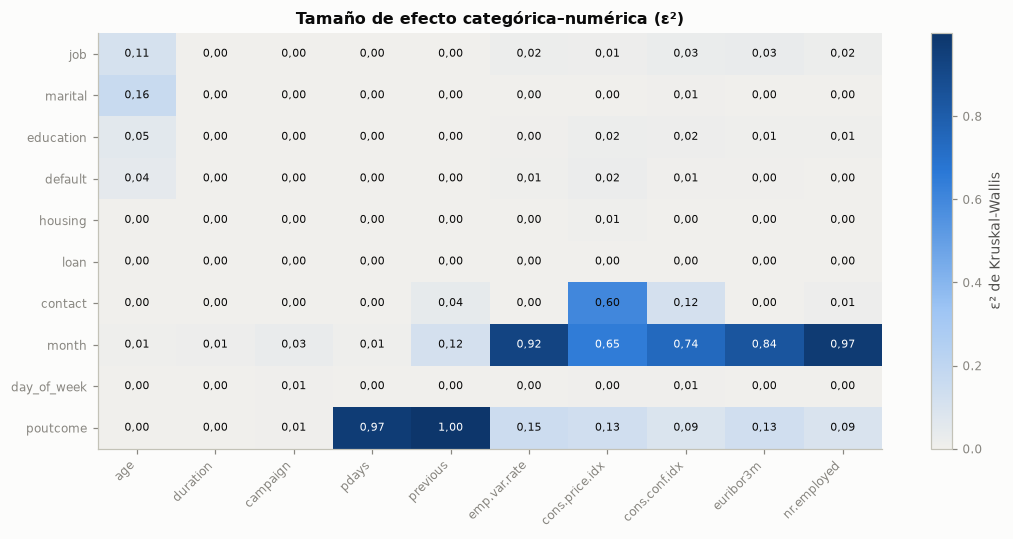

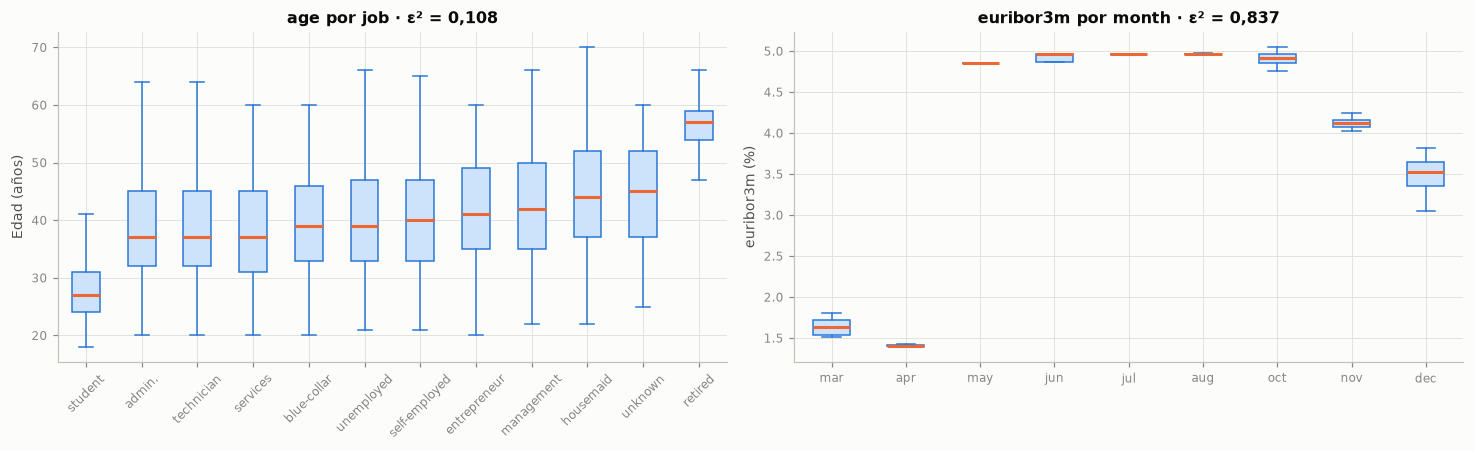

**Interpretación.** 72 de los 100 pares resultan significativos tras Holm, pero solo 17 alcanzan un efecto al menos mediano (ε² ≥ 0,06). Los mayores son `poutcome`–`previous` (1,000); `month`–`nr.employed` (0,969); `poutcome`–`pdays` (0,966); `month`–`emp.var.rate` (0,923); `month`–`euribor3m` (0,837); `month`–`cons.conf.idx` (0,740). Los dos primeros son estructurales: `poutcome = nonexistent` ocurre exactamente cuando `previous = 0` (sección 1.6.4). La edad varía con el estado civil (ε² = 0,163) y con la ocupación (ε² = 0,108): la mediana más baja es la de `student` (27 años) y la más alta la de `retired` (57 años); y la Euribor cambia con el mes porque el mes, junto con el orden del archivo, marca el periodo.

De esta forma, la alta significancia con efectos pequeños confirma que, con este n, el valor p no basta para seleccionar variables. Las asociaciones fuertes entre `month`, `contact`, `poutcome` y las macro indican que varias predictoras comparten la misma información del periodo y del historial.

En virtud de ello, se decide usar el tamaño de efecto, no el valor p, en la selección preliminar (sección 3.3.6) y tener presente que `month` y las macro son, en parte, sustitutos entre sí.

In [18]:
eps2 = pd.DataFrame(index=CATEGORICAS, columns=NUMERICAS, dtype=float)
pvals_kw = []
for c in CATEGORICAS:
    for v in NUMERICAS:
        muestras = [tr.loc[tr[c] == k, v].to_numpy() for k in tr[c].unique()]
        h, p = stats.kruskal(*muestras)
        eps2.loc[c, v] = h / (len(tr) - 1)
        pvals_kw.append({"Categórica": c, "Numérica": v, "H": h, "p": p, "ε²": h / (len(tr) - 1)})
kw = pd.DataFrame(pvals_kw)
kw["p (Holm)"] = multipletests(kw["p"], method="holm")[1]
n_sig_kw = int((kw["p (Holm)"] < 0.05).sum())

fig, ax = plt.subplots(figsize=(10, 5))
im = mapa_calor(ax, eps2.to_numpy(), CATEGORICAS, NUMERICAS, CMAP_SEQ, 0, max(0.3, eps2.max().max()), dec=2)
fig.colorbar(im, ax=ax, label="ε² de Kruskal-Wallis")
ax.set_title("Tamaño de efecto categórica–numérica (ε²)")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.2))
orden_job = tr.groupby("job")["age"].median().sort_values().index
axs[0].boxplot([tr.loc[tr["job"] == k, "age"] for k in orden_job], tick_labels=orden_job, showfliers=False,
               patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": AZUL},
               medianprops={"color": NARANJA, "lw": 2}, whiskerprops={"color": AZUL}, capprops={"color": AZUL})
axs[0].tick_params(axis="x", rotation=45)
axs[0].set_ylabel("Edad (años)")
axs[0].set_title(f"age por job · ε² = {num(eps2.loc['job', 'age'], 3)}")
meses = ORDEN_CAT["month"]
axs[1].boxplot([tr.loc[tr["month"] == m, "euribor3m"] for m in meses], tick_labels=meses, showfliers=False,
               patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": AZUL},
               medianprops={"color": NARANJA, "lw": 2}, whiskerprops={"color": AZUL}, capprops={"color": AZUL})
axs[1].set_ylabel("euribor3m (%)")
axs[1].set_title(f"euribor3m por month · ε² = {num(eps2.loc['month', 'euribor3m'], 3)}")
plt.tight_layout()
plt.show()

top_kw = kw.sort_values("ε²", ascending=False).head(6)
interpretar(
    f"{n_sig_kw} de los {len(kw)} pares resultan significativos tras Holm, pero solo "
    f"{int((kw['ε²'] >= 0.06).sum())} alcanzan un efecto al menos mediano (ε² ≥ 0,06). Los mayores son "
    + "; ".join(f"`{r['Categórica']}`–`{r['Numérica']}` ({num(r['ε²'], 3)})" for _, r in top_kw.iterrows())
    + f". Los dos primeros son estructurales: `poutcome = nonexistent` ocurre exactamente cuando `previous = 0` "
    f"(sección 1.6.4). La edad varía con el estado civil (ε² = {num(eps2.loc['marital', 'age'], 3)}) y con la "
    f"ocupación (ε² = {num(eps2.loc['job', 'age'], 3)}): la mediana más baja es la de "
    f"`{orden_job[0]}` ({num(tr.loc[tr['job'] == orden_job[0], 'age'].median())} años) y la más alta la de "
    f"`{orden_job[-1]}` ({num(tr.loc[tr['job'] == orden_job[-1], 'age'].median())} años); y la Euribor cambia con el "
    "mes porque el mes, junto con el orden del archivo, marca el periodo.",
    "De esta forma, la alta significancia con efectos pequeños confirma que, con este n, el valor p no basta para "
    "seleccionar variables. Las asociaciones fuertes entre `month`, `contact`, `poutcome` y las macro indican que "
    "varias predictoras comparten la misma información del periodo y del historial.",
    "En virtud de ello, se decide usar el tamaño de efecto, no el valor p, en la selección preliminar (sección 3.3.6) "
    "y tener presente que `month` y las macro son, en parte, sustitutos entre sí.")

### 3.3.3 Categóricas frente a categóricas

Para cada par de categóricas (incluida la variable objetivo) se construye la tabla de contingencia, se aplica la prueba χ² y se calcula la V de Cramér como tamaño de efecto (guía orientativa: 0,1 pequeña, 0,3 mediana, 0,5 grande), con ajuste de Holm.

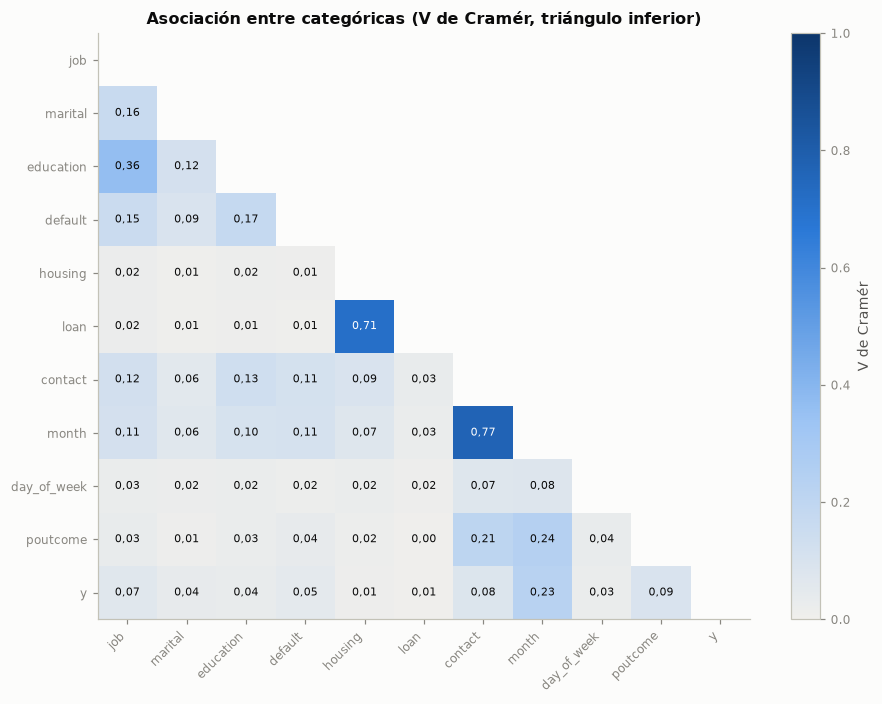

Tabla de contingencia housing × loan (entrenamiento):


loan,no,unknown,yes,Total
housing,,,,
no,13083,0,2103,15186
unknown,0,781,0,781
yes,14055,0,2918,16973
Total,27138,781,5021,32940


**Interpretación.** Los pares de predictoras más asociados son `contact`–`month` (V = 0,77); `housing`–`loan` (V = 0,71); `job`–`education` (V = 0,36); `month`–`poutcome` (V = 0,24); `contact`–`poutcome` (V = 0,21). La V entre `housing` y `loan` (0,71) se explica por la tabla de contingencia: las dos son `unknown` exactamente en los mismos 781 registros. Frente a la objetivo, las mayores asociaciones son `month` (0,23), `poutcome` (0,09), `contact` (0,08), `job` (0,07).

Por su parte, la asociación `month`–`contact` (V = 0,77) y `month`–`poutcome` (V = 0,24) refleja la estructura temporal: los canales y el historial cambian según el periodo de la campaña. `housing = unknown` y `loan = unknown` son la misma información duplicada.

Por tanto, corresponde mantener ambas variables (el resto de sus categorías sí difiere), sabiendo que sus indicadores de `unknown` son colineales; la regularización L2 del modelo base reparte ese efecto de forma estable.

In [19]:
CAT_Y = CATEGORICAS + ["y"]
tr_cat = tr[CATEGORICAS].assign(y=tr["y"].map({0: "no", 1: "yes"}))
V = pd.DataFrame(np.nan, index=CAT_Y, columns=CAT_Y)
pruebas_cc = []
for i, a in enumerate(CAT_Y):
    for b in CAT_Y[i + 1:]:
        v, chi2, p = v_cramer(pd.crosstab(tr_cat[a], tr_cat[b]))
        V.loc[b, a] = v
        pruebas_cc.append({"Variable 1": a, "Variable 2": b, "χ²": chi2, "p": p, "V de Cramér": v})
cc = pd.DataFrame(pruebas_cc)
cc["p (Holm)"] = multipletests(cc["p"], method="holm")[1]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = mapa_calor(ax, V.to_numpy(), CAT_Y, CAT_Y, CMAP_SEQ, 0, 1, dec=2)
fig.colorbar(im, ax=ax, label="V de Cramér")
ax.set_title("Asociación entre categóricas (V de Cramér, triángulo inferior)")
plt.tight_layout()
plt.show()

print("Tabla de contingencia housing × loan (entrenamiento):")
display(pd.crosstab(tr["housing"], tr["loan"], margins=True, margins_name="Total"))

top_cc = cc[(cc["Variable 1"] != "y") & (cc["Variable 2"] != "y")].sort_values("V de Cramér", ascending=False).head(5)
cc_y = cc[(cc["Variable 2"] == "y")].sort_values("V de Cramér", ascending=False)
hl = cc[(cc["Variable 1"] == "housing") & (cc["Variable 2"] == "loan")].iloc[0]
interpretar(
    f"Los pares de predictoras más asociados son "
    + "; ".join(f"`{r['Variable 1']}`–`{r['Variable 2']}` (V = {num(r['V de Cramér'], 2)})" for _, r in top_cc.iterrows())
    + f". La V entre `housing` y `loan` ({num(hl['V de Cramér'], 2)}) se explica por la tabla de contingencia: "
    f"las dos son `unknown` exactamente en los mismos {num(int((tr['housing'] == 'unknown').sum()))} registros. "
    f"Frente a la objetivo, las mayores asociaciones son "
    + ", ".join(f"`{r['Variable 1']}` ({num(r['V de Cramér'], 2)})" for _, r in cc_y.head(4).iterrows()) + ".",
    (f"Por su parte, la asociación `month`–`contact` (V = {num(V.loc['month', 'contact'], 2)}) y `month`–`poutcome` "
     f"(V = {num(V.loc['poutcome', 'month'], 2)}) refleja la estructura temporal: los canales y el historial cambian "
     "según el periodo de la campaña. ")
    + "`housing = unknown` y `loan = unknown` son la misma información duplicada.",
    "Por tanto, corresponde mantener ambas variables (el resto de sus categorías sí difiere), sabiendo que sus "
    "indicadores de `unknown` son colineales; la regularización L2 del modelo base reparte ese efecto de forma "
    "estable.")

### 3.3.4 Predictoras frente a la variable objetivo

- **Numéricas:** prueba de Mann-Whitney entre quienes suscriben y quienes no; tamaño de efecto con la correlación biserial de rangos $r = 2\,\mathrm{AUC} - 1$ (positiva si los valores son mayores entre quienes suscriben; guía orientativa: 0,1 pequeño, 0,3 mediano, 0,5 grande).
- **Categóricas:** χ² y V de Cramér.
- **Todas:** información mutua (no paramétrica, capta relaciones no lineales), estimada con `random_state = SEED`.

Los valores *p* de las 20 pruebas se ajustan por Holm y por FDR (Benjamini-Hochberg).

,Tipo,Prueba,Estadístico,Efecto,Medida de efecto,p (Holm),p (FDR),Información mutua,Rango IM
Variable,,,,,,,,,
duration,numérica,Mann-Whitney,"57 536 669,5000","0,7768",r biserial de rangos,"0,0000","0,0000","0,0798",1
euribor3m,numérica,Mann-Whitney,"27 191 391,0000","-0,1603",r biserial de rangos,"0,0000","0,0000","0,0226",2
cons.conf.idx,numérica,Mann-Whitney,"23 509 204,5000","-0,2740",r biserial de rangos,"0,0000","0,0000","0,0155",3
cons.price.idx,numérica,Mann-Whitney,"23 756 876,5000","-0,2664",r biserial de rangos,"0,0000","0,0000","0,0153",4
month,categórica,χ²,"1 736,5959","0,2296",V de Cramér,"0,0000","0,0000","0,0152",5
emp.var.rate,numérica,Mann-Whitney,"26 028 976,0000","-0,1962",r biserial de rangos,"0,0000","0,0000","0,0130",6
nr.employed,numérica,Mann-Whitney,"26 946 080,0000","-0,1679",r biserial de rangos,"0,0000","0,0000","0,0094",7
pdays,numérica,Mann-Whitney,"31 477 195,0000","-0,0279",r biserial de rangos,"0,0000","0,0000","0,0067",8
age,numérica,Mann-Whitney,"30 464 978,0000","-0,0592",r biserial de rangos,"0,0000","0,0000","0,0036",9


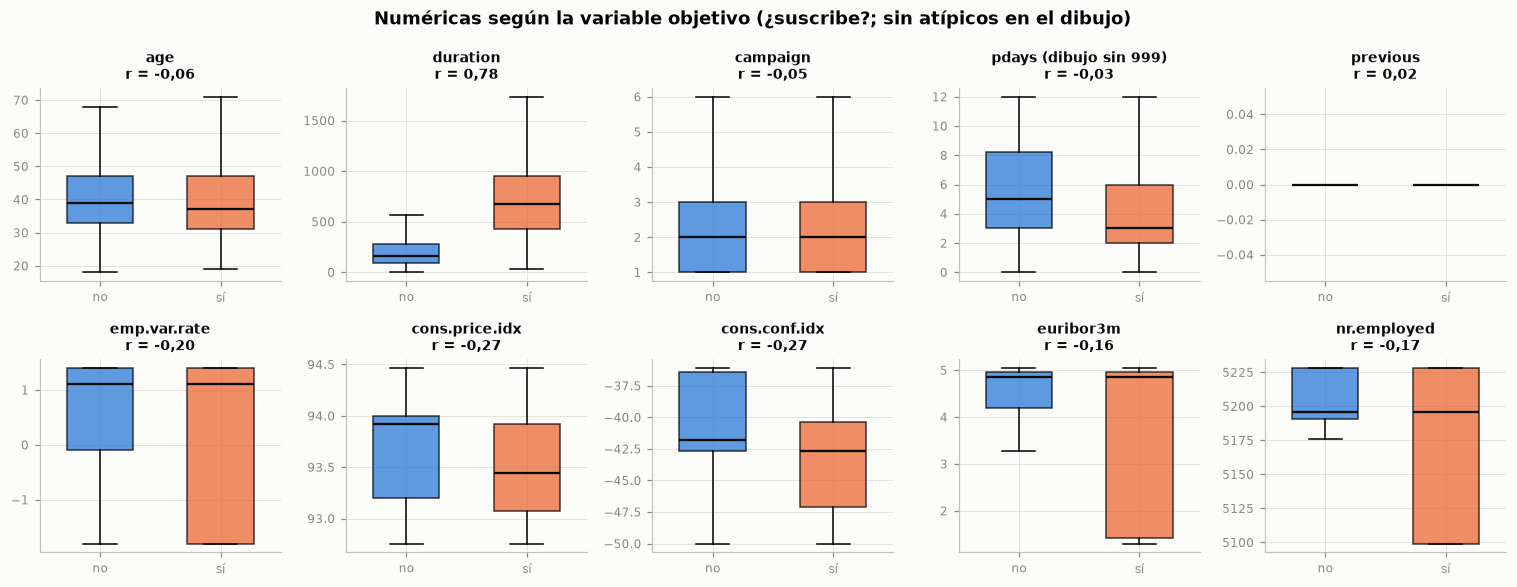

In [20]:
asoc = []
for c in NUMERICAS:
    pos, neg = tr.loc[tr["y"] == 1, c], tr.loc[tr["y"] == 0, c]
    u, p = stats.mannwhitneyu(pos, neg)
    asoc.append({"Variable": c, "Tipo": "numérica", "Prueba": "Mann-Whitney", "Estadístico": u, "p": p,
                 "Efecto": 2 * u / (len(pos) * len(neg)) - 1, "Medida de efecto": "r biserial de rangos"})
for c in CATEGORICAS:
    v, chi2, p = v_cramer(pd.crosstab(tr[c], tr["y"]))
    asoc.append({"Variable": c, "Tipo": "categórica", "Prueba": "χ²", "Estadístico": chi2, "p": p, "Efecto": v,
                 "Medida de efecto": "V de Cramér"})
asoc = pd.DataFrame(asoc).set_index("Variable")
asoc["p (Holm)"] = multipletests(asoc["p"], method="holm")[1]
asoc["p (FDR)"] = multipletests(asoc["p"], method="fdr_bh")[1]
X_im = tr[NUMERICAS + CATEGORICAS].copy()
for c in CATEGORICAS:
    X_im[c] = X_im[c].astype("category").cat.codes
im_vals = mutual_info_classif(X_im, tr["y"], discrete_features=[c in CATEGORICAS for c in X_im.columns],
                              random_state=SEED)
asoc["Información mutua"] = pd.Series(im_vals, index=X_im.columns)
asoc = asoc.sort_values("Información mutua", ascending=False)
asoc["Rango IM"] = np.arange(1, len(asoc) + 1)
tabla(asoc.drop(columns="p"), dec=4)

fig, axs = plt.subplots(2, 5, figsize=(14, 5.4))
for ax, c in zip(axs.ravel(), NUMERICAS):
    filtro = (tr["pdays"] != 999) if c == "pdays" else np.ones(len(tr), dtype=bool)
    datos = [tr.loc[(tr["y"] == k) & filtro, c] for k in (0, 1)]
    bp = ax.boxplot(datos, tick_labels=["no", "sí"], showfliers=False, patch_artist=True, widths=0.55,
                    medianprops={"color": TINTA, "lw": 1.5})
    for caja, col in zip(bp["boxes"], [AZUL, NARANJA]):
        caja.set_facecolor(col)
        caja.set_alpha(0.75)
    ax.set_title(("pdays (dibujo sin 999)" if c == "pdays" else c) + f"\nr = {num(asoc.loc[c, 'Efecto'], 2)}",
                 fontsize=9)
fig.suptitle("Numéricas según la variable objetivo (¿suscribe?; sin atípicos en el dibujo)")
plt.tight_layout()
plt.show()

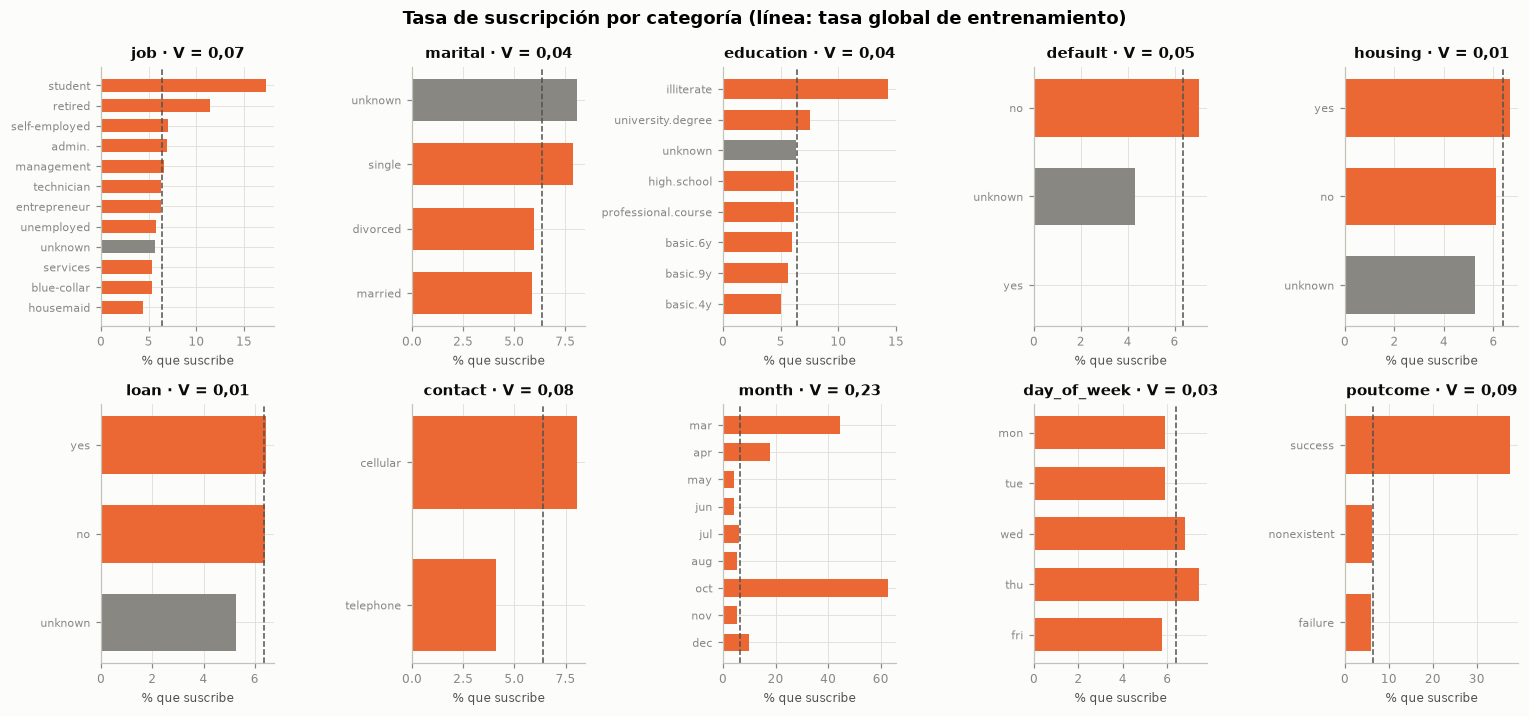

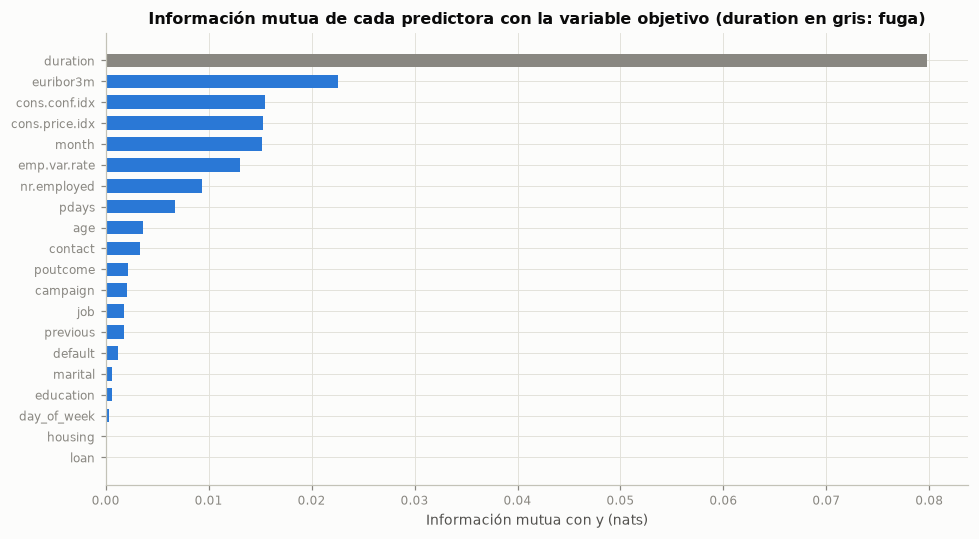

**Interpretación.** Entre las numéricas, el mayor efecto es el de `duration` (r = 0,78), seguido de `cons.conf.idx` (-0,27) y `cons.price.idx` (-0,27); `euribor3m`, `nr.employed` y `emp.var.rate` tienen efectos negativos: se suscribe más cuando la Euribor y el empleo son bajos. Entre las categóricas destacan `month` (V = 0,23) y `poutcome` (0,09): con `poutcome = success` suscribe el 37,5 %, frente al 6,2 % sin campaña previa. Por información mutua, las seis primeras son `duration`, `euribor3m`, `cons.conf.idx`, `cons.price.idx`, `month` y `emp.var.rate`. No son significativas tras Holm: `housing` y `loan`; en el caso de la edad, la información mutua (rango 9) sí detecta una relación, que no es monótona.

Entonces, sin `duration`, la mayor información mutua con `y` es la de `euribor3m`, `cons.conf.idx`, `cons.price.idx` y `month`, que describen sobre todo el contexto del periodo; el historial con el banco y el canal aportan menos, y los atributos del cliente, todavía menos. `duration` encabeza la lista, lo cual es una alerta de fuga más que una buena noticia. Las relaciones no son lineales en todos los casos: la tasa es del 12,9 % en menores de 25 años, del 6,1 % entre 25 y 60 y del 40,6 % en mayores de 60, un patrón en U que un término lineal en la edad no captura.

De ahí que se opte por conservar las predictoras con asociación no despreciable, excluir `duration` (sección 3.5) y documentar como limitación del modelo base que los efectos no lineales quedan sin capturar.

In [21]:
fig, axs = plt.subplots(2, 5, figsize=(14, 6.6))
tasa_global = 100 * tr["y"].mean()
for ax, c in zip(axs.ravel(), CATEGORICAS):
    t = tr.groupby(c)["y"].mean() * 100
    t = t.reindex(ORDEN_CAT[c]) if c in ORDEN_CAT else t.sort_values()
    ax.barh(t.index.astype(str), t.values, color=[GRIS if k == "unknown" else NARANJA for k in t.index], height=0.65)
    ax.axvline(tasa_global, color=TINTA_2, ls="--", lw=1)
    ax.set_title(f"{c} · V = {num(asoc.loc[c, 'Efecto'], 2)}", fontsize=9.5)
    ax.set_xlabel("% que suscribe", fontsize=8)
    ax.tick_params(axis="y", labelsize=7.5)
    if c in ORDEN_CAT:
        ax.invert_yaxis()
fig.suptitle("Tasa de suscripción por categoría (línea: tasa global de entrenamiento)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
im_orden = asoc["Información mutua"].sort_values()
ax.barh(im_orden.index, im_orden.values, color=[GRIS if k == "duration" else AZUL for k in im_orden.index],
        height=0.65)
ax.set_xlabel("Información mutua con y (nats)")
ax.set_title("Información mutua de cada predictora con la variable objetivo (duration en gris: fuga)")
plt.tight_layout()
plt.show()

num_ord = asoc[asoc["Tipo"] == "numérica"].sort_values("Efecto", key=np.abs, ascending=False)
cat_ord = asoc[asoc["Tipo"] == "categórica"].sort_values("Efecto", ascending=False)
no_sig = asoc.index[asoc["p (Holm)"] >= 0.05].tolist()
top_im = asoc.index[:6].tolist()
tasas_pout = tr.groupby("poutcome")["y"].mean()
tasa_edad = tr.groupby(pd.cut(tr["age"], [0, 24, 60, 120], labels=["<25", "25-60", ">60"]), observed=True)["y"].mean()
macro_neg = [c for c in ["euribor3m", "nr.employed", "emp.var.rate"] if asoc.loc[c, "Efecto"] < 0]
extremos = tasa_edad["<25"] > tasa_edad["25-60"] and tasa_edad[">60"] > tasa_edad["25-60"]
interpretar(
    f"Entre las numéricas, el mayor efecto es el de `{num_ord.index[0]}` (r = {num(num_ord.iloc[0]['Efecto'], 2)}), "
    f"seguido de `{num_ord.index[1]}` ({num(num_ord.iloc[1]['Efecto'], 2)}) y `{num_ord.index[2]}` "
    f"({num(num_ord.iloc[2]['Efecto'], 2)}); "
    + (f"{enumerar(macro_neg)} tienen efectos negativos: se suscribe más cuando la Euribor y el "
       "empleo son bajos. " if macro_neg else "")
    + f"Entre las categóricas destacan `{cat_ord.index[0]}` (V = {num(cat_ord.iloc[0]['Efecto'], 2)}) y "
    f"`{cat_ord.index[1]}` ({num(cat_ord.iloc[1]['Efecto'], 2)}): con `poutcome = success` suscribe el "
    f"{pct(tasas_pout['success'])}, frente al {pct(tasas_pout['nonexistent'])} sin campaña previa. Por información "
    f"mutua, las seis primeras son {enumerar(top_im)}. "
    + (f"No son significativas tras Holm: {enumerar(no_sig)}; en el caso de la edad, la información mutua "
       f"(rango {asoc.loc['age', 'Rango IM']}) sí detecta una relación, que no es monótona." if no_sig
       else "Todas las asociaciones son significativas tras Holm."),
    "Entonces, sin `duration`, la mayor información mutua con `y` es la de "
    f"{enumerar([c for c in asoc.index if c != 'duration'][:4])}, que describen sobre todo el contexto del periodo; el "
    "historial con el banco y el canal aportan menos, y los atributos del cliente, todavía menos. `duration` encabeza "
    "la lista, lo cual es una alerta de fuga más que una buena noticia. "
    + (f"Las relaciones no son lineales en todos los casos: la tasa es del {pct(tasa_edad['<25'])} en menores de 25 "
       f"años, del {pct(tasa_edad['25-60'])} entre 25 y 60 y del {pct(tasa_edad['>60'])} en mayores de 60, un patrón en "
       "U que un término lineal en la edad no captura." if extremos else
       "La tasa por edad no muestra un patrón en U marcado."),
    "De ahí que se opte por conservar las predictoras con asociación no despreciable, excluir `duration` (sección 3.5) "
    "y documentar como limitación del modelo base que los efectos no lineales quedan sin capturar.")

### 3.3.5 Matriz de correlación y multicolinealidad

El mapa de calor usa Spearman (robusto a la asimetría) entre las numéricas y la variable objetivo. La multicolinealidad se mide con el factor de inflación de la varianza (VIF) de las numéricas candidatas a predictoras (sin `duration`; `pdays` entra como indicador de contacto previo para que el código 999 no distorsione el cálculo). Se aplica la regla habitual: mientras alguna variable tenga VIF > 10, se elimina la de mayor VIF y se recalcula.

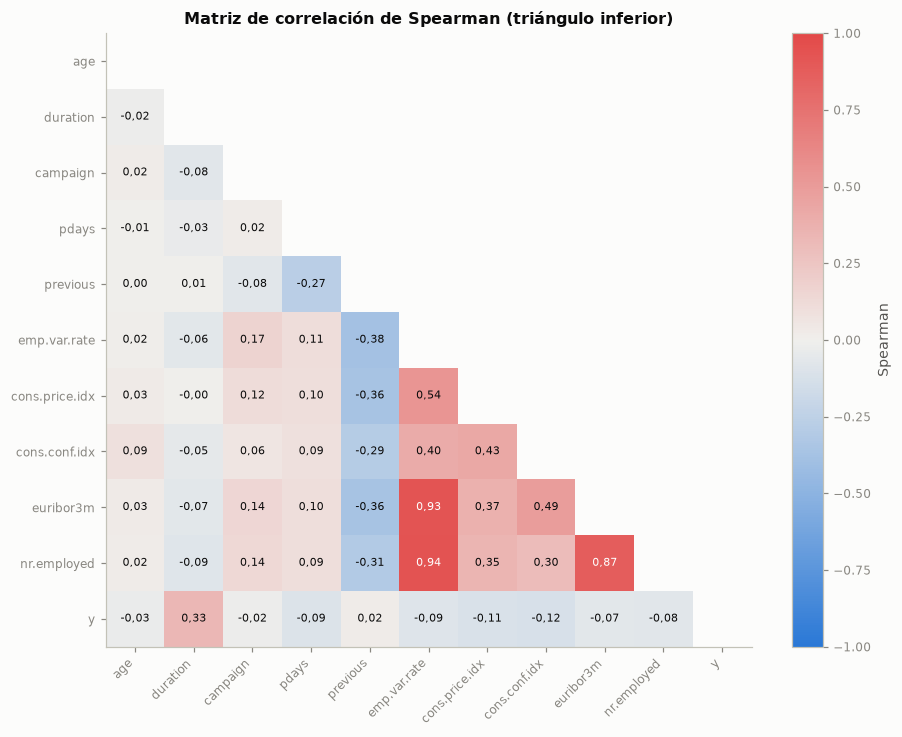

,VIF inicial,VIF tras la eliminación
age,"1,01","1,01"
campaign,"1,03","1,03"
cons.conf.idx,"6,76","1,47"
cons.price.idx,"6,03","1,83"
emp.var.rate,"45,36",—
euribor3m,"46,16",—
nr.employed,"37,03","2,26"
pdays,"1,09","1,09"
previous,"1,34","1,32"


Retiradas por VIF > 10 (en orden): ['euribor3m', 'emp.var.rate']


**Interpretación.** Las correlaciones más altas con `y` son las de `duration` (0,33), `cons.conf.idx` (-0,12) y `cons.price.idx` (-0,11). El VIF inicial es de 46,2 en `euribor3m`, 45,4 en `emp.var.rate`, 37,0 en `nr.employed`. La eliminación iterativa retira `euribor3m` y `emp.var.rate` y deja todos los VIF por debajo de 2,3.

Esto quiere decir que, con VIF tan altos, los coeficientes de las macro tendrían varianzas infladas y signos poco confiables; la información que se pierde al retirarlas es pequeña porque está contenida en las que quedan (por ejemplo, la correlación de Spearman entre `nr.employed` y `euribor3m` es 0,87).

Por tal motivo, se opta por excluir `euribor3m` y `emp.var.rate` del modelo base y verificar con validación cruzada que la pérdida de AUC sea despreciable (sección 3.7).

In [22]:
cols_corr = NUMERICAS + ["y"]
R = tr[cols_corr].corr(method="spearman")
R_inf = R.where(np.tril(np.ones(R.shape, dtype=bool), k=-1))
fig, ax = plt.subplots(figsize=(8.5, 6.8))
im = mapa_calor(ax, R_inf.to_numpy(), cols_corr, cols_corr, CMAP_DIV, -1, 1, dec=2)
fig.colorbar(im, ax=ax, label="Spearman")
ax.set_title("Matriz de correlación de Spearman (triángulo inferior)")
plt.tight_layout()
plt.show()

def vif_tabla(datos):
    Z = (datos - datos.mean()) / datos.std()
    Z = Z.assign(constante=1.0)
    return pd.Series([variance_inflation_factor(Z.to_numpy(), i) for i in range(Z.shape[1] - 1)],
                     index=datos.columns)

candidatas_vif = [c for c in NUMERICAS if c != "duration"]
base_vif = tr[candidatas_vif].astype(float).assign(pdays=(tr["pdays"] != 999).astype(float))
vif_inicial = vif_tabla(base_vif)
NUM_RETIRADAS_VIF, actuales = [], list(candidatas_vif)
while True:
    v = vif_tabla(base_vif[actuales])
    if v.max() <= 10:
        break
    NUM_RETIRADAS_VIF.append(v.idxmax())
    actuales.remove(v.idxmax())
vif_final = vif_tabla(base_vif[actuales])
tabla(pd.DataFrame({"VIF inicial": vif_inicial, "VIF tras la eliminación": vif_final}), dec=2)
print("Retiradas por VIF > 10 (en orden):", NUM_RETIRADAS_VIF)

r_y = R["y"].drop("y").sort_values(key=np.abs, ascending=False)
interpretar(
    f"Las correlaciones más altas con `y` son las de `{r_y.index[0]}` ({num(r_y.iloc[0], 2)}), `{r_y.index[1]}` "
    f"({num(r_y.iloc[1], 2)}) y `{r_y.index[2]}` ({num(r_y.iloc[2], 2)}). El VIF inicial es de "
    + ", ".join(f"{num(vif_inicial[c], 1)} en `{c}`" for c in vif_inicial.sort_values(ascending=False).index[:3])
    + f". La eliminación iterativa retira {enumerar(NUM_RETIRADAS_VIF)} y deja todos los VIF por "
    f"debajo de {num(vif_final.max(), 1)}.",
    "Esto quiere decir que, con VIF tan altos, los coeficientes de las macro tendrían varianzas infladas y signos poco "
    "confiables; la información que se pierde al retirarlas es pequeña porque está contenida en las que quedan (por "
    "ejemplo, la correlación de Spearman entre `nr.employed` y `euribor3m` es "
    f"{num(R.loc['nr.employed', 'euribor3m'], 2)}).",
    f"Por tal motivo, se opta por excluir {enumerar(NUM_RETIRADAS_VIF)} del modelo base y verificar con validación "
    "cruzada que la pérdida de AUC sea despreciable (sección 3.7).")

### 3.3.6 Selección preliminar de variables

La tabla resume la decisión para cada predictora con su evidencia. La decisión definitiva sobre `duration` y sobre las variables en observación se toma en la auditoría de fuga (sección 3.5).

In [23]:
seleccion = []
for c in NUMERICAS + CATEGORICAS:
    efecto = asoc.loc[c, "Efecto"]
    if c == "duration":
        dec, motivo = "Excluir", "Fuga: solo se conoce al terminar la llamada (sección 3.5)"
    elif c in NUM_RETIRADAS_VIF:
        dec, motivo = "Excluir", f"Redundante: VIF inicial {num(vif_inicial[c], 1)} (sección 3.3.5)"
    elif c in MACRO or c in ("month", "campaign"):
        dec, motivo = "Conservar, en observación", "Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
    else:
        dec, motivo = "Conservar", f"Asociación {magnitud(efecto, (0.1, 0.3, 0.5), ('despreciable', 'pequeña', 'mediana', 'grande'))} con y"
    seleccion.append({"Variable": c, "Medida de efecto": asoc.loc[c, "Medida de efecto"], "Efecto": efecto,
                      "Rango IM": asoc.loc[c, "Rango IM"], "Decisión preliminar": dec, "Motivo": motivo})
seleccion = pd.DataFrame(seleccion).set_index("Variable").sort_values("Rango IM")
tabla(seleccion, dec=3)

conservadas = seleccion.index[seleccion["Decisión preliminar"].str.startswith("Conservar")].tolist()
debiles = [c for c in conservadas if abs(seleccion.loc[c, "Efecto"]) < 0.1]
interpretar(
    f"Se conservan {len(conservadas)} de las {len(seleccion)} predictoras y se excluyen "
    f"{len(seleccion) - len(conservadas)} (`duration` por fuga y {enumerar(NUM_RETIRADAS_VIF)} por redundancia). Las "
    f"conservadas con efecto marginal despreciable (menor que 0,1) son {enumerar(debiles)}.",
    "Así mismo, las variables débiles se mantienen porque la regularización del modelo controla su aporte y porque un "
    "efecto marginal pequeño puede ser útil en combinación con otras; descartarlas aquí sería una selección "
    "prematura.",
    "En consecuencia, se procede a llevar al modelo base las predictoras conservadas, con la auditoría de fuga como "
    "filtro final.")

,Medida de efecto,Efecto,Rango IM,Decisión preliminar,Motivo
Variable,,,,,
duration,r biserial de rangos,"0,777",1,Excluir,Fuga: solo se conoce al terminar la llamada (sección 3.5)
euribor3m,r biserial de rangos,"-0,160",2,Excluir,"Redundante: VIF inicial 46,2 (sección 3.3.5)"
cons.conf.idx,r biserial de rangos,"-0,274",3,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
cons.price.idx,r biserial de rangos,"-0,266",4,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
month,V de Cramér,"0,230",5,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
emp.var.rate,r biserial de rangos,"-0,196",6,Excluir,"Redundante: VIF inicial 45,4 (sección 3.3.5)"
nr.employed,r biserial de rangos,"-0,168",7,"Conservar, en observación","Asociada con y, pero marca el periodo o depende del proceso de la campaña (sección 3.5)"
pdays,r biserial de rangos,"-0,028",8,Conservar,Asociación despreciable con y
age,r biserial de rangos,"-0,059",9,Conservar,Asociación despreciable con y


**Interpretación.** Se conservan 17 de las 20 predictoras y se excluyen 3 (`duration` por fuga y `euribor3m` y `emp.var.rate` por redundancia). Las conservadas con efecto marginal despreciable (menor que 0,1) son `pdays`, `age`, `contact`, `poutcome`, `campaign`, `job`, `previous`, `default`, `marital`, `education`, `day_of_week`, `housing` y `loan`.

Así mismo, las variables débiles se mantienen porque la regularización del modelo controla su aporte y porque un efecto marginal pequeño puede ser útil en combinación con otras; descartarlas aquí sería una selección prematura.

En consecuencia, se procede a llevar al modelo base las predictoras conservadas, con la auditoría de fuga como filtro final.

## 3.4 Análisis multivariado (enunciado, sección 2.4)

Se usa una matriz numérica estandarizada con las candidatas a predictoras: `age`, `log1p(campaign)`, `log1p(previous)`, un indicador de contacto previo (`pdays ≠ 999`) y los cinco indicadores macroeconómicos. Se incluyen todas las macro para ver la redundancia que detectó el VIF.

### 3.4.1 Reducción de dimensionalidad (PCA)

,CP1,CP2,CP3
age,"0,021","0,268","0,950"
log1p(campaign),"0,091","0,083","0,097"
log1p(previous),"-0,265","0,466","-0,102"
contacto_previo,"-0,100","0,814","-0,247"
emp.var.rate,"0,474","0,094","-0,048"
cons.price.idx,"0,382","0,058","-0,090"
cons.conf.idx,"0,348","0,093","0,052"
euribor3m,"0,471","0,101","-0,040"
nr.employed,"0,445","0,101","-0,050"


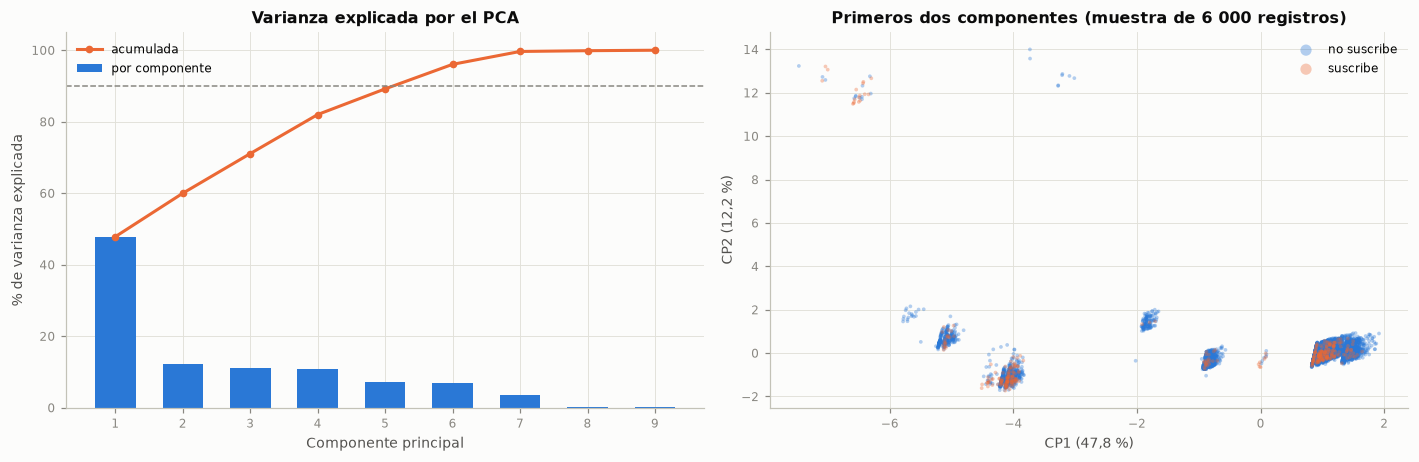

**Interpretación.** El primer componente explica el 47,8 % de la varianza y está dominado por `emp.var.rate`, `euribor3m`, `nr.employed` y `cons.price.idx`: es el eje del ciclo económico del periodo. El segundo (12,2 %) lo forman sobre todo `contacto_previo`, `log1p(previous)` y `age`. Se necesitan 4, 6 y 6 componentes para el 80 %, 90 % y 95 % de la varianza, de 9 variables. La media del CP1 es -1,12 entre quienes suscriben y 0,08 entre quienes no, pero en el plano CP1–CP2 las clases se superponen mucho.

Lo anterior indica que la dimensionalidad efectiva es menor que el número de variables por la redundancia de las macro, lo que respalda la eliminación por VIF. La superposición de clases anticipa que ninguna frontera lineal las separará bien: el techo de desempeño de un modelo lineal es moderado.

Por esta razón, se decide no usar el PCA como entrada del modelo base (perdería interpretabilidad sin ganar información) y mantener la selección por VIF.

In [24]:
M = pd.DataFrame({"age": tr["age"], "log1p(campaign)": np.log1p(tr["campaign"]),
                  "log1p(previous)": np.log1p(tr["previous"]), "contacto_previo": (tr["pdays"] != 999).astype(int)}
                 ).join(tr[MACRO])
Zm = StandardScaler().fit_transform(M)
pca = PCA(random_state=SEED).fit(Zm)
var_exp = pca.explained_variance_ratio_
acum = np.cumsum(var_exp)
k80, k90, k95 = (int(np.searchsorted(acum, u) + 1) for u in (0.80, 0.90, 0.95))

cargas = pd.DataFrame(pca.components_[:3].T, index=M.columns, columns=["CP1", "CP2", "CP3"])
tabla(cargas, dec=3)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
k = np.arange(1, len(var_exp) + 1)
axs[0].bar(k, 100 * var_exp, color=AZUL, width=0.6, label="por componente")
axs[0].plot(k, 100 * acum, color=NARANJA, marker="o", ms=4, label="acumulada")
axs[0].axhline(90, color=GRIS, ls="--", lw=1)
axs[0].set_xticks(k)
axs[0].set_xlabel("Componente principal")
axs[0].set_ylabel("% de varianza explicada")
axs[0].set_title("Varianza explicada por el PCA")
axs[0].legend()
rng = np.random.default_rng(SEED)
muestra = rng.choice(len(Zm), size=6000, replace=False)
P = pca.transform(Zm[muestra])[:, :2]
ym = tr["y"].to_numpy()[muestra]
for clase in (0, 1):
    axs[1].scatter(P[ym == clase, 0], P[ym == clase, 1], s=6, alpha=0.35, color=COLOR_Y[clase],
                   label=ETIQUETA_Y[clase], edgecolors="none")
axs[1].set_xlabel(f"CP1 ({num(100 * var_exp[0], 1)} %)")
axs[1].set_ylabel(f"CP2 ({num(100 * var_exp[1], 1)} %)")
axs[1].set_title("Primeros dos componentes (muestra de 6 000 registros)")
axs[1].legend(markerscale=3)
plt.tight_layout()
plt.show()

cp1_top = cargas["CP1"].abs().sort_values(ascending=False).index[:4].tolist()
cp1_clase = pd.Series(pca.transform(Zm)[:, 0]).groupby(tr["y"].to_numpy()).mean()
cp2_top = cargas["CP2"].abs().sort_values(ascending=False).index[:3].tolist()
interpretar(
    f"El primer componente explica el {pct(var_exp[0])} de la varianza y está dominado por "
    f"{enumerar(cp1_top)}"
    + (": es el eje del ciclo económico del periodo. " if sum(c in MACRO for c in cp1_top) >= 3 else ". ")
    + f"El segundo "
    f"({pct(var_exp[1])}) lo forman sobre todo {enumerar(cp2_top)}. Se necesitan {k80}, {k90} y "
    f"{k95} componentes para el 80 %, 90 % y 95 % de la varianza, de {M.shape[1]} variables. La media del CP1 es "
    f"{num(cp1_clase[1], 2)} entre quienes suscriben y {num(cp1_clase[0], 2)} entre quienes no, pero en el plano "
    "CP1–CP2 las clases se superponen mucho.",
    "Lo anterior indica que la dimensionalidad efectiva es menor que el número de variables por la redundancia de las "
    "macro, lo que respalda la eliminación por VIF. La superposición de clases anticipa que ninguna frontera lineal "
    "las separará bien: el techo de desempeño de un modelo lineal es moderado.",
    "Por esta razón, se decide no usar el PCA como entrada del modelo base (perdería interpretabilidad sin ganar "
    "información) y mantener la selección por VIF.")

### 3.4.2 Atípicos multivariados (Mahalanobis e Isolation Forest)

La distancia de Mahalanobis al cuadrado se compara con el cuantil 0,999 de una χ² con tantos grados de libertad como variables (la referencia es aproximada, porque las variables no son normales). Isolation Forest (`random_state = SEED`, 300 árboles, contaminación automática) no supone ninguna distribución.

,Registros,% del entrenamiento,% que suscribe (atípicos),% que suscribe (resto),% con contacto previo (atípicos)
"Mahalanobis (χ² 0,999)",430,"1,31","32,33","6,03","40,47"
Isolation Forest,13 021,"39,53","8,85","4,75","1,34"
Ambos métodos,430,"1,31","32,33","6,03","40,47"


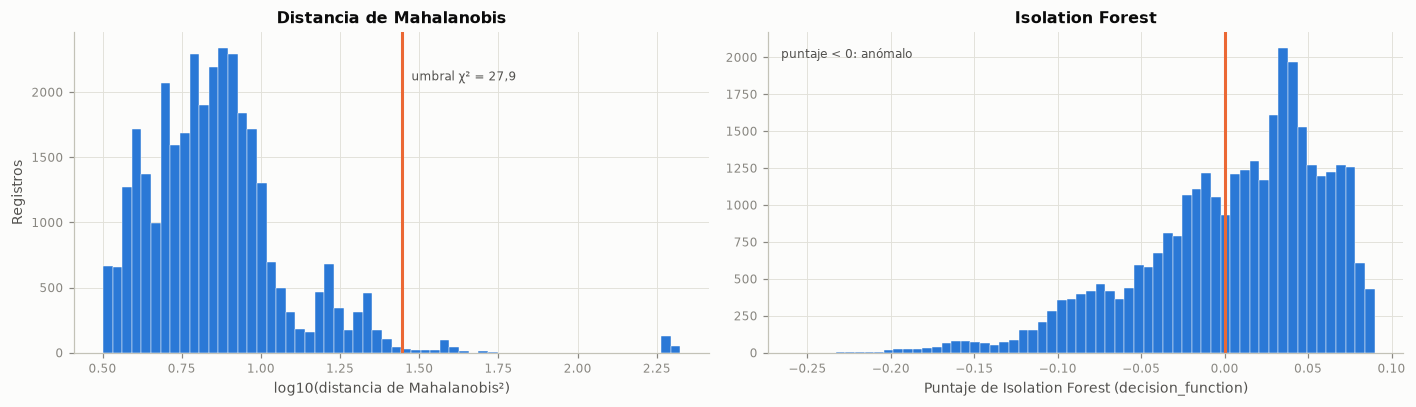

**Interpretación.** Mahalanobis marca 430 registros (1,3 %) e Isolation Forest 13 021 (39,5 %); coinciden 430 (Jaccard = 0,03). Entre los atípicos de Mahalanobis suscribe el 32,3 % frente al 6,0 % del resto, y el 40,5 % tuvo contacto previo.

En ese sentido, los atípicos multivariados corresponden a combinaciones poco frecuentes de valores plausibles, no a errores. Eliminarlos quitaría información valiosa de la clase minoritaria.

Por lo anterior, conviene no eliminar atípicos multivariados y mantener la transformación `log1p` y el escalado para limitar su palanca.

In [25]:
cov_inv = np.linalg.pinv(np.cov(Zm, rowvar=False))
d2 = np.einsum("ij,jk,ik->i", Zm, cov_inv, Zm)
umbral_d2 = stats.chi2.ppf(0.999, df=Zm.shape[1])
atip_maha = d2 > umbral_d2
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=SEED).fit(Zm)
puntaje_iso = iso.decision_function(Zm)
atip_iso = puntaje_iso < 0
ambos = atip_maha & atip_iso
yy = tr["y"].to_numpy()
atipicos_mv = pd.DataFrame({
    "Registros": [int(atip_maha.sum()), int(atip_iso.sum()), int(ambos.sum())],
    "% del entrenamiento": [100 * atip_maha.mean(), 100 * atip_iso.mean(), 100 * ambos.mean()],
    "% que suscribe (atípicos)": [100 * yy[atip_maha].mean(), 100 * yy[atip_iso].mean(), 100 * yy[ambos].mean()],
    "% que suscribe (resto)": [100 * yy[~atip_maha].mean(), 100 * yy[~atip_iso].mean(), 100 * yy[~ambos].mean()],
    "% con contacto previo (atípicos)": [100 * M["contacto_previo"][atip_maha].mean(),
                                         100 * M["contacto_previo"][atip_iso].mean(),
                                         100 * M["contacto_previo"][ambos].mean()]},
    index=["Mahalanobis (χ² 0,999)", "Isolation Forest", "Ambos métodos"])
tabla(atipicos_mv, dec=2)
jaccard = ambos.sum() / (atip_maha | atip_iso).sum()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].hist(np.log10(d2 + 1e-9), bins=60, color=AZUL, edgecolor=FONDO, linewidth=0.3)
axs[0].axvline(np.log10(umbral_d2), color=NARANJA, lw=2)
axs[0].text(np.log10(umbral_d2) + 0.03, axs[0].get_ylim()[1] * 0.85, f"umbral χ² = {num(umbral_d2, 1)}",
            color=TINTA_2, fontsize=8)
axs[0].set_xlabel("log10(distancia de Mahalanobis²)")
axs[0].set_ylabel("Registros")
axs[0].set_title("Distancia de Mahalanobis")
axs[1].hist(puntaje_iso, bins=60, color=AZUL, edgecolor=FONDO, linewidth=0.3)
axs[1].axvline(0, color=NARANJA, lw=2)
axs[1].text(0.02, 0.92, "puntaje < 0: anómalo", transform=axs[1].transAxes, color=TINTA_2, fontsize=8)
axs[1].set_xlabel("Puntaje de Isolation Forest (decision_function)")
axs[1].set_title("Isolation Forest")
plt.tight_layout()
plt.show()

interpretar(
    f"Mahalanobis marca {num(int(atip_maha.sum()))} registros ({pct(atip_maha.mean())}) e Isolation Forest "
    f"{num(int(atip_iso.sum()))} ({pct(atip_iso.mean())}); coinciden {num(int(ambos.sum()))} (Jaccard = "
    f"{num(jaccard, 2)}). Entre los atípicos de Mahalanobis suscribe el "
    f"{num(atipicos_mv.iloc[0]['% que suscribe (atípicos)'], 1)} % frente al "
    f"{num(atipicos_mv.iloc[0]['% que suscribe (resto)'], 1)} % del resto, y el "
    f"{num(atipicos_mv.iloc[0]['% con contacto previo (atípicos)'], 1)} % tuvo contacto previo.",
    ("En ese sentido, los atípicos multivariados no son errores: son sobre todo clientes con historial de campañas y "
     "contextos económicos poco frecuentes, justamente donde la tasa de suscripción es distinta. "
     if atipicos_mv.iloc[0]["% con contacto previo (atípicos)"] > 50 else
     "En ese sentido, los atípicos multivariados corresponden a combinaciones poco frecuentes de valores plausibles, "
     "no a errores. ")
    + ("Eliminarlos quitaría información valiosa de la clase minoritaria."
       if atipicos_mv.iloc[0]["% que suscribe (atípicos)"] > atipicos_mv.iloc[0]["% que suscribe (resto)"]
       else "Su tasa de suscripción no es mayor que la del resto, pero tampoco hay razón para eliminarlos."),
    "Por lo anterior, conviene no eliminar atípicos multivariados y mantener la transformación `log1p` y el escalado "
    "para limitar su palanca.")

### 3.4.3 Estructura de grupos (clustering exploratorio)

Se explora si existen subpoblaciones con K-medias (`random_state = SEED`, 10 inicializaciones) sobre la misma matriz estandarizada, eligiendo *k* entre 2 y 6 con el coeficiente de silueta calculado en una muestra de 5 000 registros.

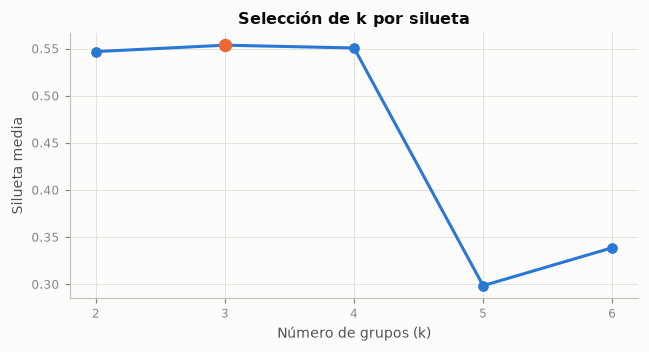

,registros,% que suscribe,Edad media,Euribor media,% con contacto previo,% de 2008,% del total
cluster,,,,,,,
0,27 637,"4,83","40,19","4,82","0,00","100,00","83,90"
1,174,"37,93","41,17","1,92","100,00","20,11","0,53"
2,5 129,"13,63","39,10","1,39","0,00","0,19","15,57"


**Interpretación.** La silueta es máxima con k = 3 (0,554). Los perfiles son: grupo 0: 83,9 % de los registros, Euribor media de 4,82 %, 100,0 % de 2008, 0,0 % con contacto previo y 4,8 % que suscribe; grupo 1: 0,5 % de los registros, Euribor media de 1,92 %, 20,1 % de 2008, 100,0 % con contacto previo y 37,9 % que suscribe; grupo 2: 15,6 % de los registros, Euribor media de 1,39 %, 0,2 % de 2008, 0,0 % con contacto previo y 13,6 % que suscribe. La edad media apenas cambia entre grupos (de 39,1 a 41,2 años).

Entonces, las subpoblaciones no son perfiles sociodemográficos sino combinaciones de **régimen económico** (antes y después de la caída de la Euribor) e **historial de contacto**, con tasas de éxito muy distintas. Esto refuerza que el periodo y el historial son los principales factores de variación y que un modelo evaluado al azar puede apoyarse en el periodo.

Así las cosas, se decide no crear variables de grupo para el modelo base (repetirían la información del periodo) y verificar la fuga temporal en la sección 3.6.

In [26]:
siluetas = {}
for k_ in range(2, 7):
    km = KMeans(n_clusters=k_, n_init=10, random_state=SEED).fit(Zm)
    siluetas[k_] = silhouette_score(Zm, km.labels_, sample_size=5000, random_state=SEED)
k_opt = max(siluetas, key=siluetas.get)
km = KMeans(n_clusters=k_opt, n_init=10, random_state=SEED).fit(Zm)
perfil = (pd.DataFrame({"cluster": km.labels_, "y": yy, "age": tr["age"].to_numpy(),
                        "euribor3m": tr["euribor3m"].to_numpy(), "contacto_previo": M["contacto_previo"].to_numpy(),
                        "anio_2008": (anio_tr.to_numpy() == 2008).astype(int)})
          .groupby("cluster").agg(registros=("y", "size"), suscribe=("y", "mean"), edad_media=("age", "mean"),
                                  euribor_media=("euribor3m", "mean"), contacto_previo=("contacto_previo", "mean"),
                                  de_2008=("anio_2008", "mean")))
perfil["% del total"] = 100 * perfil["registros"] / len(tr)
for c in ["suscribe", "contacto_previo", "de_2008"]:
    perfil[c] = 100 * perfil[c]
perfil = perfil.rename(columns={"suscribe": "% que suscribe", "contacto_previo": "% con contacto previo",
                                "de_2008": "% de 2008", "edad_media": "Edad media", "euribor_media": "Euribor media"})

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.plot(list(siluetas), list(siluetas.values()), color=AZUL, marker="o")
ax.scatter([k_opt], [siluetas[k_opt]], color=NARANJA, s=60, zorder=3)
ax.set_xticks(list(siluetas))
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Silueta media")
ax.set_title("Selección de k por silueta")
plt.tight_layout()
plt.show()
tabla(perfil, dec=2)

descr_grupos = "; ".join(
    f"grupo {g}: {num(r['% del total'], 1)} % de los registros, Euribor media de {num(r['Euribor media'], 2)} %, "
    f"{num(r['% de 2008'], 1)} % de 2008, {num(r['% con contacto previo'], 1)} % con contacto previo y "
    f"{num(r['% que suscribe'], 1)} % que suscribe" for g, r in perfil.iterrows())
interpretar(
    f"La silueta es máxima con k = {k_opt} ({num(siluetas[k_opt], 3)}). Los perfiles son: {descr_grupos}. La edad "
    f"media apenas cambia entre grupos (de {num(perfil['Edad media'].min(), 1)} a {num(perfil['Edad media'].max(), 1)} años).",
    "Entonces, las subpoblaciones no son perfiles sociodemográficos sino combinaciones de **régimen económico** (antes "
    "y después de la caída de la Euribor) e **historial de contacto**, con tasas de éxito muy distintas. Esto refuerza "
    "que el periodo y el historial son los principales factores de variación y que un modelo evaluado al azar puede "
    "apoyarse en el periodo.",
    "Así las cosas, se decide no crear variables de grupo para el modelo base (repetirían la información del periodo) "
    "y verificar la fuga temporal en la sección 3.6.")

## 3.5 Auditoría de fuga de datos (enunciado, sección 2.5)

### 3.5.1 Disponibilidad de cada variable en el momento de la predicción

El momento de predicción es **antes de realizar la llamada** de la campaña actual. No hay identificadores ni variables derivadas de forma explícita de la variable objetivo.

| Variable | ¿Disponible antes de la llamada? | Justificación | Decisión |
|---|---|---|---|
| `age`, `job`, `marital`, `education` | Sí | Atributos del cliente registrados en el banco | Usar |
| `default`, `housing`, `loan` | Sí | Situación crediticia registrada en el banco | Usar |
| `contact` | Sí | Canal por el que se hará la llamada | Usar |
| `month`, `day_of_week` | Sí | Fecha programada de la llamada (sin año) | Usar, en observación: `month` marca el periodo |
| `duration` | **No** | Solo se conoce al terminar la llamada; si vale 0, `y = no` (sección 1.6.4) | **Descartar** |
| `campaign` | Parcial | Cuenta los contactos de la campaña incluido el actual, así que se conoce antes de cada llamada; pero es razonable suponer que la campaña deja de llamar a quien ya suscribió, de modo que su valor puede depender del resultado | Usar, en observación |
| `pdays`, `previous`, `poutcome` | Sí | Historial de campañas anteriores | Usar |
| Indicadores macroeconómicos | Parcial | Son públicos, pero los trimestrales y mensuales se publican con rezago: el valor del periodo en curso podría no conocerse el día de la llamada | Usar las que deja el VIF, en observación (fuga temporal, sección 3.6) |

### 3.5.2 Desempeño univariado de cada variable

Para cada predictora se ajusta una regresión logística con esa sola variable (codificación *one-hot* si es categórica) y se calcula el AUC promedio de los cinco pliegues de la **validación temporal** (sección 3). Un AUC cercano a 1 sería una alerta de fuga o de variable sustituta del objetivo.

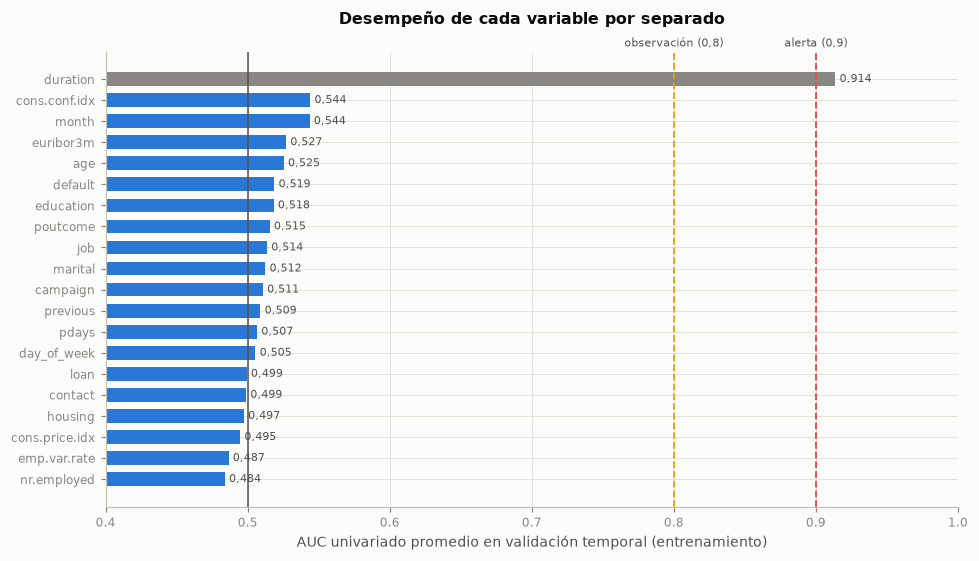

**Interpretación.** `duration` alcanza el umbral de alerta de 0,9. La de mayor AUC es `duration` (0,914); sin ella, la mejor es `cons.conf.idx` (0,544), seguida de `month` (0,544) y `euribor3m` (0,527). 19 de las 19 predictoras sin `duration` quedan por debajo de 0,55.

De esta forma, el AUC univariado de `duration` supera el umbral de alerta, lo que confirma su fuga. La fuga se identifica por la disponibilidad (sección 3.5.1) y por la ganancia que produce dentro del modelo completo (sección 3.5.3). Con validación temporal, la mayoría de las predictoras ordena a los clientes del periodo siguiente apenas mejor que el azar: su relación con `y` no se sostiene bien de un periodo a otro.

Por ello, se procede a descartar `duration` y mantener en observación las macro, `month` y `campaign`.

In [27]:
def pipeline_auditoria(numericas, categoricas, C=1.0):
    """Instrumento de auditoría: escalado + one-hot + regresión logística (no es el modelo final)."""
    pre = ColumnTransformer([("num", StandardScaler(), numericas),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)])
    return Pipeline([("pre", pre), ("lr", LogisticRegression(C=C, max_iter=5000))])


auc_uni = {}
for c in NUMERICAS + CATEGORICAS:
    p_uni = pipeline_auditoria([c] if c in NUMERICAS else [], [c] if c in CATEGORICAS else [])
    auc_uni[c] = cross_validate(p_uni, X_tr[[c]], y_tr, cv=tss, scoring="roc_auc")["test_score"].mean()
auc_uni = pd.Series(auc_uni).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(auc_uni.index, auc_uni.values, color=[GRIS if c == "duration" else AZUL for c in auc_uni.index], height=0.65)
ax.axvline(0.5, color=TINTA_2, lw=1)
ax.axvline(0.8, color=AMARILLO, ls="--", lw=1.2)
ax.axvline(0.9, color=ROJO, ls="--", lw=1.2)
ax.text(0.8, 1.005, "observación (0,8)", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
        fontsize=7.5, color=TINTA_2)
ax.text(0.9, 1.005, "alerta (0,9)", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5,
        color=TINTA_2)
ax.set_xlim(min(0.4, auc_uni.min() - 0.03), 1.0)
ax.set_xlabel("AUC univariado promedio en validación temporal (entrenamiento)")
ax.set_title("Desempeño de cada variable por separado", pad=18)
for i, v in enumerate(auc_uni.values):
    ax.text(v + 0.003, i, num(v, 3), va="center", fontsize=7.5, color=TINTA_2)
plt.tight_layout()
plt.show()

sin_dur = auc_uni.drop("duration")
alertas = auc_uni.index[auc_uni >= 0.9].tolist()
cerca_azar = sin_dur.index[sin_dur < 0.55].tolist()
interpretar(
    (f"{enumerar(alertas)} alcanza el umbral de alerta de 0,9. " if alertas else
     "Ninguna variable alcanza el umbral de alerta de 0,9. ")
    + f"La de mayor AUC es `{auc_uni.index[-1]}` ({num(auc_uni.iloc[-1], 3)}); sin ella, la mejor es "
    f"`{sin_dur.index[-1]}` ({num(sin_dur.iloc[-1], 3)}), seguida de `{sin_dur.index[-2]}` ({num(sin_dur.iloc[-2], 3)}) y "
    f"`{sin_dur.index[-3]}` ({num(sin_dur.iloc[-3], 3)}). {len(cerca_azar)} de las {len(sin_dur)} predictoras sin "
    "`duration` quedan por debajo de 0,55.",
    ("De esta forma, el AUC univariado por sí solo no detecta la fuga de `duration`: su valor es alto pero no extremo. "
     if auc_uni["duration"] < 0.9 else
     "De esta forma, el AUC univariado de `duration` supera el umbral de alerta, lo que confirma su fuga. ")
    + "La fuga se identifica por la disponibilidad (sección 3.5.1) y por la ganancia que produce dentro del modelo "
    "completo (sección 3.5.3). Con validación temporal, la mayoría de las predictoras ordena a los clientes del "
    "periodo siguiente apenas mejor que el azar: su relación con `y` no se sostiene bien de un periodo a otro.",
    "Por ello, se procede a descartar `duration` y mantener en observación las macro, `month` y `campaign`.")

### 3.5.3 Efecto de `duration` en el modelo completo

Se compara el AUC de la validación temporal (sección 3, solo entrenamiento) del instrumento de auditoría con todas las predictoras salvo `duration` y con `duration` incluida.

In [28]:
num_sin_dur = [c for c in NUMERICAS if c != "duration"]
cv_sin = cross_validate(pipeline_auditoria(num_sin_dur, CATEGORICAS), X_tr, y_tr, cv=tss,
                        scoring=["roc_auc", "average_precision"])
cv_con = cross_validate(pipeline_auditoria(NUMERICAS, CATEGORICAS), X_tr, y_tr, cv=tss,
                        scoring=["roc_auc", "average_precision"])
efecto_dur = pd.DataFrame({
    "AUC media": [cv_sin["test_roc_auc"].mean(), cv_con["test_roc_auc"].mean()],
    "AUC desv. est.": [cv_sin["test_roc_auc"].std(), cv_con["test_roc_auc"].std()],
    "AUC-PR media": [cv_sin["test_average_precision"].mean(), cv_con["test_average_precision"].mean()]},
    index=["Sin duration", "Con duration"])
tabla(efecto_dur, dec=3)
auc_sin_dur, auc_con_dur = efecto_dur["AUC media"]
interpretar(
    f"Agregar `duration` sube el AUC de validación de {num(auc_sin_dur, 3)} a {num(auc_con_dur, 3)} y el AUC-PR de "
    f"{num(efecto_dur.iloc[0, 2], 3)} a {num(efecto_dur.iloc[1, 2], 3)}.",
    "Sin embargo, ese salto no es capacidad predictiva utilizable: proviene de una variable que se conoce cuando la "
    "llamada ya terminó y, por tanto, cuando el resultado ya se sabe. Un modelo con `duration` sería inútil para "
    "decidir a quién llamar y su desempeño reportado sería engañoso.",
    "En consecuencia, se excluye `duration` de forma definitiva; el AUC sin ella es la referencia honesta para el "
    "modelo base.")

,AUC media,AUC desv. est.,AUC-PR media
Sin duration,"0,540","0,073","0,087"
Con duration,"0,856","0,084","0,401"


**Interpretación.** Agregar `duration` sube el AUC de validación de 0,540 a 0,856 y el AUC-PR de 0,087 a 0,401.

Sin embargo, ese salto no es capacidad predictiva utilizable: proviene de una variable que se conoce cuando la llamada ya terminó y, por tanto, cuando el resultado ya se sabe. Un modelo con `duration` sería inútil para decidir a quién llamar y su desempeño reportado sería engañoso.

En consecuencia, se excluye `duration` de forma definitiva; el AUC sin ella es la referencia honesta para el modelo base.

### 3.5.4 Duplicados y entidades repetidas entre entrenamiento y prueba

Se verifica si hay registros de prueba cuyo vector de predictoras aparece también en entrenamiento: con las 20 predictoras (incluida `duration`) y con las 19 que usaría un modelo sin `duration`. No es posible verificar clientes repetidos porque no hay identificador (sección 1.5).

In [29]:
def huella(datos, columnas):
    return pd.util.hash_pandas_object(datos[columnas], index=False)


h_tr20, h_te20 = huella(X_tr, NUMERICAS + CATEGORICAS), huella(X_te, NUMERICAS + CATEGORICAS)
h_tr19, h_te19 = huella(X_tr, PRED_SIN_DUR), huella(X_te, PRED_SIN_DUR)
rep20 = h_te20.isin(set(h_tr20)).to_numpy()
rep19 = h_te19.isin(set(h_tr19)).to_numpy()
# Concordancia de la etiqueta: y de prueba frente a la y mayoritaria del mismo perfil en entrenamiento
y_perfil_tr = pd.Series(y_tr.to_numpy(), index=h_tr19.to_numpy()).groupby(level=0).mean()
y_perfil = h_te19[rep19].map(y_perfil_tr).to_numpy()
concord = ((y_perfil >= 0.5).astype(int) == y_te.to_numpy()[rep19]).mean()
concord_mayoritaria = 1 - y_te.to_numpy()[rep19].mean()
en_corte = (periodo_te.to_numpy()[rep19] == periodo_corte).mean() if rep19.any() else 0.0
cruce = pd.DataFrame({
    "Registros de prueba": [int(rep20.sum()), int(rep19.sum())],
    "% de prueba": [100 * rep20.mean(), 100 * rep19.mean()]},
    index=["Vector de 20 predictoras (con duration) presente en entrenamiento",
           "Vector de 19 predictoras (sin duration) presente en entrenamiento"])
tabla(cruce, dec=2)
print(f"En los perfiles repetidos sin duration, la etiqueta de prueba coincide con la mayoritaria del perfil en "
      f"entrenamiento en el {pct(concord)} de los casos (tasa de positivos en esos registros: "
      f"{pct(y_te.to_numpy()[rep19].mean())}).")

interpretar(
    f"Tras eliminar los duplicados exactos, {int(rep20.sum())} registros de prueba repiten el vector completo de "
    f"entrenamiento. Sin `duration`, {num(int(rep19.sum()))} registros de prueba ({pct(rep19.mean(), 2)}) comparten "
    f"perfil con alguno de entrenamiento, y su etiqueta coincide con la mayoritaria de ese perfil en el "
    f"{pct(concord)} de los casos. El {pct(en_corte)} de esos registros pertenece a {periodo_corte}, el mes en que "
    "cae el corte, porque solo ahí coinciden también los indicadores macroeconómicos.",
    ("Es decir, son tan pocos que no pueden inflar la evaluación: con la partición cronológica, los perfiles de prueba "
     "casi nunca coinciden con los de entrenamiento, porque los indicadores macroeconómicos cambian entre periodos."
     if rep19.sum() < 30 else
     "Es decir, los perfiles compartidos son combinaciones frecuentes de atributos gruesos en el mismo periodo (mismas "
     f"macro), no copias de un mismo contacto; su concordancia de etiqueta ({pct(concord)}) es "
     + ("similar a" if abs(concord - concord_mayoritaria) < 0.03 else ("mayor que" if concord > concord_mayoritaria else "menor que"))
     + f" la de predecir siempre la clase mayoritaria en esos registros ({pct(concord_mayoritaria)}) y representan solo "
     f"el {pct(rep19.mean(), 2)} de la prueba, así que no inflan la evaluación de forma apreciable."),
    "Por tanto, no hay fuga por duplicados que corregir; el riesgo relevante es el temporal, que se analiza a "
    "continuación.")

,Registros de prueba,% de prueba
Vector de 20 predictoras (con duration) presente en entrenamiento,0,"0,00"
Vector de 19 predictoras (sin duration) presente en entrenamiento,2,"0,02"


En los perfiles repetidos sin duration, la etiqueta de prueba coincide con la mayoritaria del perfil en entrenamiento en el 50,0 % de los casos (tasa de positivos en esos registros: 0,0 %).


**Interpretación.** Tras eliminar los duplicados exactos, 0 registros de prueba repiten el vector completo de entrenamiento. Sin `duration`, 2 registros de prueba (0,02 %) comparten perfil con alguno de entrenamiento, y su etiqueta coincide con la mayoritaria de ese perfil en el 50,0 % de los casos. El 100,0 % de esos registros pertenece a 2009-05, el mes en que cae el corte, porque solo ahí coinciden también los indicadores macroeconómicos.

Es decir, son tan pocos que no pueden inflar la evaluación: con la partición cronológica, los perfiles de prueba casi nunca coinciden con los de entrenamiento, porque los indicadores macroeconómicos cambian entre periodos.

Por tanto, no hay fuga por duplicados que corregir; el riesgo relevante es el temporal, que se analiza a continuación.

## 3.6 Componente temporal y verificación de fuga temporal (enunciado, secciones 2.5 y 2.6)

El archivo no trae fechas, pero el orden documentado de los registros permite reconstruir el año, el mes y el día de contacto (sección 1.5). Con esa variable temporal, y solo con el conjunto de entrenamiento, se cubren los puntos de la sección 2.6 del enunciado:

- **3.6.1** Contexto económico y deriva de las covariables entre periodos.
- **3.6.2** Fuga temporal: validación aleatoria frente a validación temporal y poder predictivo del periodo.
- **3.6.3** Validación de la variable temporal, serie diaria y semanal, medias y varianzas móviles y cambios de régimen.
- **3.6.4** Descomposición STL, estacionariedad (ADF y KPSS), dependencia temporal (ACF y PACF) y correlación cruzada con las macro.
- **3.6.5** Deriva de concepto: si la relación de cada predictora con la variable objetivo cambia entre años.

La serie mensual del entrenamiento es demasiado corta para una descomposición estacional, que exige al menos dos ciclos completos; por eso la descomposición y las pruebas usan la **serie diaria** de días de contacto. Estos resultados respaldan la partición cronológica (sección 2), la validación temporal (sección 3), la elección de la regularización (sección 4.1) y la recalibración del intercepto (sección 4.7.1).

### 3.6.1 Contexto económico y deriva entre periodos

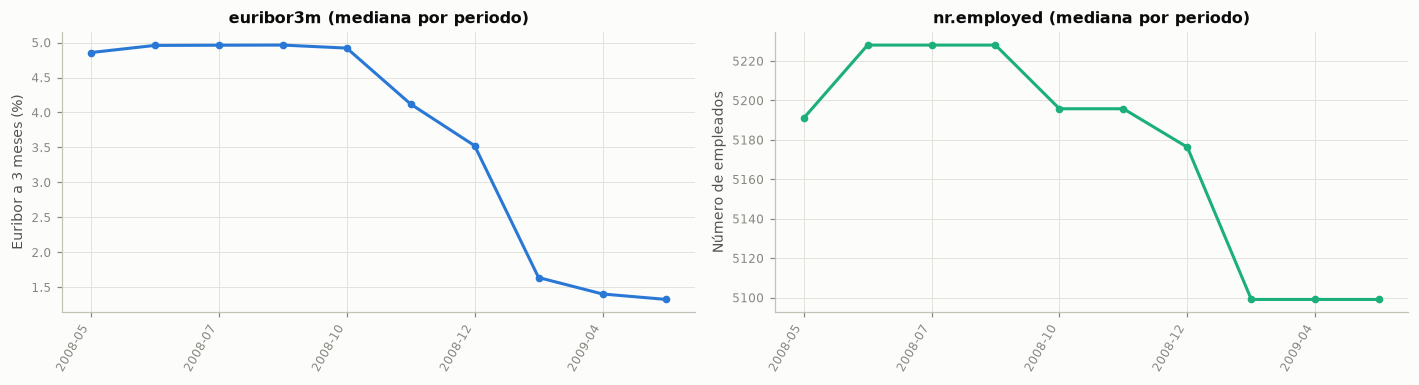

,Medida,Deriva,p (Holm)
Variable,,,
nr.employed,KS,"1,000","0,000"
cons.conf.idx,KS,"1,000","0,000"
emp.var.rate,KS,"1,000","0,000"
euribor3m,KS,"1,000","0,000"
cons.price.idx,KS,"1,000","0,000"
month,V de Cramér,"0,755","0,000"
poutcome,V de Cramér,"0,386","0,000"
contact,V de Cramér,"0,319","0,000"
previous,KS,"0,267","0,000"


**Interpretación.** La Euribor pasa de una mediana de 4,86 % en 2008-05 a 1,33 % en 2009-05. Entre 2008 y el tramo de 2009 incluido en entrenamiento (2009-03 a 2009-05) la mayor deriva está en `nr.employed` (KS = 1,00), `cons.conf.idx` (KS = 1,00), `emp.var.rate` (KS = 1,00), `euribor3m` (KS = 1,00), y la tasa de suscripción pasa del 4,8 % al 14,5 %.

Lo anterior indica que hay deriva de covariables (*covariate shift*: cambian las macro, el canal y el historial) y deriva de la prevalencia (la tasa base se multiplica). Un modelo entrenado con un periodo y aplicado en otro enfrenta distribuciones distintas, y las macro le permiten reconocer el periodo cuando la validación es aleatoria.

De ahí que se proceda a cuantificar el poder predictivo del periodo y a comparar la validación aleatoria con la temporal.

In [30]:
macro_periodo = tr.groupby(periodo_tr)[["euribor3m", "nr.employed"]].median()
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, c, col in zip(axs, ["euribor3m", "nr.employed"], [AZUL, AGUAMARINA]):
    ax.plot(np.arange(len(macro_periodo)), macro_periodo[c], color=col, marker="o", ms=4)
    ax.set_xticks(np.arange(len(macro_periodo))[::2], macro_periodo.index[::2], rotation=60, ha="right")
    ax.set_title(f"{c} (mediana por periodo)")
axs[0].set_ylabel("Euribor a 3 meses (%)")
axs[1].set_ylabel("Número de empleados")
plt.tight_layout()
plt.show()

despues = anio_tr >= 2009
deriva = []
for c in num_sin_dur:
    ks = stats.ks_2samp(tr.loc[~despues, c], tr.loc[despues, c])
    deriva.append({"Variable": c, "Medida": "KS", "Deriva": ks.statistic, "p": ks.pvalue})
for c in CATEGORICAS:
    v, _, p = v_cramer(pd.crosstab(tr[c], despues))
    deriva.append({"Variable": c, "Medida": "V de Cramér", "Deriva": v, "p": p})
deriva = pd.DataFrame(deriva).set_index("Variable")
deriva["p (Holm)"] = multipletests(deriva["p"], method="holm")[1]
deriva = deriva.drop(columns="p").sort_values("Deriva", ascending=False)
tabla(deriva, dec=3)
tasa_08, tasa_0910 = tr.loc[~despues, "y"].mean(), tr.loc[despues, "y"].mean()
tramo_despues = f"{periodo_tr[despues].iloc[0]} a {periodo_tr[despues].iloc[-1]}"
top_deriva = ", ".join(f"`{c}` ({r.Medida} = {num(r.Deriva, 2)})" for c, r in deriva.head(4).iterrows())

interpretar(
    f"La Euribor pasa de una mediana de {num(macro_periodo['euribor3m'].iloc[0], 2)} % en {macro_periodo.index[0]} a "
    f"{num(macro_periodo['euribor3m'].iloc[-1], 2)} % en {macro_periodo.index[-1]}. Entre 2008 y el tramo de 2009 "
    f"incluido en entrenamiento ({tramo_despues}) la mayor deriva está en {top_deriva}, "
    f"y la tasa de suscripción pasa del {pct(tasa_08)} al {pct(tasa_0910)}.",
    "Lo anterior indica que hay deriva de covariables (*covariate shift*: cambian las macro, el canal y el historial) "
    "y deriva de la prevalencia (la tasa base se multiplica). Un modelo entrenado con un periodo y aplicado en otro "
    "enfrenta distribuciones distintas, y las macro le permiten reconocer el periodo cuando la validación es "
    "aleatoria.",
    "De ahí que se proceda a cuantificar el poder predictivo del periodo y a comparar la validación aleatoria con la "
    "temporal.")

### 3.6.2 Validación aleatoria frente a validación temporal

Se comparan tres resultados con el instrumento de auditoría (todas las predictoras salvo `duration`):

1. **Validación estratificada aleatoria** (cinco pliegues, `SEED`): el contraste, es decir, lo que se habría obtenido ignorando el tiempo.
2. **Modelo que solo conoce el periodo** (año-mes reconstruido, codificado *one-hot*), con la misma validación aleatoria: mide cuánto AUC se obtiene sin saber nada del cliente.
3. **Validación temporal** con `TimeSeriesSplit` y separación de un día (sección 3): siempre se ajusta con el pasado y se valida con el bloque siguiente.

Además, se calcula el AUC de las predicciones fuera de pliegue de la validación aleatoria **dentro de cada año**, que mide la capacidad de ordenar clientes del mismo periodo.

,Ajusta hasta,Valida desde,Valida hasta,% positivos (ajuste),% positivos (validación),AUC,AUC-PR
Pliegue,,,,,,,
1,2008-05,2008-05,2008-06,"2,910","3,880","0,528","0,040"
2,2008-06,2008-06,2008-07,"3,409","6,047","0,565","0,073"
3,2008-07,2008-07,2008-08,"4,266","5,920","0,498","0,061"
4,2008-08,2008-08,2008-11,"4,727","5,446","0,446","0,052"
5,2008-11,2008-11,2009-05,"4,821","14,026","0,663","0,208"


,AUC media,AUC mín.,AUC máx.,AUC-PR media
Aleatoria estratificada (todas las predictoras),"0,670","0,650","0,694","0,205"
"Aleatoria, solo el periodo (año-mes)","0,660",—,—,"0,161"
Temporal TimeSeriesSplit con separación (todas las predictoras),"0,540","0,446","0,663","0,087"


,AUC fuera de pliegue dentro del año,Registros
Año,,
2008,"0,582",27 682
2009,"0,741",5 258


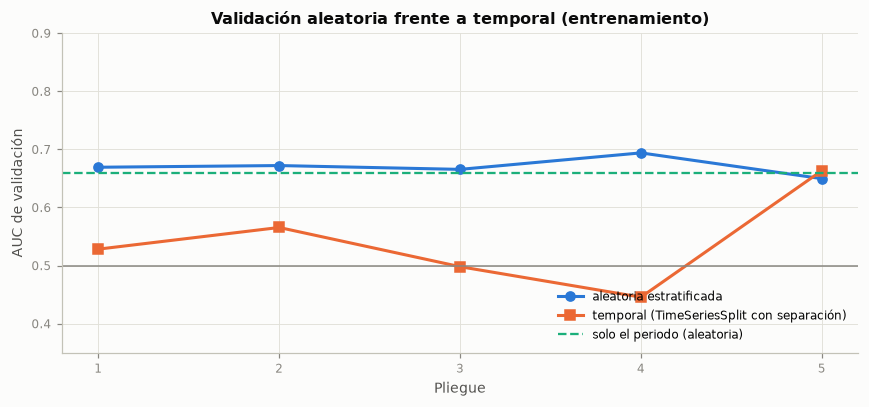

**Interpretación.** Con validación aleatoria el AUC es 0,670; un modelo que solo conoce el año-mes logra 0,660, es decir, el 98 % de ese valor sin ninguna información del cliente. Con validación temporal el AUC cae a 0,540 en promedio (de 0,446 a 0,663), con 2 pliegues por debajo de 0,5, es decir, peores que el azar. Dentro de cada año, el AUC de las predicciones aleatorias es de 0,582 en 2008 y 0,741 en 2009; en 2008 es menor que el global, señal de que parte del AUC aleatorio viene de distinguir periodos.

Esto quiere decir que la evaluación aleatoria está inflada por **fuga temporal**: entrenamiento y validación comparten periodos, y las macro y `month` permiten al modelo reconocer el periodo y su tasa base. Ese conocimiento no existe cuando se predice una campaña futura, cuyo contexto y prevalencia aún no se han observado. La validación temporal mide mejor el desempeño de uso real, aunque es variable porque los periodos son muy distintos entre sí.

En suma, esta evidencia, obtenida solo con entrenamiento, respalda la partición cronológica (sección 2) y la validación temporal (sección 3) como esquema principal; la validación aleatoria queda únicamente como contraste (sección 4.10).

In [31]:
VARS_AUDIT_NUM, VARS_AUDIT_CAT = num_sin_dur, CATEGORICAS
modelo_aud = pipeline_auditoria(VARS_AUDIT_NUM, VARS_AUDIT_CAT)
oof_aud = cross_val_predict(modelo_aud, X_tr, y_tr, cv=skf, method="predict_proba")[:, 1]
cv_aleatoria = cross_validate(modelo_aud, X_tr, y_tr, cv=skf, scoring=["roc_auc", "average_precision"])

solo_periodo = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=5000))
oof_periodo = cross_val_predict(solo_periodo, periodo_tr.to_frame(), y_tr, cv=skf, method="predict_proba")[:, 1]
auc_periodo = roc_auc_score(y_tr, oof_periodo)

filas_tss = []
for k_, (i_ent, i_val) in enumerate(tss.split(X_tr), start=1):
    m_ = pipeline_auditoria(VARS_AUDIT_NUM, VARS_AUDIT_CAT).fit(X_tr.iloc[i_ent], y_tr.iloc[i_ent])
    prob = m_.predict_proba(X_tr.iloc[i_val])[:, 1]
    filas_tss.append({"Pliegue": k_, "Ajusta hasta": periodo_tr.iloc[i_ent[-1]],
                      "Valida desde": periodo_tr.iloc[i_val[0]], "Valida hasta": periodo_tr.iloc[i_val[-1]],
                      "% positivos (ajuste)": 100 * y_tr.iloc[i_ent].mean(),
                      "% positivos (validación)": 100 * y_tr.iloc[i_val].mean(),
                      "AUC": roc_auc_score(y_tr.iloc[i_val], prob),
                      "AUC-PR": average_precision_score(y_tr.iloc[i_val], prob)})
cv_tss = pd.DataFrame(filas_tss).set_index("Pliegue")
tabla(cv_tss, dec=3)

comparacion_val = pd.DataFrame({
    "AUC media": [cv_aleatoria["test_roc_auc"].mean(), auc_periodo, cv_tss["AUC"].mean()],
    "AUC mín.": [cv_aleatoria["test_roc_auc"].min(), np.nan, cv_tss["AUC"].min()],
    "AUC máx.": [cv_aleatoria["test_roc_auc"].max(), np.nan, cv_tss["AUC"].max()],
    "AUC-PR media": [cv_aleatoria["test_average_precision"].mean(),
                     average_precision_score(y_tr, oof_periodo), cv_tss["AUC-PR"].mean()]},
    index=["Aleatoria estratificada (todas las predictoras)", "Aleatoria, solo el periodo (año-mes)",
           "Temporal TimeSeriesSplit con separación (todas las predictoras)"])
tabla(comparacion_val, dec=3)

auc_por_anio = pd.Series({a: roc_auc_score(y_tr[anio_tr == a], oof_aud[(anio_tr == a).to_numpy()])
                          for a in sorted(anio_tr.unique())})
tabla(pd.DataFrame({"AUC fuera de pliegue dentro del año": auc_por_anio,
                    "Registros": anio_tr.value_counts().sort_index()}).rename_axis("Año"), dec=3)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(1, 6), cv_aleatoria["test_roc_auc"], color=AZUL, marker="o", label="aleatoria estratificada")
ax.plot(cv_tss.index, cv_tss["AUC"], color=NARANJA, marker="s", label="temporal (TimeSeriesSplit con separación)")
ax.axhline(auc_periodo, color=AGUAMARINA, ls="--", lw=1.5, label="solo el periodo (aleatoria)")
ax.axhline(0.5, color=GRIS, lw=1)
ax.set_xticks(range(1, 6))
ax.set_xlabel("Pliegue")
ax.set_ylabel("AUC de validación")
ax.set_ylim(0.35, 0.9)
ax.set_title("Validación aleatoria frente a temporal (entrenamiento)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

auc_alea = cv_aleatoria["test_roc_auc"].mean()
interpretar(
    f"Con validación aleatoria el AUC es {num(auc_alea, 3)}; un modelo que solo conoce el año-mes logra "
    f"{num(auc_periodo, 3)}, es decir, el {pct(auc_periodo / auc_alea, 0)} de ese valor sin ninguna información del "
    f"cliente. Con validación temporal el AUC cae a {num(cv_tss['AUC'].mean(), 3)} en promedio (de "
    f"{num(cv_tss['AUC'].min(), 3)} a {num(cv_tss['AUC'].max(), 3)})"
    + ((", con un pliegue por debajo de 0,5, es decir, peor que el azar" if (cv_tss["AUC"] < 0.5).sum() == 1 else
        f", con {int((cv_tss['AUC'] < 0.5).sum())} pliegues por debajo de 0,5, es decir, peores que el azar")
       if (cv_tss["AUC"] < 0.5).any() else "")
    + ". Dentro de cada año, el AUC de las predicciones aleatorias es de "
    + enumerar([f"{num(v, 3)} en {a}" for a, v in auc_por_anio.items()], codigo=False)
    + (", menor que el global en todos los años: parte del AUC aleatorio viene de distinguir periodos."
       if (auc_por_anio < auc_alea).all() else
       f"; en {enumerar([str(a) for a, v in auc_por_anio.items() if v < auc_alea], codigo=False)} es menor que el "
       "global, señal de que parte del AUC aleatorio viene de distinguir periodos."
       if (auc_por_anio < auc_alea).any() else "."),
    "Esto quiere decir que la evaluación aleatoria está inflada por **fuga temporal**: entrenamiento y validación "
    "comparten periodos, y las macro y `month` permiten al modelo reconocer el periodo y su tasa base. Ese "
    "conocimiento no existe cuando se predice una campaña futura, cuyo contexto y prevalencia aún no se han observado. "
    "La validación temporal mide mejor el desempeño de uso real, aunque es variable porque los periodos son muy "
    "distintos entre sí.",
    "En suma, esta evidencia, obtenida solo con entrenamiento, respalda la partición cronológica (sección 2) y la "
    "validación temporal (sección 3) como esquema principal; la validación aleatoria queda únicamente como contraste "
    "(sección 4.10).")

### 3.6.3 Variable temporal, serie diaria y cambios de régimen

La tabla valida la variable temporal reconstruida: formato, frecuencia, marcas repetidas, huecos y cobertura. La figura muestra la serie completa: la tasa de cada día de contacto (el tamaño del punto indica cuántos contactos tuvo) y la de cada semana (la mensual está en la sección 3.1); debajo, la media ponderada y la desviación estándar móviles de 10 días de contacto, y el volumen diario.

Los cambios de régimen se detectan con **segmentación binaria** (Truong et al., 2020) sobre el arcoseno de la raíz de la tasa diaria, cuya varianza (≈ 1/(4n)) no depende del nivel de la tasa. Cada día pesa según sus contactos, la sobredispersión se estima con la mediana de las diferencias entre días consecutivos, la penalización sigue el criterio BIC y cada régimen debe abarcar al menos 10 días de contacto (dos semanas), para no confundir la variación de una semana con un cambio de régimen.

Aspecto,Evidencia (entrenamiento),Conclusión
Formato y zona horaria,"El archivo no trae fecha ni hora; el año y el día de contacto se reconstruyen con el orden de los registros, `month` y `day_of_week` (sección 1.5)",Orden consistente; sin hora ni zona horaria
Frecuencia,"166 días de contacto, solo de lunes a viernes; 25 de 38 semanas tienen los cinco días",Irregular: días hábiles con huecos
Marcas de tiempo repetidas,"Varios contactos por día (mediana 192, máximo 822); son llamadas distintas, no registros duplicados",Esperado: la unidad temporal es el día
Huecos,"Meses sin contactos dentro del rango: 2008-09, 2009-01 y 2009-02; 41 días con menos de 10 contactos",Cobertura desigual en el tiempo
Cobertura,"2008-05 a 2009-05 (10 meses con contactos); el 84,0 % de los registros es de 2008",Menos de dos ciclos anuales: no se puede estimar la estacionalidad anual
Panel,No hay identificador de cliente,No aplica el análisis por entidad


,Desde,Hasta,Días de contacto,Contactos,% que suscribe
Régimen,,,,,
1,2008-05,2008-07,42,12 376,"3,5"
2,2008-07,2008-08,27,8 451,"6,5"
3,2008-08,2008-12,48,6 854,"5,2"
4,2008-12,2009-03,23,283,"44,9"
5,2009-04,2009-04,10,907,"16,2"
6,2009-04,2009-05,16,4 069,"12,0"


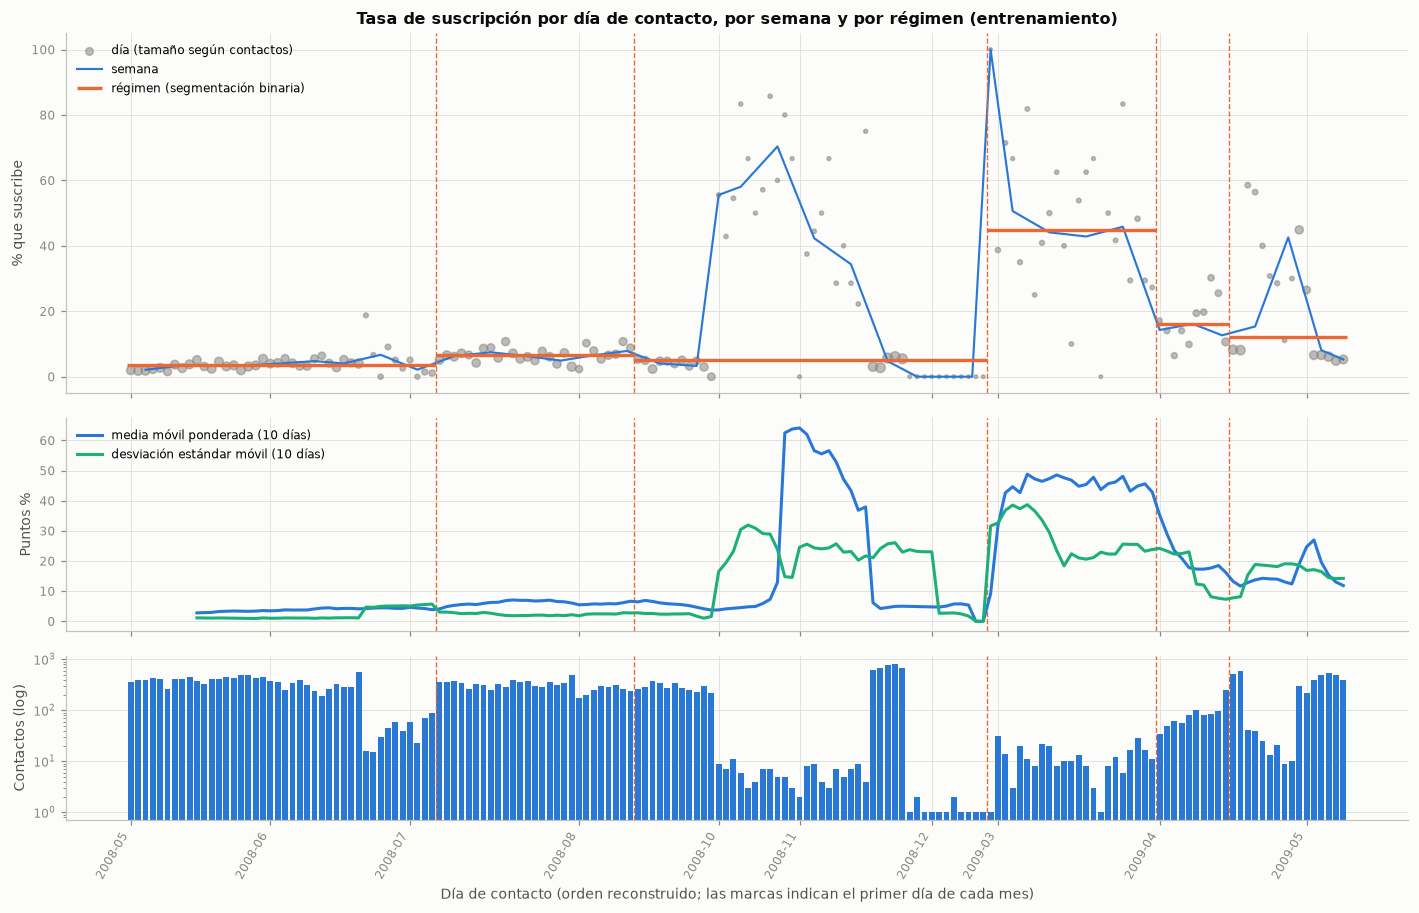

**Interpretación.** En entrenamiento hay 166 días de contacto, pero solo 25 de las 38 semanas están completas, faltan 2008-09, 2009-01 y 2009-02 y 41 días tienen menos de 10 contactos. La segmentación binaria encuentra 5 cambios de régimen: la tasa es del 3,5 % de 2008-05 a 2008-07, sube a un máximo del 44,9 % de 2008-12 a 2009-03, con apenas 12 contactos por día frente a 295 en el primer régimen, y termina en el 12,0 % de 2009-04 a 2009-05. La media móvil de 10 días va del 0,0 % al 64,2 % y la desviación móvil crece en los tramos de poco volumen.

En otras palabras, la serie no tiene un nivel estable: la tasa base cambia por tramos. Después del hueco de septiembre de 2008, en plena crisis financiera, aparecen tramos con pocos contactos y tasas altas, muy distintos de las campañas masivas del primer régimen (de 2008-05 a 2008-07). Un modelo ajustado con el primer régimen enfrenta otra prevalencia en los siguientes (desplazamiento de la clase), y la variabilidad diaria tampoco es constante, porque depende del volumen de llamadas.

Por tal motivo, se opta por mantener la partición y la validación cronológicas; no suponer una tasa base fija, sino actualizar el intercepto con los meses ya cerrados (sección 4.7.1); y no usar `month` ni las macro como si describieran efectos que se repiten de un año a otro.

In [32]:
ORDEN_DOW = ["mon", "tue", "wed", "thu", "fri"]
diario = (tr.assign(dia=dia_tr.to_numpy(), periodo=periodo_tr.to_numpy())
          .groupby("dia", sort=True)
          .agg(contactos=("y", "size"), suscripciones=("y", "sum"), periodo=("periodo", "first"),
               dia_semana=("day_of_week", "first"), **{c: (c, "mean") for c in MACRO}))
diario["tasa"] = diario["suscripciones"] / diario["contactos"]
pos_dow = diario["dia_semana"].map({d: i for i, d in enumerate(ORDEN_DOW)}).to_numpy()
diario["semana"] = np.r_[0, np.cumsum(pos_dow[1:] <= pos_dow[:-1])]   # nueva semana si el día no avanza
dias_por_semana = diario.groupby("semana").size()
rango_meses = pd.period_range(periodo_tr.iloc[0], periodo_tr.iloc[-1], freq="M").strftime("%Y-%m")
meses_sin = [m for m in rango_meses if m not in set(periodo_tr)]
pocos = diario["contactos"] < 10


def segmentacion_binaria(a, w, penal, minimo=5):
    """Puntos de cambio en la media ponderada de `a` (costo: suma de cuadrados ponderada)."""
    def sse(i, j):
        return np.sum(w[i:j] * (a[i:j] - np.average(a[i:j], weights=w[i:j])) ** 2)

    def dividir(i, j):
        if j - i < 2 * minimo:
            return []
        base = sse(i, j)
        ganancia, t = max((base - sse(i, t) - sse(t, j), t) for t in range(i + minimo, j - minimo + 1))
        return dividir(i, t) + [t] + dividir(t, j) if ganancia > penal else []
    return dividir(0, len(a))


# arcoseno de la raíz: varianza ≈ 1/(4n) sin importar la tasa; sobredispersión estimada con días consecutivos
a_dia = np.arcsin(np.sqrt(diario["tasa"].to_numpy()))
w_dia = 4 * diario["contactos"].to_numpy().astype(float)
z_dif = np.diff(a_dia) / np.sqrt(1 / w_dia[1:] + 1 / w_dia[:-1])
phi = np.median(z_dif ** 2) / stats.chi2.ppf(0.5, 1)
cambios = segmentacion_binaria(a_dia, w_dia, penal=2 * phi * np.log(len(a_dia)), minimo=10)
limites = [0] + cambios + [len(diario)]
segmentos = pd.DataFrame([{
    "Desde": diario["periodo"].iloc[i], "Hasta": diario["periodo"].iloc[j - 1], "Días de contacto": j - i,
    "Contactos": int(diario["contactos"].iloc[i:j].sum()),
    "% que suscribe": 100 * diario["suscripciones"].iloc[i:j].sum() / diario["contactos"].iloc[i:j].sum()}
    for i, j in zip(limites[:-1], limites[1:])], index=pd.RangeIndex(1, len(limites), name="Régimen"))

validacion_t = pd.DataFrame([
    ("Formato y zona horaria", "El archivo no trae fecha ni hora; el año y el día de contacto se reconstruyen con el "
     "orden de los registros, `month` y `day_of_week` (sección 1.5)", "Orden consistente; sin hora ni zona horaria"),
    ("Frecuencia", f"{len(diario)} días de contacto, solo de lunes a viernes; {int((dias_por_semana == 5).sum())} de "
     f"{len(dias_por_semana)} semanas tienen los cinco días", "Irregular: días hábiles con huecos"),
    ("Marcas de tiempo repetidas", f"Varios contactos por día (mediana {num(diario['contactos'].median())}, máximo "
     f"{num(diario['contactos'].max())}); son llamadas distintas, no registros duplicados",
     "Esperado: la unidad temporal es el día"),
    ("Huecos", f"Meses sin contactos dentro del rango: {enumerar(meses_sin, codigo=False)}; "
     f"{int(pocos.sum())} días con menos de 10 contactos", "Cobertura desigual en el tiempo"),
    ("Cobertura", f"{periodo_tr.iloc[0]} a {periodo_tr.iloc[-1]} ({periodo_tr.nunique()} meses con contactos); "
     f"el {pct((anio_tr == 2008).mean())} de los registros es de 2008",
     "Menos de dos ciclos anuales: no se puede estimar la estacionalidad anual"),
    ("Panel", "No hay identificador de cliente", "No aplica el análisis por entidad"),
], columns=["Aspecto", "Evidencia (entrenamiento)", "Conclusión"])
tabla(validacion_t, indice=False)
tabla(segmentos, dec=1)

x_dia = np.arange(len(diario))
semanal = diario.groupby("semana").agg(x=("contactos", lambda s: x_dia[s.index - diario.index[0]].mean()),
                                       k=("suscripciones", "sum"), n=("contactos", "sum"))
movil_media = (diario["suscripciones"].rolling(10).sum() / diario["contactos"].rolling(10).sum()).to_numpy()
movil_desv = diario["tasa"].rolling(10).std().to_numpy()
inicio_mes = np.flatnonzero(np.r_[True, diario["periodo"].to_numpy()[1:] != diario["periodo"].to_numpy()[:-1]])

fig, axs = plt.subplots(3, 1, figsize=(13, 8.4), sharex=True, gridspec_kw={"height_ratios": [2.2, 1.3, 1]})
axs[0].scatter(x_dia, 100 * diario["tasa"], s=4 + 40 * np.sqrt(diario["contactos"] / diario["contactos"].max()),
               color=GRIS, alpha=0.55, label="día (tamaño según contactos)")
axs[0].plot(semanal["x"], 100 * semanal["k"] / semanal["n"], color=AZUL, lw=1.4, label="semana")
for r_, (i_, j_) in enumerate(zip(limites[:-1], limites[1:]), start=1):
    axs[0].hlines(segmentos.loc[r_, "% que suscribe"], i_ - 0.5, j_ - 0.5, color=NARANJA, lw=2.2,
                  label="régimen (segmentación binaria)" if r_ == 1 else None)
for t_ in cambios:
    for ax_ in axs:
        ax_.axvline(t_ - 0.5, color=NARANJA, ls="--", lw=0.9)
axs[0].set_ylabel("% que suscribe")
axs[0].set_title("Tasa de suscripción por día de contacto, por semana y por régimen (entrenamiento)")
axs[0].legend(loc="upper left")
axs[1].plot(x_dia, 100 * movil_media, color=AZUL, label="media móvil ponderada (10 días)")
axs[1].plot(x_dia, 100 * movil_desv, color=AGUAMARINA, label="desviación estándar móvil (10 días)")
axs[1].set_ylabel("Puntos %")
axs[1].legend(loc="upper left")
axs[2].bar(x_dia, diario["contactos"], color=AZUL, width=0.8)
axs[2].set_yscale("log")
axs[2].set_ylabel("Contactos (log)")
axs[2].set_xticks(inicio_mes, diario["periodo"].iloc[inicio_mes], rotation=60, ha="right")
axs[2].set_xlabel("Día de contacto (orden reconstruido; las marcas indican el primer día de cada mes)")
plt.tight_layout()
plt.show()

def tramo(r):
    d, h = segmentos.loc[r, "Desde"], segmentos.loc[r, "Hasta"]
    return f"en {d}" if d == h else f"de {d} a {h}"


reg_alto = segmentos["% que suscribe"].idxmax()
dias_por_contacto = segmentos["Contactos"] / segmentos["Días de contacto"]
interpretar(
    f"En entrenamiento hay {len(diario)} días de contacto, pero solo {int((dias_por_semana == 5).sum())} de las "
    f"{len(dias_por_semana)} semanas están completas, faltan {enumerar(meses_sin, codigo=False)} y "
    f"{int(pocos.sum())} días tienen menos de 10 contactos. La segmentación binaria encuentra {len(cambios)} cambios "
    f"de régimen: la tasa es del {num(segmentos['% que suscribe'].iloc[0], 1)} % {tramo(1)}, sube a un máximo del "
    f"{num(segmentos.loc[reg_alto, '% que suscribe'], 1)} % {tramo(reg_alto)}, con apenas "
    f"{num(dias_por_contacto.loc[reg_alto], 0)} contactos por día frente a {num(dias_por_contacto.iloc[0], 0)} en el "
    f"primer régimen, y termina en el {num(segmentos['% que suscribe'].iloc[-1], 1)} % {tramo(len(segmentos))}. "
    f"La media móvil de 10 días va del {num(np.nanmin(100 * movil_media), 1)} % al "
    f"{num(np.nanmax(100 * movil_media), 1)} % y la desviación móvil crece en los tramos de poco volumen.",
    conectar('En otras palabras,', "La serie no tiene un nivel estable: la tasa base cambia por tramos. Después del hueco de septiembre de 2008, "
    "en plena crisis financiera, aparecen tramos con pocos contactos y tasas altas, muy distintos de las campañas "
    f"masivas del primer régimen ({tramo(1)}). Un modelo ajustado con el primer régimen enfrenta otra prevalencia en los "
    "siguientes (desplazamiento de la clase), y la variabilidad diaria tampoco es constante, porque depende del "
    "volumen de llamadas."),
    conectar('Por tal motivo, se opta por', "Mantener la partición y la validación cronológicas; no suponer una tasa base fija, sino actualizar el "
    "intercepto con los meses ya cerrados (sección 4.7.1); y no usar `month` ni las macro como si describieran "
    "efectos que se repiten de un año a otro."))


### 3.6.4 Descomposición, estacionariedad y dependencia temporal

- **Descomposición STL** (Cleveland et al., 1990) de la tasa diaria con un ciclo de cinco días hábiles, el único que la cobertura permite estimar. La fuerza de la tendencia y del ciclo se mide como en Hyndman y Athanasopoulos (2021): 0 si el componente no aporta frente al residuo y 1 si domina. STL no admite ponderaciones, así que los días con pocos contactos aportan ruido. Al lado, la tasa por día de la semana y por mes (estacionalidad por ciclo), con una caja por día de contacto.
- **Estacionariedad:** pruebas ADF (Dickey y Fuller, 1979; H0: raíz unitaria) y KPSS (Kwiatkowski et al., 1992; H0: estacionariedad) en nivel, en nivel con tendencia y en primera diferencia. Se leen juntas porque sus hipótesis nulas son opuestas; las medias y varianzas móviles están en la figura de la sección 3.6.3.
- **Dependencia temporal:** ACF y PACF de la tasa diaria y ACF del residuo STL.
- **Correlación cruzada** entre la tasa del día y cada indicador macroeconómico de 0 a 5 días antes, en niveles y en primeras diferencias, con corrección de Holm.

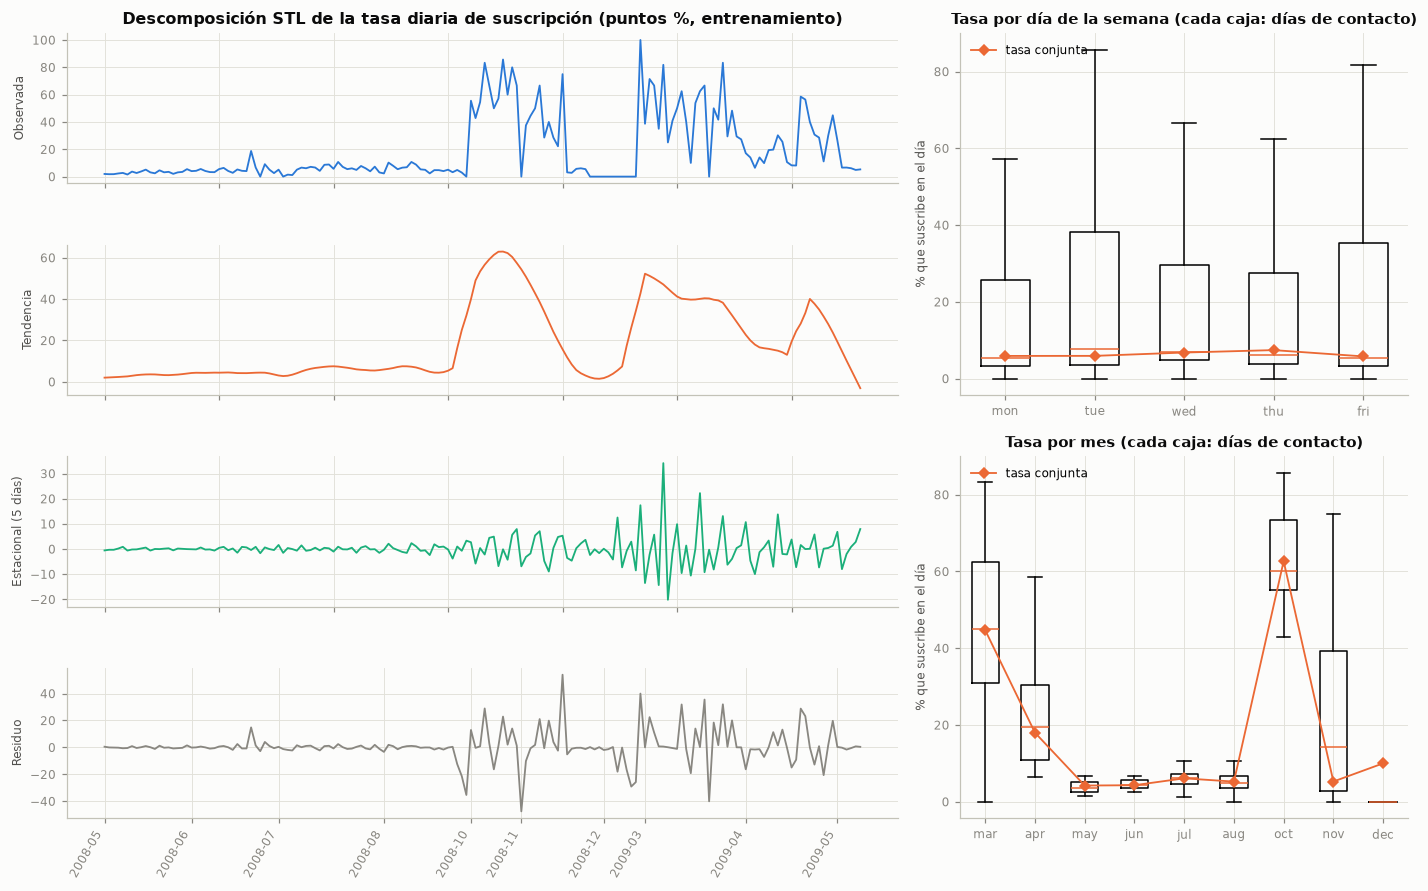

,ADF: p (H0: raíz unitaria),KPSS: p (H0: estacionaria),Conclusión
Serie,,,
"Nivel, con constante","0,141","0,013",No estacionaria
"Nivel, con constante y tendencia","0,005","0,100",Estacionaria
Primera diferencia,"0,000","0,100",Estacionaria


KPSS reporta p acotado a [0,01; 0,10]: 0,010 significa p ≤ 0,01 y 0,100 significa p ≥ 0,10.


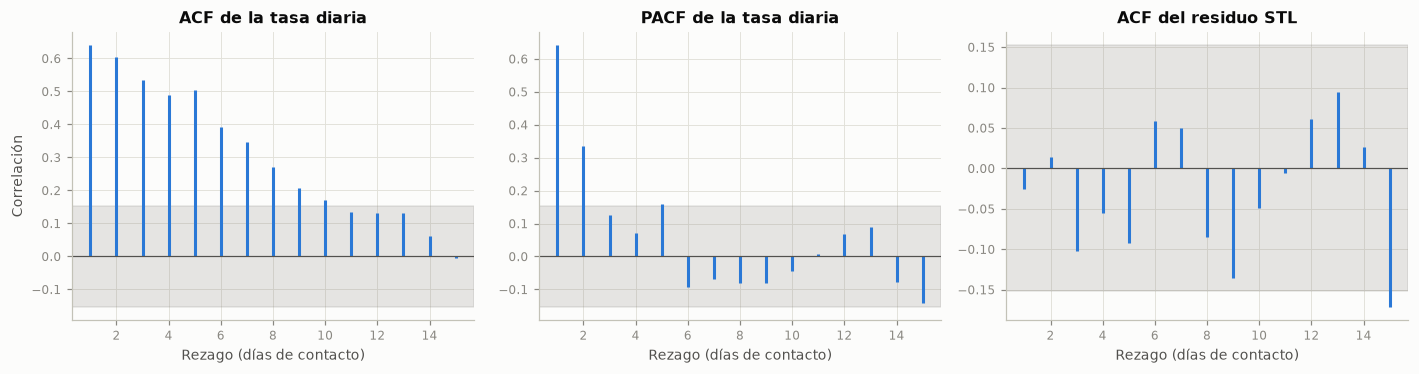

,Correlación en niveles (rezago 0),Correlación más fuerte en diferencias,Rezago (días),"p (Holm, 30 pruebas)"
Indicador,,,,
emp.var.rate,"-0,513","0,204",5,"0,283"
cons.price.idx,"-0,346","0,169",0,"0,818"
cons.conf.idx,"-0,397","0,132",5,"1,000"
euribor3m,"-0,347","0,177",0,"0,636"
nr.employed,"-0,414","0,205",5,"0,283"


**Interpretación.** La fuerza de la tendencia en la descomposición STL es de 0,72 y la del ciclo semanal, de 0,22 (0 = ausente, 1 = domina sobre el residuo). La tasa conjunta por día de la semana va del 5,8 % (fri) al 7,4 % (thu); por mes, del 4,2 % (may) al 62,7 % (oct), aunque 8 de los 9 meses aparecen en un solo año del entrenamiento. Las pruebas dan: en nivel con constante, «no estacionaria»; con tendencia, «estacionaria»; en primera diferencia, «estacionaria». La ACF empieza en 0,64 y cae dentro de la banda del 95 % (0,15) en el rezago 11; la PACF es significativa en los rezagos 1, 2 y 5, mientras que el residuo STL solo sale de la banda en 1 de 15 rezagos. Las macro se correlacionan con la tasa en niveles (de -0,51 a -0,35); en diferencias la correlación más fuerte no pasa de 0,20 y, tras la corrección de Holm, ninguna es significativa.

En ese sentido, la tasa diaria no sigue un ciclo semanal que se repita, y las diferencias por mes no son estacionalidad: como casi cada mes corresponde a un solo año, el mes identifica el régimen. Lo que domina es un nivel que cambia por tramos. Por eso la serie no es estacionaria en nivel y sí lo es al quitarle la tendencia o diferenciarla, y la ACF decae despacio: los días consecutivos se parecen porque pertenecen al mismo régimen, y una vez descontada la tendencia apenas queda dependencia de un día a otro. Que las macro acompañen el nivel pero no los cambios diarios indica que marcan el régimen en que ocurre la llamada, no que lo anticipen (la correlación en niveles entre series no estacionarias puede ser espuria; Granger y Newbold, 1974): un modelo que las usa aprende la tasa base de los regímenes vistos y la extrapola a los nuevos, lo que se refleja en la inestabilidad de sus coeficientes (sección 4.9.1).

En consecuencia, se decide mantener la validación temporal con separación entre bloques (la dependencia entre días consecutivos haría optimista una validación aleatoria); no modelar la tasa como un proceso ARIMA, porque el objetivo es la respuesta de cada cliente y el resultado de los días previos de la campaña no está disponible al llamar; y corregir el nivel de la tasa base con los meses ya cerrados (sección 4.7.1).

In [33]:
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

serie = 100 * diario["tasa"].to_numpy()
stl = STL(serie, period=5, robust=True).fit()   # ciclo de cinco días hábiles
fuerza_tend = max(0.0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
fuerza_est = max(0.0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
tasa_dow = diario.groupby("dia_semana")[["suscripciones", "contactos"]].sum().reindex(ORDEN_DOW)
tasa_dow = 100 * tasa_dow["suscripciones"] / tasa_dow["contactos"]
mes_dia = np.array([ORDEN_MESES[int(p[5:7]) - 1] for p in diario["periodo"]])
meses_dia = [m for m in ORDEN_MESES if m in set(mes_dia)]
tasa_mes = diario.groupby(mes_dia)[["suscripciones", "contactos"]].sum().reindex(meses_dia)
tasa_mes = 100 * tasa_mes["suscripciones"] / tasa_mes["contactos"]
anios_por_mes = pd.Series([p[:4] for p in diario["periodo"]]).groupby(mes_dia).nunique().reindex(meses_dia)

fig = plt.figure(figsize=(13, 8.2))
rejilla = fig.add_gridspec(4, 2, width_ratios=[2.6, 1.4])
for k_, (valores_, nombre_, color_) in enumerate([(serie, "Observada", AZUL), (stl.trend, "Tendencia", NARANJA),
                                                 (stl.seasonal, "Estacional (5 días)", AGUAMARINA),
                                                 (stl.resid, "Residuo", GRIS)]):
    ax_ = fig.add_subplot(rejilla[k_, 0])
    ax_.plot(x_dia, valores_, color=color_, lw=1.2)
    ax_.set_ylabel(nombre_, fontsize=8)
    if k_ == 0:
        ax_.set_title("Descomposición STL de la tasa diaria de suscripción (puntos %, entrenamiento)")
    if k_ < 3:
        ax_.tick_params(labelbottom=False)
    else:
        ax_.set_xticks(inicio_mes, diario["periodo"].iloc[inicio_mes], rotation=60, ha="right")
for ax_, grupos_, etiquetas_, conjunta_, titulo_ in [
        (fig.add_subplot(rejilla[:2, 1]), [serie[diario["dia_semana"].to_numpy() == d] for d in ORDEN_DOW], ORDEN_DOW,
         tasa_dow, "Tasa por día de la semana"),
        (fig.add_subplot(rejilla[2:, 1]), [serie[mes_dia == m] for m in meses_dia], meses_dia, tasa_mes,
         "Tasa por mes")]:
    ax_.boxplot(grupos_, tick_labels=etiquetas_, showfliers=False, widths=0.55)
    ax_.plot(range(1, len(etiquetas_) + 1), conjunta_.to_numpy(), color=NARANJA, marker="D", ms=5, lw=1.2,
             label="tasa conjunta")
    ax_.set_ylabel("% que suscribe en el día", fontsize=8)
    ax_.set_title(titulo_ + " (cada caja: días de contacto)", fontsize=9.5)
    ax_.legend(loc="upper left")
plt.tight_layout()
plt.show()

filas_est = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    warnings.simplefilter("ignore", InterpolationWarning)
    for nombre_, s_, reg_ in [("Nivel, con constante", serie, "c"), ("Nivel, con constante y tendencia", serie, "ct"),
                              ("Primera diferencia", np.diff(serie), "c")]:
        p_adf = adfuller(s_, autolag="AIC", regression=reg_)[1]
        p_kpss = kpss(s_, regression=reg_, nlags="auto")[1]
        if p_adf < 0.05 <= p_kpss:
            concl = "Estacionaria"
        elif p_kpss < 0.05 <= p_adf:
            concl = "No estacionaria"
        elif p_adf < 0.05 and p_kpss < 0.05:
            concl = "Contradictoria (posible cambio estructural)"
        else:
            concl = "No concluyente"
        filas_est.append({"Serie": nombre_, "ADF: p (H0: raíz unitaria)": p_adf,
                          "KPSS: p (H0: estacionaria)": p_kpss, "Conclusión": concl})
estacionariedad = pd.DataFrame(filas_est).set_index("Serie")
tabla(estacionariedad, dec=3)
print("KPSS reporta p acotado a [0,01; 0,10]: 0,010 significa p ≤ 0,01 y 0,100 significa p ≥ 0,10.")

rezagos = 15
banda_d = 1.96 / np.sqrt(len(serie))
acf_d, pacf_d = acf(serie, nlags=rezagos), pacf(serie, nlags=rezagos, method="ols")
acf_res_stl = acf(stl.resid, nlags=rezagos)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax_, valores_, titulo_ in [(axs[0], acf_d, "ACF de la tasa diaria"), (axs[1], pacf_d, "PACF de la tasa diaria"),
                               (axs[2], acf_res_stl, "ACF del residuo STL")]:
    ax_.vlines(range(1, rezagos + 1), 0, valores_[1:], color=AZUL, lw=2)
    ax_.axhspan(-banda_d, banda_d, color=GRIS, alpha=0.2)
    ax_.axhline(0, color=TINTA_2, lw=0.8)
    ax_.set_xlabel("Rezago (días de contacto)")
    ax_.set_title(titulo_)
axs[0].set_ylabel("Correlación")
plt.tight_layout()
plt.show()

# Correlación cruzada tasa(t) con indicador(t - k): en niveles puede ser espuria entre series no estacionarias,
# por eso se contrasta con las primeras diferencias y se corrige por comparaciones múltiples (Holm)
d_serie = np.diff(serie)
filas_cc = []
for c_ in MACRO:
    x_ = diario[c_].to_numpy()
    d_x = np.diff(x_)
    for k_ in range(6):
        r_cc = np.corrcoef(d_serie[k_:], d_x[:len(d_x) - k_])[0, 1]
        n_par = len(d_serie) - k_
        p_cc = 2 * stats.t.sf(abs(r_cc) * np.sqrt((n_par - 2) / (1 - r_cc ** 2)), n_par - 2)
        filas_cc.append({"Indicador": c_, "Rezago": k_, "r": r_cc, "p": p_cc,
                         "nivel": np.corrcoef(serie, x_)[0, 1]})
cc_tabla = pd.DataFrame(filas_cc)
cc_tabla["p (Holm)"] = multipletests(cc_tabla["p"], method="holm")[1]
mas_fuerte = (cc_tabla.loc[cc_tabla.groupby("Indicador")["r"].apply(lambda s: s.abs().idxmax())]
              .set_index("Indicador"))
correlacion_cruzada = pd.DataFrame({
    "Correlación en niveles (rezago 0)": mas_fuerte["nivel"],
    "Correlación más fuerte en diferencias": mas_fuerte["r"],
    "Rezago (días)": mas_fuerte["Rezago"].astype(int),
    "p (Holm, 30 pruebas)": mas_fuerte["p (Holm)"]}).reindex(MACRO)
tabla(correlacion_cruzada, dec=3)

r_lento = int(np.argmax(np.abs(acf_d[1:]) < banda_d)) + 1 if (np.abs(acf_d[1:]) < banda_d).any() else rezagos
pacf_sig = [k for k in range(1, rezagos + 1) if abs(pacf_d[k]) > banda_d]
res_sig = [k for k in range(1, rezagos + 1) if abs(acf_res_stl[k]) > banda_d]
cc_sig = correlacion_cruzada.index[correlacion_cruzada["p (Holm, 30 pruebas)"] < 0.05]
conc = estacionariedad["Conclusión"]
interpretar(
    f"La fuerza de la tendencia en la descomposición STL es de {num(fuerza_tend, 2)} y la del ciclo semanal, de "
    f"{num(fuerza_est, 2)} (0 = ausente, 1 = domina sobre el residuo). La tasa conjunta por día de la semana va del "
    f"{num(tasa_dow.min(), 1)} % ({tasa_dow.idxmin()}) al {num(tasa_dow.max(), 1)} % ({tasa_dow.idxmax()}); por mes, del "
    f"{num(tasa_mes.min(), 1)} % ({tasa_mes.idxmin()}) al {num(tasa_mes.max(), 1)} % ({tasa_mes.idxmax()}), aunque "
    f"{int((anios_por_mes == 1).sum())} de los {len(meses_dia)} meses aparecen en un solo año del entrenamiento. Las pruebas "
    f"dan: en nivel con constante, «{conc.iloc[0].lower()}»; con tendencia, «{conc.iloc[1].lower()}»; en primera "
    f"diferencia, «{conc.iloc[2].lower()}». La ACF empieza en {num(acf_d[1], 2)} y "
    + (f"cae dentro de la banda del 95 % ({num(banda_d, 2)}) en el rezago {r_lento}; " if r_lento < rezagos else
       f"sigue fuera de la banda del 95 % ({num(banda_d, 2)}) en los {rezagos} rezagos; ")
    + f"la PACF es significativa en los rezagos {enumerar([str(k) for k in pacf_sig], codigo=False) or 'ninguno'}, "
    f"mientras que el residuo STL solo sale de la banda en {len(res_sig)} de {rezagos} rezagos. Las macro se "
    f"correlacionan con la tasa en niveles (de {num(correlacion_cruzada.iloc[:, 0].min(), 2)} a "
    f"{num(correlacion_cruzada.iloc[:, 0].max(), 2)}); en diferencias la correlación más fuerte no pasa de "
    f"{num(correlacion_cruzada.iloc[:, 1].abs().max(), 2)} y, tras la corrección de Holm, "
    + ("ninguna es significativa." if len(cc_sig) == 0 else
       f"solo {enumerar(list(cc_sig))} lo {'son' if len(cc_sig) > 1 else 'es'}."),
    conectar('En ese sentido,', "La tasa diaria no sigue un ciclo semanal que se repita, y las diferencias por mes no son estacionalidad: como "
    "casi cada mes corresponde a un solo año, el mes identifica el régimen. Lo que domina es un nivel que cambia por "
    "tramos. Por "
    "eso la serie no es estacionaria en nivel y sí lo es al quitarle la tendencia o diferenciarla, y la ACF decae "
    "despacio: los días consecutivos se parecen porque pertenecen al mismo régimen, y una vez descontada la "
    "tendencia apenas queda dependencia de un día a otro. Que las macro acompañen el nivel pero no los cambios "
    "diarios indica que marcan el régimen en que ocurre la llamada, no que lo anticipen (la correlación en niveles "
    "entre series no estacionarias puede ser espuria; Granger y Newbold, 1974): un modelo que las usa aprende la "
    "tasa base de los regímenes vistos y la extrapola a los nuevos, lo que se refleja en la inestabilidad de sus "
    "coeficientes (sección 4.9.1)."),
    conectar('En consecuencia, se decide', "Mantener la validación temporal con separación entre bloques (la dependencia entre días consecutivos haría "
    "optimista una validación aleatoria); no modelar la tasa como un proceso ARIMA, porque el objetivo es la "
    "respuesta de cada cliente y el resultado de los días previos de la campaña no está disponible al llamar; y "
    "corregir el nivel de la tasa base con los meses ya cerrados (sección 4.7.1)."))


### 3.6.5 Deriva de concepto

La sección 3.6.1 mide el cambio en la distribución de las predictoras (*covariate shift*). Aquí se mide si cambia su **relación con la variable objetivo** (*concept drift*): para cada predictora se compara una regresión logística con la variable y el año contra otra que añade su interacción. El año absorbe el cambio de prevalencia, así que una interacción significativa indica que el efecto de la variable no es el mismo en ambos años (prueba de razón de verosimilitudes, con corrección de Holm). Se excluyen las macro y `month`, porque dentro de un año solo distinguen meses. Como tamaño de efecto se reporta el AUC univariado (numéricas) o la V de Cramér (categóricas) de cada año.

In [34]:
import statsmodels.formula.api as smf

a0, a1 = sorted(anio_tr.unique())[0], sorted(anio_tr.unique())[-1]
es_a1 = (anio_tr == a1).astype(int).to_numpy()
# Variables cuya relación con y puede compararse entre años; las macro y month se excluyen porque dentro de cada
# año solo distinguen meses (sus cambios entre años son deriva de covariables, sección 3.6.1)
REPRESENTACION = {"age": ("num", tr["age"]), "campaign": ("num", np.log1p(tr["campaign"])),
                  "previous": ("num", np.log1p(tr["previous"])),
                  "pdays": ("cat", np.where(tr["pdays"] == 999, "sin registro (999)", "con registro"))}
REPRESENTACION.update({c: ("cat", tr[c]) for c in CATEGORICAS if c != "month"})


def prueba_interaccion(tipo, x):
    """Razón de verosimilitudes de y ~ x * año frente a y ~ x + año (año absorbe el cambio de prevalencia)."""
    d = pd.DataFrame({"y": y_tr.to_numpy(), "x": np.asarray(x), "a": es_a1})
    if tipo == "cat":
        conteo = pd.crosstab(d["x"], d["a"])
        d = d[d["x"].isin(conteo.index[(conteo >= 30).all(axis=1)])]
        termino = "C(x)"
    else:
        d["x"] = (d["x"] - d["x"].mean()) / d["x"].std()
        termino = "x"
    m0 = smf.logit(f"y ~ {termino} + a", d).fit(disp=0)
    m1 = smf.logit(f"y ~ {termino} * a", d).fit(disp=0)
    lr, gl = 2 * (m1.llf - m0.llf), int(m1.df_model - m0.df_model)
    return lr, gl, stats.chi2.sf(lr, gl)


filas_cd = []
for c_, (tipo_, x_cd) in REPRESENTACION.items():
    x_cd = pd.Series(np.asarray(x_cd), index=tr.index)
    efecto_cd = {}
    for a_ in (a0, a1):
        m_cd = (anio_tr == a_).to_numpy()
        efecto_cd[a_] = (roc_auc_score(y_tr[m_cd], x_cd[m_cd]) if tipo_ == "num" else
                         v_cramer(pd.crosstab(x_cd[m_cd], y_tr[m_cd]))[0])
    lr_cd, gl_cd, p_cd = prueba_interaccion(tipo_, x_cd)
    filas_cd.append({"Variable": c_, "Medida": "AUC univariado" if tipo_ == "num" else "V de Cramér",
                     str(a0): efecto_cd[a0], str(a1): efecto_cd[a1], "χ² (interacción con el año)": lr_cd,
                     "gl": gl_cd, "p": p_cd})
deriva_concepto = pd.DataFrame(filas_cd).set_index("Variable")
deriva_concepto["p (Holm)"] = multipletests(deriva_concepto["p"], method="holm")[1]
deriva_concepto = deriva_concepto.drop(columns="p").sort_values("χ² (interacción con el año)", ascending=False)
tabla(deriva_concepto, dec=3)

vars_deriva_concepto = deriva_concepto.index[deriva_concepto["p (Holm)"] < 0.05].tolist()
vars_concepto_estable = deriva_concepto.index[deriva_concepto["p (Holm)"] >= 0.05].tolist()
top_cd = deriva_concepto.index[0]
interpretar(
    f"La tasa de suscripción pasa del {pct(y_tr[es_a1 == 0].mean())} en {a0} al {pct(y_tr[es_a1 == 1].mean())} en el "
    f"tramo de {a1} incluido en entrenamiento. Con ese cambio de prevalencia descontado, la relación con `y` difiere "
    f"entre años (interacción significativa tras Holm) en {len(vars_deriva_concepto)} de las {len(deriva_concepto)} "
    "variables" + (f": {enumerar(vars_deriva_concepto)}" if vars_deriva_concepto else "")
    + f". La mayor diferencia es la de `{top_cd}` ({deriva_concepto.loc[top_cd, 'Medida']} de "
    f"{num(deriva_concepto.loc[top_cd, str(a0)], 3)} en {a0} frente a {num(deriva_concepto.loc[top_cd, str(a1)], 3)} "
    f"en {a1}). "
    + (f"Se mantienen estables {enumerar(vars_concepto_estable)}." if vars_concepto_estable else
       "Ninguna se mantiene estable."),
    conectar('Esto significa que,', "Además del cambio de covariables (sección 3.6.1) y de la prevalencia, hay **deriva de concepto**: para "
    + ("estas variables" if vars_deriva_concepto else "ninguna variable")
    + " la asociación con la suscripción aprendida en " + str(a0) + " no es la que rige en " + str(a1) + ". Los "
    "coeficientes estimados con un periodo dominado por " + str(a0) + " describen ese periodo y se trasladan con "
    "error a los siguientes; cuanto menos regularizado esté el modelo, más se ajusta a esas relaciones que luego "
    "cambian."),
    conectar('Por lo anterior, conviene', "Interpretar los coeficientes como asociaciones del periodo de ajuste (sección 4.9), elegir una "
    "regularización que no sobreajuste las relaciones inestables (sección 4.9.1) y vigilar la deriva con la "
    "validación temporal y el desempeño por año (sección 4.10)."))


,Medida,2008,2009,χ² (interacción con el año),gl,p (Holm)
Variable,,,,,,
job,V de Cramér,"0,022","0,193","103,045",10,"0,000"
education,V de Cramér,"0,021","0,133","54,873",6,"0,000"
default,V de Cramér,"0,016","0,120","53,827",1,"0,000"
day_of_week,V de Cramér,"0,018","0,109","45,517",4,"0,000"
marital,V de Cramér,"0,017","0,087","12,373",2,"0,016"
age,AUC univariado,"0,475","0,476","10,842",1,"0,009"
poutcome,V de Cramér,"0,012","0,180","7,132",2,"0,198"
housing,V de Cramér,"0,012","0,027","6,296",2,"0,258"
loan,V de Cramér,"0,012","0,013","3,645",2,"0,646"


**Interpretación.** La tasa de suscripción pasa del 4,8 % en 2008 al 14,5 % en el tramo de 2009 incluido en entrenamiento. Con ese cambio de prevalencia descontado, la relación con `y` difiere entre años (interacción significativa tras Holm) en 6 de las 13 variables: `job`, `education`, `default`, `day_of_week`, `marital` y `age`. La mayor diferencia es la de `job` (V de Cramér de 0,022 en 2008 frente a 0,193 en 2009). Se mantienen estables `poutcome`, `housing`, `loan`, `pdays`, `campaign`, `contact` y `previous`.

Esto significa que, además del cambio de covariables (sección 3.6.1) y de la prevalencia, hay **deriva de concepto**: para estas variables la asociación con la suscripción aprendida en 2008 no es la que rige en 2009. Los coeficientes estimados con un periodo dominado por 2008 describen ese periodo y se trasladan con error a los siguientes; cuanto menos regularizado esté el modelo, más se ajusta a esas relaciones que luego cambian.

Por lo anterior, conviene interpretar los coeficientes como asociaciones del periodo de ajuste (sección 4.9), elegir una regularización que no sobreajuste las relaciones inestables (sección 4.9.1) y vigilar la deriva con la validación temporal y el desempeño por año (sección 4.10).

## 3.7 Preprocesamiento (enunciado, sección 2.9)

Todo el preprocesamiento se implementa dentro de un `Pipeline` de scikit-learn con un `ColumnTransformer`, de modo que cada parámetro (medianas, medias, desviaciones, categorías) se ajusta **solo con los datos de entrenamiento** de cada pliegue y luego se aplica sin cambios a validación y prueba. La tabla traza cada decisión al hallazgo del EDA que la motiva.

In [35]:
VARS_NUM = [c for c in NUMERICAS if c != "duration" and c not in NUM_RETIRADAS_VIF]
VARS_CAT = list(CATEGORICAS)
VARS_LOG = [c for c in ("campaign", "previous") if c in VARS_NUM]
VARS_ESCALA = [c for c in VARS_NUM if c not in VARS_LOG + ["pdays"]]

meses_ausentes_tr = [m for m in ORDEN_MESES if m not in set(X_tr["month"])]
decisiones = pd.DataFrame([
    (f"Partición cronológica 80/20 y validación TimeSeriesSplit con separación de {GAP} registros",
     f"Fuga temporal: AUC aleatorio de {num(auc_alea, 3)} frente a {num(cv_tss['AUC'].mean(), 3)} temporal; el periodo "
     f"solo logra {num(auc_periodo, 3)}", "1.5, 2 y 3.6"),
    ("Excluir duration", "Solo se conoce después de la llamada; sube el AUC de "
     f"{num(auc_sin_dur, 3)} a {num(auc_con_dur, 3)}", "3.5"),
    (f"Excluir {enumerar(NUM_RETIRADAS_VIF, codigo=False)}",
     f"VIF inicial de {enumerar([num(vif_inicial[c], 1) for c in NUM_RETIRADAS_VIF], codigo=False)}", "3.3.5"),
    ("unknown como categoría propia (sin imputar la moda ni eliminar filas)",
     "Faltantes no MCAR e informativos; eliminarlos quitaría el " + pct(alguno.mean()) + " de los registros", "1.6.1 y 1.6.2"),
    ("pdays = 999 → faltante + indicador; imputación por la mediana (de entrenamiento)",
     "999 es un código, no días; inconsistente con previous en " + num(inc_pdays) + " registros", "1.6.4"),
    ("log1p en " + enumerar(VARS_LOG, codigo=False), "Asimetría de " + enumerar([num(uni_num.loc[c, "Asimetría"], 1) for c in VARS_LOG], codigo=False)
     + " y atípicos legítimos de cola larga", "3.2.1 y 3.4.2"),
    ("Sin eliminar atípicos", "Son valores plausibles y concentran clientes con historial", "1.6.5 y 3.4.2"),
    ("Estandarización de todas las numéricas", "Escalas muy distintas (edad, índices, empleo) y penalización L2", "3.2.1"),
    ("One-hot con referencia (drop='first') para las categóricas",
     "Variables nominales; la referencia facilita leer los odds ratios", "3.2.2"),
    (f"Categorías con menos del {pct(MIN_FREQ)} agrupadas como infrecuentes; las no vistas en entrenamiento "
     "van a la categoría infrecuente o a la de referencia",
     f"{len(muy_raras)} categorías raras con coeficientes inestables; meses ausentes en entrenamiento: "
     f"{enumerar(meses_ausentes_tr, codigo=False)}", "3.2.2"),
    ("Sin variables de periodo ni de clúster", "El periodo no se conoce hacia el futuro; los clústeres repiten el periodo",
     "3.4.3 y 3.6"),
    ("Elegir C con la pérdida logarítmica de la validación temporal (sección 4.1)",
     f"Las macro solo marcan el régimen y la relación con y cambia entre años en {len(vars_deriva_concepto)} de "
     f"{len(deriva_concepto)} variables: un modelo poco regularizado extrapola mal a periodos nuevos", "3.6.4 y 3.6.5"),
    ("Recalibrar el intercepto cada mes con los meses ya cerrados (sección 4.7.1)",
     f"La tasa cambia por regímenes ({len(segmentos)} tramos, del {num(segmentos['% que suscribe'].min(), 1)} % al "
     f"{num(segmentos['% que suscribe'].max(), 1)} %) y no es estacionaria en nivel", "3.6.3 y 3.6.4"),
], columns=["Decisión", "Hallazgo del EDA que la motiva", "Sección"])
tabla(decisiones, indice=False)

Decisión,Hallazgo del EDA que la motiva,Sección
Partición cronológica 80/20 y validación TimeSeriesSplit con separación de 507 registros,"Fuga temporal: AUC aleatorio de 0,670 frente a 0,540 temporal; el periodo solo logra 0,660","1.5, 2 y 3.6"
Excluir duration,"Solo se conoce después de la llamada; sube el AUC de 0,540 a 0,856",3.5
Excluir euribor3m y emp.var.rate,"VIF inicial de 46,2 y 45,4",3.3.5
unknown como categoría propia (sin imputar la moda ni eliminar filas),"Faltantes no MCAR e informativos; eliminarlos quitaría el 26,0 % de los registros",1.6.1 y 1.6.2
pdays = 999 → faltante + indicador; imputación por la mediana (de entrenamiento),"999 es un código, no días; inconsistente con previous en 4 110 registros",1.6.4
log1p en campaign y previous,"Asimetría de 4,6 y 3,9 y atípicos legítimos de cola larga",3.2.1 y 3.4.2
Sin eliminar atípicos,Son valores plausibles y concentran clientes con historial,1.6.5 y 3.4.2
Estandarización de todas las numéricas,"Escalas muy distintas (edad, índices, empleo) y penalización L2",3.2.1
One-hot con referencia (drop='first') para las categóricas,Variables nominales; la referencia facilita leer los odds ratios,3.2.2
"Categorías con menos del 0,5 % agrupadas como infrecuentes; las no vistas en entrenamiento van a la categoría infrecuente o a la de referencia","5 categorías raras con coeficientes inestables; meses ausentes en entrenamiento: jan, feb y sep",3.2.2


In [36]:
def pdays_a_nan(X):
    """Convierte el código 999 de pdays en faltante para imputarlo y marcarlo con un indicador."""
    X = np.asarray(X, dtype=float).copy()
    X[X == 999] = np.nan
    return X


def construir_preprocesador(numericas=None, categoricas=None):
    numericas = VARS_NUM if numericas is None else numericas
    categoricas = VARS_CAT if categoricas is None else categoricas
    escala = [c for c in numericas if c not in ("campaign", "previous", "pdays")]
    logs = [c for c in ("campaign", "previous") if c in numericas]
    pasos = [
        ("num", StandardScaler(), escala),
        ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), logs),
        ("cat", OneHotEncoder(drop="first", min_frequency=MIN_FREQ, handle_unknown="infrequent_if_exist",
                              sparse_output=False), categoricas),
    ]
    if "pdays" in numericas:
        pasos.insert(2, ("pdays", make_pipeline(
            FunctionTransformer(pdays_a_nan, feature_names_out="one-to-one"),
            SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True),
            StandardScaler()), ["pdays"]))
    return ColumnTransformer(pasos)


def construir_modelo(C=1.0, numericas=None, categoricas=None):
    return Pipeline([("pre", construir_preprocesador(numericas, categoricas)),
                     ("lr", LogisticRegression(C=C, max_iter=5000))])


# En validación cronológica pueden aparecer meses no vistos; el codificador los envía a la categoría
# infrecuente (o a la referencia) por diseño, así que el aviso correspondiente se silencia.
warnings.filterwarnings("ignore", message="Found unknown categories")

pre_ajustado = construir_preprocesador().fit(X_tr, y_tr)
nombres_salida = pre_ajustado.get_feature_names_out()
codif = pre_ajustado.named_transformers_["cat"]
infrecuentes = {c: list(v) for c, v in zip(VARS_CAT, codif.infrequent_categories_) if v is not None}
print(pre_ajustado)
print(f"\nPredictoras de entrada: {len(VARS_NUM)} numéricas + {len(VARS_CAT)} categóricas = "
      f"{len(VARS_NUM) + len(VARS_CAT)}")
print(f"Columnas tras el preprocesamiento: {len(nombres_salida)}")
print("Categorías agrupadas como infrecuentes (ajustadas en entrenamiento):", infrecuentes)
print(f"Mediana de pdays (sin 999) aprendida en entrenamiento: "
      f"{pre_ajustado.named_transformers_['pdays'].named_steps['simpleimputer'].statistics_[0]:.0f} días")

cv_vif = {}
for nombre, numericas in [("Con todas las macro", [c for c in NUMERICAS if c != "duration"]),
                          ("Sin las retiradas por VIF (modelo base)", VARS_NUM)]:
    r = cross_validate(construir_modelo(numericas=numericas), X_tr, y_tr, cv=tss, scoring=["roc_auc", "average_precision"])
    cv_vif[nombre] = {"AUC media": r["test_roc_auc"].mean(), "AUC desv. est.": r["test_roc_auc"].std(),
                      "AUC-PR media": r["test_average_precision"].mean()}
cv_vif = pd.DataFrame(cv_vif).T
tabla(cv_vif, dec=4)

perdida_vif = cv_vif.iloc[0]["AUC media"] - cv_vif.iloc[1]["AUC media"]
interpretar(
    f"El preprocesamiento convierte {len(VARS_NUM) + len(VARS_CAT)} predictoras en {len(nombres_salida)} columnas "
    f"(n/p efectivo = {num(len(X_tr) / len(nombres_salida), 0)}; {num(y_tr.sum() / len(nombres_salida), 0)} eventos por "
    f"columna). Retirar {enumerar(NUM_RETIRADAS_VIF)} cambia el AUC de validación de "
    f"{num(cv_vif.iloc[0]['AUC media'], 4)} a {num(cv_vif.iloc[1]['AUC media'], 4)} en la validación temporal "
    f"(diferencia de {num(perdida_vif, 4)}; la desviación entre pliegues es de {num(cv_vif.iloc[1]['AUC desv. est.'], 4)}).",
    ("Esto significa que la eliminación por VIF no cuesta desempeño apreciable frente a la variabilidad entre pliegues "
     "y deja coeficientes interpretables. " if abs(perdida_vif) < cv_vif.iloc[1]["AUC desv. est."] else
     "Esto significa que la eliminación por VIF cambia el AUC más que la variabilidad entre pliegues; se mantiene por "
     "interpretabilidad y se declara su costo. ")
    + "El número de eventos por columna es amplio, así que el riesgo de sobreajuste por dimensionalidad es bajo.",
    "Por lo anterior, conviene usar este `Pipeline` como base del modelo de la sección 4, con el hiperparámetro de "
    "regularización elegido por validación cruzada.")

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'cons.price.idx', 'cons.conf.idx',
                                  'nr.employed']),
                                ('log',
                                 Pipeline(steps=[('functiontransformer',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['campaign', 'previous']),
                                ('pdays',
                                 Pipeline(steps=[('functiontransformer',
                                                  Function...
                                                 ('simpleimputer',
                                                  SimpleImputer

,AUC media,AUC desv. est.,AUC-PR media
Con todas las macro,"0,5345","0,0573","0,0855"
Sin las retiradas por VIF (modelo base),"0,5374","0,0753","0,0961"


**Interpretación.** El preprocesamiento convierte 17 predictoras en 49 columnas (n/p efectivo = 672; 43 eventos por columna). Retirar `euribor3m` y `emp.var.rate` cambia el AUC de validación de 0,5345 a 0,5374 en la validación temporal (diferencia de -0,0029; la desviación entre pliegues es de 0,0753).

Esto significa que la eliminación por VIF no cuesta desempeño apreciable frente a la variabilidad entre pliegues y deja coeficientes interpretables. El número de eventos por columna es amplio, así que el riesgo de sobreajuste por dimensionalidad es bajo.

Por lo anterior, conviene usar este `Pipeline` como base del modelo de la sección 4, con el hiperparámetro de regularización elegido por validación cruzada.

### Módulos del tercer entregable

A partir de aquí se cargan el paquete del proyecto (`src/bm`) y las librerías nuevas de este entregable. La celda va después del EDA heredado para que ninguna variable de las secciones 1 a 3 oculte las funciones del paquete.

In [37]:
import json
import pickle
import subprocess
import sys

sys.path.insert(0, str(Path("src").resolve()))

import arch
import deap
import faiss
import imblearn
import lime
import optuna
import scikit_posthocs as sp
import shap
import xgboost
from scipy.special import expit
from sklearn.metrics import (ConfusionMatrixDisplay, mean_absolute_error, precision_recall_curve as curva_pr,
                             r2_score, root_mean_squared_error)

from statsmodels.tsa.stattools import acf

from bm import computacional as comp
from bm import config as cfg
from bm import estadistica as st
from bm import evaluacion as evm
from bm.anidada import cargar_corridas, id_tarea, lista_combinaciones, particion
from bm.datos import cv_externa, cv_interna
from bm.espacios import ESPACIOS, JUSTIFICACION, REJILLAS, n_puntos_rejilla

assert SEED == cfg.SEED
RECALCULAR = False  # True: vuelve a ejecutar la validación anidada (cerca de una hora con 10 núcleos)
if RECALCULAR:
    subprocess.run([sys.executable, "scripts/ejecutar_experimentos.py"], check=True)
    subprocess.run([sys.executable, "scripts/ejecutar_finales.py", "--computacional"], check=True)

RES = cfg.RUTA_RESULTADOS
NM, NB, NO = cfg.NOMBRE_MODELO, cfg.NOMBRE_BALANCEO, cfg.NOMBRE_OPTIMIZADOR
# Paleta categórica validada, en orden fijo (la identidad sigue a la entidad, nunca al rango)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_MODELO = {m: CAT[i] for i, m in enumerate(cfg.MODELOS_CLF)}
COLOR_MODELO_REG = {m: CAT[i] for i, m in enumerate(cfg.MODELOS_REG)}
ORDEN_OPT = ["grid", "random", "bayes", "genetico", "halving"]
COLOR_OPT = {o: CAT[i] for i, o in enumerate(ORDEN_OPT)}
COLOR_BAL = {b: CAT[i] for i, b in enumerate(cfg.BALANCEOS)}

def ms(serie, d=3):
    """Media ± desviación estándar con coma decimal."""
    return f"{num(np.mean(serie), d)} ± {num(np.std(serie, ddof=1), d)}"


def etiqueta(r):
    """Nombre legible de una combinación."""
    partes = [NM[r["modelo"]]]
    if r["tarea"] == "clf":
        partes.append(NB[r["balanceo"]])
    partes.append(NO[r["optimizador"]])
    return " · ".join(partes)


versiones_e3 = pd.DataFrame({
    "Componente": ["imbalanced-learn", "xgboost", "optuna", "deap", "shap", "lime", "arch", "faiss-cpu",
                   "scikit-posthocs"],
    "Versión": [imblearn.__version__, xgboost.__version__, optuna.__version__, deap.__version__, shap.__version__,
                getattr(lime, "__version__", "0.2.0.1"), arch.__version__, faiss.__version__, sp.__version__]})
tabla(versiones_e3, indice=False)

DASH = Path("dashboard") / "datos"
DASH.mkdir(parents=True, exist_ok=True)


def exportar(nombre, obj):
    """Guarda un resultado para el dashboard y el Jupyter Book (mismas cifras que este cuaderno)."""
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    if isinstance(obj, pd.DataFrame):
        df_ = obj.copy()
        df_.columns = [" · ".join(map(str, c)) if isinstance(c, tuple) else str(c) for c in df_.columns]
        for c in df_.columns:
            if df_[c].dtype == object:
                df_[c] = df_[c].map(lambda v: v if v is None or isinstance(v, str) else str(v))
        df_.to_parquet(DASH / f"{nombre}.parquet")
    else:
        (DASH / f"{nombre}.json").write_text(json.dumps(obj, default=float, ensure_ascii=False, indent=1),
                                             encoding="utf-8")


C:\Users\donov\miniconda3\envs\bm_e3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Componente,Versión
imbalanced-learn,0.14.2
xgboost,3.4.1
optuna,5.0.0
deap,1.4
shap,0.54.1
lime,0.2.0.1
arch,8.0.0
faiss-cpu,1.15.1
scikit-posthocs,0.17.1


## 3.8 Nuevos hallazgos para el tercer entregable

El desarrollo de este entregable exige dos análisis que el EDA anterior no cubría: la variable continua de la rama de regresión, que la guía pide aunque *Bank Marketing* sea un problema de clasificación, y el desbalance dentro de los pliegues de la validación anidada, que condiciona la viabilidad de SMOTE y ADASYN. Ambos se calculan solo con el conjunto de entrenamiento.

### 3.8.1 Variable objetivo de la rama de regresión: `log1p(duration)`

La única variable continua del archivo con sentido como objetivo a nivel de cliente es `duration`, la duración de la llamada en segundos. En la clasificación se excluye porque solo se conoce después de la llamada (sección 3.5), pero como **objetivo** es legítima: estimar antes de marcar cuánto durará la llamada sirve para planificar la carga de los asesores. Las predictoras son las mismas de la clasificación (información previa a la llamada) y `y` no se usa, porque también se conoce después.

,duration (s),log1p(duration)
Media,"255,99","5,16"
Mediana,"175,00","5,17"
Desv. est.,"261,26","0,91"
Asimetría,"3,32","-0,30"
Registros con 0 s,"3,00",—
Máximo,"4 918,00","8,50"


Variable,Medida,Valor,p
nr.employed,Spearman |rho|,"0,0858","0,0000"
campaign,Spearman |rho|,"0,0768","0,0000"
cons.conf.idx,Spearman |rho|,"0,0503","0,0000"
pdays,Spearman |rho|,"0,0313","0,0000"
age,Spearman |rho|,"0,0193","0,0005"
month,eta²,"0,0124","0,0000"
previous,Spearman |rho|,"0,0061","0,2684"
cons.price.idx,Spearman |rho|,"0,0044","0,4295"


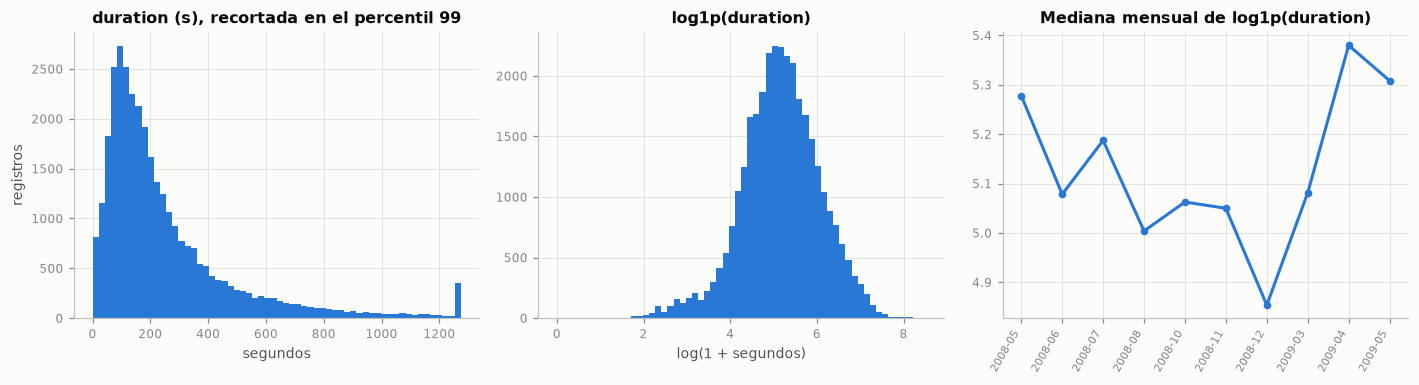

**Interpretación.** La duración tiene media de 256 s y mediana de 175 s, con asimetría de 3,3 y 3 llamadas de 0 s; en escala `log1p` la asimetría baja a -0,30. La asociación más fuerte con una predictora previa a la llamada es la de `nr.employed` (Spearman |rho| = 0,086); ninguna otra supera 0,077. La mediana mensual se mueve entre 4,85 y 5,38 en escala log.

Esto significa que la transformación logarítmica vuelve la distribución casi simétrica y evita que unas pocas llamadas largas dominen el RMSE, pero la señal disponible antes de la llamada es débil: las asociaciones son estadísticamente significativas por el tamaño de muestra, aunque de magnitud pequeña. Es de esperar que los modelos de regresión apenas superen a la media histórica.

Por tal motivo, se opta por modelar `log1p(duration)` y reportar el RMSE y el MAE en escala log y en segundos, comparando siempre contra el pronóstico de la media del entrenamiento. Un resultado nulo en esta rama no es un error del pipeline: es evidencia de que la duración depende de lo que ocurre durante la llamada.

In [38]:
dur = tr["duration"].astype(float)
log_dur = np.log1p(dur)
resumen_dur = pd.DataFrame({
    "duration (s)": [dur.mean(), dur.median(), dur.std(), stats.skew(dur), (dur == 0).sum(), dur.max()],
    "log1p(duration)": [log_dur.mean(), log_dur.median(), log_dur.std(), stats.skew(log_dur), np.nan, log_dur.max()]},
    index=["Media", "Mediana", "Desv. est.", "Asimetría", "Registros con 0 s", "Máximo"])
tabla(resumen_dur, dec=2)

# Asociación con las predictoras previas a la llamada: Spearman (numéricas) y eta² (categóricas)
asoc = []
for c in VARS_NUM:
    rho, p_ = stats.spearmanr(tr[c], log_dur)
    asoc.append({"Variable": c, "Medida": "Spearman |rho|", "Valor": abs(rho), "p": p_})
for c in VARS_CAT:
    g = log_dur.groupby(tr[c])
    eta2 = (g.size() * (g.mean() - log_dur.mean()) ** 2).sum() / ((log_dur - log_dur.mean()) ** 2).sum()
    asoc.append({"Variable": c, "Medida": "eta²", "Valor": eta2, "p": stats.kruskal(*[v for _, v in g]).pvalue})
asoc = pd.DataFrame(asoc).sort_values("Valor", ascending=False)
tabla(asoc.head(8), dec=4, indice=False)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].hist(dur.clip(upper=dur.quantile(0.99)), bins=60, color=AZUL)
axs[0].set(title="duration (s), recortada en el percentil 99", xlabel="segundos", ylabel="registros")
axs[1].hist(log_dur, bins=60, color=AZUL)
axs[1].set(title="log1p(duration)", xlabel="log(1 + segundos)")
med_mes = log_dur.groupby(periodo_tr).median()
axs[2].plot(range(len(med_mes)), med_mes.values, color=AZUL, marker="o", ms=4)
axs[2].set_xticks(range(len(med_mes)), med_mes.index, rotation=60, ha="right", fontsize=7)
axs[2].set(title="Mediana mensual de log1p(duration)")
plt.tight_layout()
plt.show()

asim_log = stats.skew(log_dur)
top = asoc.iloc[0]
interpretar(
    f"La duración tiene media de {num(dur.mean())} s y mediana de {num(dur.median())} s, con asimetría de "
    f"{num(stats.skew(dur), 1)} y {int((dur == 0).sum())} llamadas de 0 s; en escala `log1p` la asimetría baja a "
    f"{num(asim_log, 2)}. La asociación más fuerte con una predictora previa a la llamada es la de `{top['Variable']}` "
    f"({top['Medida']} = {num(top['Valor'], 3)}); ninguna otra supera {num(asoc['Valor'].iloc[1], 3)}. La mediana mensual "
    f"se mueve entre {num(med_mes.min(), 2)} y {num(med_mes.max(), 2)} en escala log.",
    conectar("Esto significa que", "La transformación logarítmica vuelve la distribución casi simétrica y evita que unas "
             "pocas llamadas largas dominen el RMSE, pero la señal disponible antes de la llamada es débil: las "
             "asociaciones son estadísticamente significativas por el tamaño de muestra, aunque de magnitud pequeña. Es "
             "de esperar que los modelos de regresión apenas superen a la media histórica."),
    conectar("Por tal motivo, se opta por", "Modelar `log1p(duration)` y reportar el RMSE y el MAE en escala log y en "
             "segundos, comparando siempre contra el pronóstico de la media del entrenamiento. Un resultado nulo en esta "
             "rama no es un error del pipeline: es evidencia de que la duración depende de lo que ocurre durante la "
             "llamada."))

### 3.8.2 Desbalance dentro de los pliegues de la validación anidada

SMOTE necesita al menos `k + 1 = 6` positivos en cada ajuste para interpolar entre vecinos, y ADASYN además necesita positivos rodeados de negativos. Como la prevalencia de 2008 es muy baja y los pliegues internos de la validación anidada son pequeños, se verifica cuántos positivos tiene el ajuste más pequeño de cada pliegue externo antes de comprometer el diseño.

In [39]:
filas = []
for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr), start=1):
    internos = list(cv_interna(GAP).split(i_e))
    i_min = i_e[internos[0][0]]
    filas.append({"Pliegue externo": k_, "Positivos en el ajuste externo": int(y_tr.iloc[i_e].sum()),
                  "% positivos ajuste externo": 100 * y_tr.iloc[i_e].mean(),
                  "Filas del ajuste interno más pequeño": len(i_min),
                  "Positivos en el ajuste interno más pequeño": int(y_tr.iloc[i_min].sum()),
                  "Razón negativos/positivos (ajuste externo)": (1 - y_tr.iloc[i_e].mean()) / y_tr.iloc[i_e].mean(),
                  "% positivos validación externa": 100 * y_tr.iloc[i_v].mean()})
desb = pd.DataFrame(filas).set_index("Pliegue externo")
tabla(desb, dec=2)

interpretar(
    f"El ajuste interno más pequeño tiene {num(desb['Positivos en el ajuste interno más pequeño'].min())} positivos, "
    + ("por encima de los seis que necesita SMOTE con k = 5. " if desb['Positivos en el ajuste interno más pequeño'].min() >= 6
       else "por debajo de los seis que necesita SMOTE con k = 5. ") +
    f"La razón negativos/positivos del ajuste externo va de "
    f"{num(desb['Razón negativos/positivos (ajuste externo)'].min(), 1)} a "
    f"{num(desb['Razón negativos/positivos (ajuste externo)'].max(), 1)}, mientras que la prevalencia de validación "
    f"externa va del {num(desb['% positivos validación externa'].min(), 1)} % al "
    f"{num(desb['% positivos validación externa'].max(), 1)} %; en prueba es del {pct(y_te.mean())}.",
    conectar("Lo anterior indica que", "El sobremuestreo es viable en todos los pliegues, pero el desbalance que corrige "
             "no es el único problema: la prevalencia cambia entre periodos (*prior shift*), y ninguna técnica de "
             "balanceo, que equilibra las clases dentro del ajuste, anticipa ese cambio. Además, balancear desplaza las "
             "probabilidades hacia 0,5, de modo que su efecto debe medirse en métricas de umbral (recall, F1) y de "
             "calibración, no solo en AUC o AUC-PR, que dependen del orden."),
    conectar("Por tanto, corresponde", "Mantener SMOTE y ADASYN dentro del `Pipeline` de `imblearn` (solo actúan en `fit`), "
             "comparar el balanceo con métricas de umbral y de calibración (secciones 7.2 y 7.4) y separar su efecto del "
             "cambio de prevalencia, que se trata con la recalibración mensual heredada del Entregable 2."))

,Positivos en el ajuste externo,% positivos ajuste externo,Filas del ajuste interno más pequeño,Positivos en el ajuste interno más pequeño,Razón negativos/positivos (ajuste externo),% positivos validación externa
Pliegue externo,,,,,,
1,145,"2,91",741,14,"33,37","3,88"
2,357,"3,41",2 112,46,"28,34","6,05"
3,681,"4,27",3 486,88,"22,44","5,92"
4,1 014,"4,73",4 857,139,"20,16","5,45"
5,1 299,"4,82",6 231,184,"19,74","14,03"


**Interpretación.** El ajuste interno más pequeño tiene 14 positivos, por encima de los seis que necesita SMOTE con k = 5. La razón negativos/positivos del ajuste externo va de 19,7 a 33,4, mientras que la prevalencia de validación externa va del 3,9 % al 14,0 %; en prueba es del 30,8 %.

Lo anterior indica que el sobremuestreo es viable en todos los pliegues, pero el desbalance que corrige no es el único problema: la prevalencia cambia entre periodos (*prior shift*), y ninguna técnica de balanceo, que equilibra las clases dentro del ajuste, anticipa ese cambio. Además, balancear desplaza las probabilidades hacia 0,5, de modo que su efecto debe medirse en métricas de umbral (recall, F1) y de calibración, no solo en AUC o AUC-PR, que dependen del orden.

Por tanto, corresponde mantener SMOTE y ADASYN dentro del `Pipeline` de `imblearn` (solo actúan en `fit`), comparar el balanceo con métricas de umbral y de calibración (secciones 7.2 y 7.4) y separar su efecto del cambio de prevalencia, que se trata con la recalibración mensual heredada del Entregable 2.